# IRBF: fixed loss tangent

Built from `main.ipynb` on 2026-10-27. The data products are the same: the gate, the rejections, and PP35 batches 1 and 2. So are the full-Mie thin-shell model and its priors. The one difference is that tan δ is fixed at each batch's thin-wall prediction `b['lt']` (Material properties).

The fit is `fullmie_funcs_fxlt`, with 3 parameters: d_med, s and C [cm⁻¹]. It uses the cache files of `main.ipynb`'s fixed-loss-tangent section, so the two notebooks share the fits. Derived pickles and figures carry the `TAG` suffix `fullmie_fxlt`; figures that duplicate main's are not saved.

The previous R+M+a_RM version of this notebook is `main_fxlt.ipynb` at bde7ad7 in git. It is ungated, with the Maxwell–Garnett tan δ.

## Imports, Definitions, and loading data

In [2]:
## Critical Imports
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import matplotlib.patheffects as PathEffects
import cmasher as cmr

import scipy.constants as const
from scipy.stats import norm
import pandas as pd
from matplotlib.ticker import MultipleLocator, ScalarFormatter
from scipy.signal import find_peaks
from itertools import cycle

# Nested Sampling
import dynesty
import corner
import pickle
import os

#Aesthetics
import matplotlib as mpl
plt.style.use('style.mplstyle')

# My stuff
from TeraToptica import TeraFlashAnalyzer as _TFA, TeraFlashConfig as TFC, FFTConfig
from TeraToptica import TeraScanAnalyzer as TSA, TeraScanConfig as TSC
from dataclasses import replace

## Time gate. None reproduces the paper: spectra are the instrument's .spectr exports. A time in ps instead uses the
## FFT of the averaged pulses from the start of the record to GATE_END_PS after the reference peak, which keeps the
## instrument's internal echoes (+128.5 and +146.5 ps after the main pulse) out. The record keeps Toptica's 1 %
## modified-Blackman start edge; the end gets a GATE_TAPER_PS edge, since a ~1 ps cut through the tail at +120 ps
## rings (thick samples come out worse than ungated), while 4-6 ps edges minimise the ripple.
GATE_END_PS   = 120 # adopted 2026-10-12; None reproduces the .spectr analysis of the arXiv version
GATE_TAPER_PS = 6
GATE_TAG      = '' if GATE_END_PS is None else f'_g{GATE_END_PS:g}'
TAG_FIGURES   = False # suffix saved figures with GATE_TAG (for a variant run); off, since the gate is the default

TFA_CALLS = [] # every TeraFlash measurement loaded, for the time-gate comparison

def gated(path, sample=None, base=None, *, config=TFC(), end_ps=GATE_END_PS, taper_ps=GATE_TAPER_PS):
    """The measurement as the FFT of its pulses, from the start of the record to end_ps after the reference peak
    (end_ps=None: the full record). dfreq=4.99 rather than 5 keeps boxnum=3: a grid a hair above 5 GHz would round
    the 15 GHz smoothing kernel down to a single bin."""
    T, ref = _TFA(path, sample, base, config=config).get_base_pulse()
    if end_ps is None:
        fft_cfg = FFTConfig(dfreq=4.99)
    else:
        ## a record shorter than the gate (the 11/11 PP35 retake: 120 ps, ending at ref peak + 104 ps, before every echo) is
        ## used to its end, with the same taper width
        tmax = min(T[np.argmax(np.abs(ref))] + end_ps, T.max()) - T.min()
        fft_cfg = FFTConfig(dfreq=4.99, tmin_ps=0, tmax_ps=tmax, rel_end=taper_ps/tmax)
    tfa = _TFA(path, sample, base, config=replace(config, use_FFT=True, fft=fft_cfg))
    assert tfa.get_smoothed_spectra()[-1] == 3, f'{sample}: the FFT grid changed the smoothing kernel'
    return tfa

def TFA(path, sample=None, base=None, *, config=TFC()):
    """TeraFlashAnalyzer with the notebook-wide time gate applied"""
    TFA_CALLS.append(dict(path=path, sample=sample, base=base, config=config))
    if GATE_END_PS is None:
        return _TFA(path, sample, base, config=config)
    return gated(path, sample, base, config=config)

plt._untagged_savefig = getattr(plt, '_untagged_savefig', plt.savefig)
def _savefig(fname, *args, **kwargs):
    if TAG_FIGURES and GATE_TAG:
        root, ext = os.path.splitext(fname)
        fname = root + GATE_TAG + ext
    return plt._untagged_savefig(fname, *args, **kwargs)
plt.savefig = _savefig

window = 'gaussian' # Smoothing window type in frequency domain
window_size  = 15 # Determines how many GHz to smooth the spectrum over (upper bound)

mask_bounds = (
              (0, 150), # mask low frequency HD30_batch2
              (545, 570), (740, 770), (1080, 1245), (1390, 1430), # mask waterlines
              (1585, 1810), (1855, 1950),
            #   (2025, 2075), (2100, 2275), (2325, 2500), (2600, 3000),
              (2000, 10000)
              )

f = np.arange(5, 2000.1, 1)

batches = {}

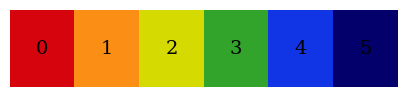

In [3]:
from cmap import Colormap
# cmap = Colormap('colorcet:CET_R1')
# cmap_array = cmap(np.linspace(0, 1, 256))

# entries = 6
# indices = np.linspace(0, len(cmap_array)-1, entries).astype(int)
# colors = cmap_array[indices][::-1]

cmap = Colormap('colorcet:CET_R4')
colors = cmap(np.linspace(0, 1, 6))

colors = colors[::-1]

# Display for visualization
large_font = 14  # font size for labels
plt.figure(figsize=(5, 1))
plt.imshow([colors], aspect='auto')

for i in range(len(colors)):  # one less because we skipped first color
    plt.annotate(i, (i, 0), color='k', fontsize=large_font, ha='center', va='center')

plt.gca().set_axis_off()

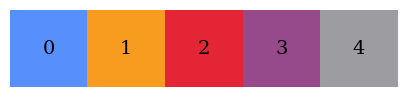

In [4]:
from cmap import Colormap
# cmap = Colormap('colorcet:CET_R1')
# cmap_array = cmap(np.linspace(0, 1, 256))

# entries = 6
# indices = np.linspace(0, len(cmap_array)-1, entries).astype(int)
# colors = cmap_array[indices][::-1]

cmap = Colormap('petroff:petroff6')
colors = cmap(np.linspace(0, 1, 6))

colors = colors[:-1]

# Display for visualization
large_font = 14  # font size for labels
plt.figure(figsize=(5, 1))
plt.imshow([colors], aspect='auto')

for i in range(len(colors)):  # one less because we skipped first color
    plt.annotate(i, (i, 0), color='k', fontsize=large_font, ha='center', va='center')

plt.gca().set_axis_off()

### Styrofoam batch
Now includes samples previously fielded in SO SATp2

In [5]:
tf_cfg = TFC(
    window=window,
    window_size=window_size,
    mask_bounds=mask_bounds,
    layout='reference_included'
)

tf_cfg2 = TFC(
    window=window,
    window_size=window_size,
    mask_bounds=mask_bounds,
    layout='separate_files'
)

path = './data/20260518/'

styro_45o3mm = TFA(path, 'satp2_site_sample4_1_45o3mm_2210-2410ps_100avgs', 'open_2210-2410ps_100avgs', config=tf_cfg2)

path = './data/20260529/'
base = 'open2_1850-2050ps_100avgs'

styro_5o6mm = TFA(path, 'SATp2_site_sample4_5o6mm_1850-2050ps_100avgs', base, config=tf_cfg2)
styro_16o9mm = TFA(path, 'SATp2_site_sample4_16o9mm_1850-2050ps_100avgs', base, config=tf_cfg2)

# path = './data/20260605/' #Check the repeatability of the thin styrofoams

# styro_0o8mm  = TFA(path, 'styro_thin1_0o8mm_1850-2050ps_100avgs', config=tf_cfg)
# styro_1o5mm  = TFA(path, 'styro_thin2_1o5mm_1850-2050ps_100avgs', config=tf_cfg)

path = './data/20260630/' #Check the repeatability of the thin styrofoams

styro_1o4mm = TFA(path, 'styro_satp2_1o4mm_1800-2000ps_100avgs', config=tf_cfg)
styro_3o0mm = TFA(path, 'styro_satp2_3o0mm_1800-2000ps_100avgs', config=tf_cfg)
styro_5o8mm = TFA(path, 'styro_satp2_5o8mm_1800-2000ps_100avgs', config=tf_cfg)
styro_6o1mm = TFA(path, 'styro_ucsd_6o1mm_1800-2000ps_100avgs', config=tf_cfg)
styro_16o2mm = TFA(path, 'styro_satp2_16o2mm_1800-2000ps_100avgs', config=tf_cfg)
styro_42o3mm = TFA(path, 'styro_ucsd_42o3mm_1800-2000ps_100avgs', config=tf_cfg)

## Frequency domain data for Styrofoam

# f_0o8mm,  t_0o8mm,  ut_0o8mm,  mask_0o8mm,  err_0o8mm,  boxnum_0o8mm  = styro_0o8mm.get_smoothed_spectra()
f_1o4mm,  t_1o4mm,  ut_1o4mm,  mask_1o4mm,  err_1o4mm,  boxnum_1o4mm  = styro_1o4mm.get_smoothed_spectra()
# f_1o5mm,  t_1o5mm,  ut_1o5mm,  mask_1o5mm,  err_1o5mm,  boxnum_1o5mm  = styro_1o5mm.get_smoothed_spectra()
f_3o0mm,  t_3o0mm,  ut_3o0mm,  mask_3o0mm,  err_3o0mm,  boxnum_3o0mm  = styro_3o0mm.get_smoothed_spectra()
f_5o6mm,  t_5o6mm,  ut_5o6mm,  mask_5o6mm,  err_5o6mm,  boxnum_5o6mm  = styro_5o6mm.get_smoothed_spectra()
f_5o8mm,  t_5o8mm,  ut_5o8mm,  mask_5o8mm,  err_5o8mm,  boxnum_5o8mm  = styro_5o8mm.get_smoothed_spectra()
f_6o1mm,  t_6o1mm,  ut_6o1mm,  mask_6o1mm,  err_6o1mm,  boxnum_6o1mm  = styro_6o1mm.get_smoothed_spectra()
f_16o2mm, t_16o2mm, ut_16o2mm, mask_16o2mm, err_16o2mm, boxnum_16o2mm = styro_16o2mm.get_smoothed_spectra()
f_16o9mm, t_16o9mm, ut_16o9mm, mask_16o9mm, err_16o9mm, boxnum_16o9mm = styro_16o9mm.get_smoothed_spectra()
f_42o3mm, t_42o3mm, ut_42o3mm, mask_42o3mm, err_42o3mm, boxnum_42o3mm = styro_42o3mm.get_smoothed_spectra()
f_45o3mm, t_45o3mm, ut_45o3mm, mask_45o3mm, err_45o3mm, boxnum_45o3mm = styro_45o3mm.get_smoothed_spectra()

## Time domain data for Styrofoam
# T_0o8mm,  pc_0o8mm  = styro_0o8mm.get_sample_pulse()
T_1o4mm,  pc_1o4mm  = styro_1o4mm.get_sample_pulse()
# T_1o5mm,  pc_1o5mm  = styro_1o5mm.get_sample_pulse()
T_3o0mm,  pc_3o0mm  = styro_3o0mm.get_sample_pulse()
T_5o6mm,  pc_5o6mm  = styro_5o6mm.get_sample_pulse()
T_5o8mm,  pc_5o8mm  = styro_5o8mm.get_sample_pulse()
T_6o1mm,  pc_6o1mm  = styro_6o1mm.get_sample_pulse()
T_16o2mm, pc_16o2mm = styro_16o2mm.get_sample_pulse()
T_16o9mm, pc_16o9mm = styro_16o9mm.get_sample_pulse()
T_42o3mm, pc_42o3mm = styro_42o3mm.get_sample_pulse()
T_45o3mm, pc_45o3mm = styro_45o3mm.get_sample_pulse()

# Phase data for Styrofoam
# phase_diff_0o8mm,  n_ulim_0o8mm  = styro_0o8mm.get_phase_diff(max_smear_bins=2)
phase_diff_1o4mm,  n_ulim_1o4mm  = styro_1o4mm.get_phase_diff(max_smear_bins=2)
# phase_diff_1o5mm,  n_ulim_1o5mm  = styro_1o5mm.get_phase_diff(max_smear_bins=2)
phase_diff_3o0mm,  n_ulim_3o0mm  = styro_3o0mm.get_phase_diff(max_smear_bins=2)
phase_diff_5o6mm,  n_ulim_5o6mm  = styro_5o6mm.get_phase_diff(max_smear_bins=2)
phase_diff_5o8mm,  n_ulim_5o8mm  = styro_5o8mm.get_phase_diff(max_smear_bins=2)
phase_diff_6o1mm,  n_ulim_6o1mm  = styro_6o1mm.get_phase_diff(max_smear_bins=2)
phase_diff_16o2mm, n_ulim_16o2mm = styro_16o2mm.get_phase_diff(max_smear_bins=2)
phase_diff_16o9mm, n_ulim_16o9mm = styro_16o9mm.get_phase_diff(max_smear_bins=2)
phase_diff_42o3mm, n_ulim_42o3mm = styro_42o3mm.get_phase_diff(max_smear_bins=2)
phase_diff_45o3mm, n_ulim_45o3mm = styro_45o3mm.get_phase_diff(max_smear_bins=2)

Styrofoam_batch = {}

# Styrofoam_batch["Styrofoam 0.08 cm"] = {'f': f_0o8mm,  't': t_0o8mm,  'ut': ut_0o8mm,  'mask': mask_0o8mm,  'err': err_0o8mm,  'boxnum': boxnum_0o8mm,  'T': T_0o8mm,  'pc': pc_0o8mm,  'phase_diff': phase_diff_0o8mm,  'n_ulim': n_ulim_0o8mm,  'width': 0.08}
Styrofoam_batch["Styrofoam 0.14 cm"] = {'f': f_1o4mm,  't': t_1o4mm,  'ut': ut_1o4mm,  'mask': mask_1o4mm,  'err': err_1o4mm,  'boxnum': boxnum_1o4mm,  'T': T_1o4mm,  'pc': pc_1o4mm,  'phase_diff': phase_diff_1o4mm,  'n_ulim': n_ulim_1o4mm,  'width': 0.14}
# Styrofoam_batch["Styrofoam 0.15 cm"] = {'f': f_1o5mm,  't': t_1o5mm,  'ut': ut_1o5mm,  'mask': mask_1o5mm,  'err': err_1o5mm,  'boxnum': boxnum_1o5mm,  'T': T_1o5mm,  'pc': pc_1o5mm,  'phase_diff': phase_diff_1o5mm,  'n_ulim': n_ulim_1o5mm,  'width': 0.15}
Styrofoam_batch["Styrofoam 0.30 cm"] = {'f': f_3o0mm,  't': t_3o0mm,  'ut': ut_3o0mm,  'mask': mask_3o0mm,  'err': err_3o0mm,  'boxnum': boxnum_3o0mm,  'T': T_3o0mm,  'pc': pc_3o0mm,  'phase_diff': phase_diff_3o0mm,  'n_ulim': n_ulim_3o0mm,  'width': 0.30}
Styrofoam_batch["Styrofoam 0.56 cm"] = {'f': f_5o6mm,  't': t_5o6mm,  'ut': ut_5o6mm,  'mask': mask_5o6mm,  'err': err_5o6mm,  'boxnum': boxnum_5o6mm,  'T': T_5o6mm,  'pc': pc_5o6mm,  'phase_diff': phase_diff_5o6mm,  'n_ulim': n_ulim_5o6mm,  'width': 0.56}
Styrofoam_batch["Styrofoam 0.58 cm"] = {'f': f_5o8mm,  't': t_5o8mm,  'ut': ut_5o8mm,  'mask': mask_5o8mm,  'err': err_5o8mm,  'boxnum': boxnum_5o8mm,  'T': T_5o8mm,  'pc': pc_5o8mm,  'phase_diff': phase_diff_5o8mm,  'n_ulim': n_ulim_5o8mm,  'width': 0.58}
Styrofoam_batch["Styrofoam 0.61 cm"] = {'f': f_6o1mm,  't': t_6o1mm,  'ut': ut_6o1mm,  'mask': mask_6o1mm,  'err': err_6o1mm,  'boxnum': boxnum_6o1mm,  'T': T_6o1mm,  'pc': pc_6o1mm,  'phase_diff': phase_diff_6o1mm,  'n_ulim': n_ulim_6o1mm,  'width': 0.61}
Styrofoam_batch["Styrofoam 1.62 cm"] = {'f': f_16o2mm, 't': t_16o2mm, 'ut': ut_16o2mm, 'mask': mask_16o2mm, 'err': err_16o2mm, 'boxnum': boxnum_16o2mm, 'T': T_16o2mm, 'pc': pc_16o2mm, 'phase_diff': phase_diff_16o2mm, 'n_ulim': n_ulim_16o2mm, 'width': 1.62}
Styrofoam_batch["Styrofoam 1.69 cm"] = {'f': f_16o9mm, 't': t_16o9mm, 'ut': ut_16o9mm, 'mask': mask_16o9mm, 'err': err_16o9mm, 'boxnum': boxnum_16o9mm, 'T': T_16o9mm, 'pc': pc_16o9mm, 'phase_diff': phase_diff_16o9mm, 'n_ulim': n_ulim_16o9mm, 'width': 1.69}
Styrofoam_batch["Styrofoam 4.23 cm"] = {'f': f_42o3mm, 't': t_42o3mm, 'ut': ut_42o3mm, 'mask': mask_42o3mm, 'err': err_42o3mm, 'boxnum': boxnum_42o3mm, 'T': T_42o3mm, 'pc': pc_42o3mm, 'phase_diff': phase_diff_42o3mm, 'n_ulim': n_ulim_42o3mm, 'width': 4.23}
Styrofoam_batch["Styrofoam 4.53 cm"] = {'f': f_45o3mm, 't': t_45o3mm, 'ut': ut_45o3mm, 'mask': mask_45o3mm, 'err': err_45o3mm, 'boxnum': boxnum_45o3mm, 'T': T_45o3mm, 'pc': pc_45o3mm, 'phase_diff': phase_diff_45o3mm, 'n_ulim': n_ulim_45o3mm, 'width': 4.53}

batches['Styrofoam_batch1'] = Styrofoam_batch

### HD30_batch1

In [6]:
# TeraFlashAnalyzer Instances for HD30_batch1
path = './data/20251216/'
penn_3o47mm    = TFA(path, 'HD30_1x0o125in_3o47mm_penn_1675-1875ps_100avgs', config=tf_cfg)

path = './data/20260212'
penn_6o51mm  = TFA(path, 'hd30_penn_6o51mm_1400-1600ps_100avgs', config=tf_cfg) # 2x1/8"
penn_27o6mm  = TFA(path, 'hd30_penn_27o60mm_1400-1600ps_100avgs', config=tf_cfg) # 8x1/8"
penn_30o94mm = TFA(path, 'hd30_penn_30o94mm_1400-1600ps_100avgs', config=tf_cfg) # 10x1/8

# Frequency domain data for HD30_batch1
f_3o47mm,  t_3o47mm,  ut_3o47mm,  mask_3o47mm,  err_3o47mm,  boxnum_3o47mm  = penn_3o47mm.get_smoothed_spectra()
f_6o51mm,  t_6o51mm,  ut_6o51mm,  mask_6o51mm,  err_6o51mm,  boxnum_6o51mm  = penn_6o51mm.get_smoothed_spectra()
f_27o6mm,  t_27o6mm,  ut_27o6mm,  mask_27o6mm,  err_27o6mm,  boxnum_27o6mm  = penn_27o6mm.get_smoothed_spectra()
f_30o94mm, t_30o94mm, ut_30o94mm, mask_30o94mm, err_30o94mm, boxnum_30o94mm = penn_30o94mm.get_smoothed_spectra()

# Time domain data for HD30_batch1
T_3o47mm,  pc_3o47mm  = penn_3o47mm.get_sample_pulse()
T_6o51mm,  pc_6o51mm  = penn_6o51mm.get_sample_pulse()
T_27o6mm,  pc_27o6mm  = penn_27o6mm.get_sample_pulse()
T_30o94mm, pc_30o94mm = penn_30o94mm.get_sample_pulse()

# Phase data for HD30_batch1
phase_diff_3o47mm,  n_ulim_3o47mm  = penn_3o47mm.get_phase_diff(max_smear_bins=2)
phase_diff_6o51mm,  n_ulim_6o51mm  = penn_6o51mm.get_phase_diff(max_smear_bins=2)
phase_diff_27o6mm,  n_ulim_27o6mm  = penn_27o6mm.get_phase_diff(max_smear_bins=2)
phase_diff_30o94mm, n_ulim_30o94mm = penn_30o94mm.get_phase_diff(max_smear_bins=2)

HD30_batch1 = {}
HD30_batch1['HD30 batch1 0.35 cm'] = {'f': f_3o47mm,  't': t_3o47mm,  'ut': ut_3o47mm,  'mask': mask_3o47mm,  'err': err_3o47mm,  'boxnum': boxnum_3o47mm,  'T': T_3o47mm,  'pc': pc_3o47mm,  'n_ulim': n_ulim_3o47mm,  'phase_diff': phase_diff_3o47mm,  'width': 0.347}
HD30_batch1['HD30 batch1 2.76 cm'] = {'f': f_27o6mm,  't': t_27o6mm,  'ut': ut_27o6mm,  'mask': mask_27o6mm,  'err': err_27o6mm,  'boxnum': boxnum_27o6mm,  'T': T_27o6mm,  'pc': pc_27o6mm,  'n_ulim': n_ulim_27o6mm,  'phase_diff': phase_diff_27o6mm,  'width': 2.76}

## Rejected 2026-10-12: the 02/12 2- and 10-sheet calipers (6.51, 30.94 mm) read 3.25 and 3.09 mm per sheet against 3.45-3.47 mm for the other two (compressed when measured); kept for the PP35-section diagnostics only
HD30_batch1_rejected = {}
HD30_batch1_rejected['HD30 batch1 0.65 cm'] = {'f': f_6o51mm,  't': t_6o51mm,  'ut': ut_6o51mm,  'mask': mask_6o51mm,  'err': err_6o51mm,  'boxnum': boxnum_6o51mm,  'T': T_6o51mm,  'pc': pc_6o51mm,  'n_ulim': n_ulim_6o51mm,  'phase_diff': phase_diff_6o51mm,  'width': 0.651}
HD30_batch1_rejected['HD30 batch1 3.09 cm'] = {'f': f_30o94mm, 't': t_30o94mm, 'ut': ut_30o94mm, 'mask': mask_30o94mm, 'err': err_30o94mm, 'boxnum': boxnum_30o94mm, 'T': T_30o94mm, 'pc': pc_30o94mm, 'n_ulim': n_ulim_30o94mm, 'phase_diff': phase_diff_30o94mm, 'width': 3.094}

batches['HD30_batch1'] = HD30_batch1

### HD30_batch2

In [7]:
path = './data/20251216/'

## TeraFlashAnalyzer Instances for HD30_batch2
cornell_3o65mm = TFA(path, 'hd30_1x0o125in_3o65mm_cornell_1675-1875ps_100avgs', config = tf_cfg)
cornell_7o3mm  = TFA(path, 'hd30_2x0o125in_7o3mm_cornell_1675-1875ps_100avgs',  config = tf_cfg)
cornell_25o4mm = TFA(path, 'hd30_1x1in_25o4mm_cornell2_1675-1875ps_100avgs',    config = tf_cfg)

## Frequency domain data for HD30_batch2
f_3o65mm, t_3o65mm,  ut_3o65mm,  mask_3o65mm,  err_3o65mm,  boxnum_3o65mm  = cornell_3o65mm.get_smoothed_spectra()
f_7o3mm,  t_7o3mm,   ut_7o3mm,   mask_7o3mm,   err_7o3mm,   boxnum_7o3mm   = cornell_7o3mm.get_smoothed_spectra()
f_25o4mm, t_25o4mm,  ut_25o4mm,  mask_25o4mm,  err_25o4mm,  boxnum_25o4mm  = cornell_25o4mm.get_smoothed_spectra()

## Time domain data for HD30_batch2
T_3o65mm,  pc_3o65mm  = cornell_3o65mm.get_sample_pulse()
T_7o3mm,   pc_7o3mm   = cornell_7o3mm.get_sample_pulse()
T_25o4mm,  pc_25o4mm  = cornell_25o4mm.get_sample_pulse()

## Phase data for HD30_batch2
phase_diff_3o65mm, n_ulim_3o65mm = cornell_3o65mm.get_phase_diff(max_smear_bins=2)
phase_diff_7o3mm,  n_ulim_7o3mm  = cornell_7o3mm.get_phase_diff(max_smear_bins=2)
phase_diff_25o4mm, n_ulim_25o4mm = cornell_25o4mm.get_phase_diff(max_smear_bins=2)

HD30_batch2 = {}

HD30_batch2['HD30 batch2 0.37 cm'] = {'f': f_3o65mm, 't': t_3o65mm, 'ut': ut_3o65mm, 'mask': mask_3o65mm, 'err': err_3o65mm, 'boxnum': boxnum_3o65mm, 'T': T_3o65mm, 'pc': pc_3o65mm, 'n_ulim': n_ulim_3o65mm, 'phase_diff': phase_diff_3o65mm, 'width': 0.365}
HD30_batch2['HD30 batch2 0.73 cm'] = {'f': f_7o3mm,  't': t_7o3mm,  'ut': ut_7o3mm,  'mask': mask_7o3mm,  'err': err_7o3mm,  'boxnum': boxnum_7o3mm,  'T': T_7o3mm,  'pc': pc_7o3mm,  'n_ulim': n_ulim_7o3mm,  'phase_diff': phase_diff_7o3mm,  'width': 0.73}
HD30_batch2['HD30 batch2 2.54 cm'] = {'f': f_25o4mm, 't': t_25o4mm, 'ut': ut_25o4mm, 'mask': mask_25o4mm, 'err': err_25o4mm, 'boxnum': boxnum_25o4mm, 'T': T_25o4mm, 'pc': pc_25o4mm, 'n_ulim': n_ulim_25o4mm, 'phase_diff': phase_diff_25o4mm, 'width': 2.54}

batches['HD30_batch2'] = HD30_batch2

### HD30_batch3
Deployed for ASO

In [8]:
path = './data/20251216/'

site_3o58mm    = TFA(path, 'HD30_1x0o125in_3o58mm_site_1675-1875ps_100avgs',  config=tf_cfg)
site_7o18mm    = TFA(path, 'HD30_2x0o125in_7o18mm_site_1675-1875ps_100avgs',  config=tf_cfg)
site_10o86mm   = TFA(path, 'HD30_3x0o125in_10o86mm_site_1675-1875ps_100avgs', config=tf_cfg)
site_25o4mm    = TFA(path, 'HD30_1x1in_25o4mm_site_1675-1875ps_100avgs',      config=tf_cfg)
site_50o9mm    = TFA(path, 'HD30_2x1in_50o9mm_site_1675-1875ps_100avgs',      config=tf_cfg)

## Frequency domain data for HD30_batch3 
f_3o58mm,  t_3o58mm,  ut_3o58mm,  mask_3o58mm,  err_3o58mm,  boxnum_3o58mm  = site_3o58mm.get_smoothed_spectra()
f_7o18mm,  t_7o18mm,  ut_7o18mm,  mask_7o18mm,  err_7o18mm,  boxnum_7o18mm  = site_7o18mm.get_smoothed_spectra()
f_10o86mm, t_10o86mm, ut_10o86mm, mask_10o86mm, err_10o86mm, boxnum_10o86mm = site_10o86mm.get_smoothed_spectra()
f_25o4mm,  t_25o4mm,  ut_25o4mm,  mask_25o4mm,  err_25o4mm,  boxnum_25o4mm  = site_25o4mm.get_smoothed_spectra()
f_50o9mm,  t_50o9mm,  ut_50o9mm,  mask_50o9mm,  err_50o9mm,  boxnum_50o9mm  = site_50o9mm.get_smoothed_spectra()

## Time domain data for HD30_batch3 
T_3o58mm,  pc_3o58mm  = site_3o58mm.get_sample_pulse()
T_7o18mm,  pc_7o18mm  = site_7o18mm.get_sample_pulse()
T_10o86mm, pc_10o86mm = site_10o86mm.get_sample_pulse()
T_25o4mm,  pc_25o4mm  = site_25o4mm.get_sample_pulse()
T_50o9mm,  pc_50o9mm  = site_50o9mm.get_sample_pulse()

# Phase HD30_batch3
phase_diff_3o58mm, n_ulim_3o58mm   = site_3o58mm.get_phase_diff(max_smear_bins=2)
phase_diff_7o18mm, n_ulim_7o18mm   = site_7o18mm.get_phase_diff(max_smear_bins=2)
phase_diff_10o86mm, n_ulim_10o86mm = site_10o86mm.get_phase_diff(max_smear_bins=2)
phase_diff_25o4mm, n_ulim_25o4mm   = site_25o4mm.get_phase_diff(max_smear_bins=2)
phase_diff_50o9mm, n_ulim_50o9mm   = site_50o9mm.get_phase_diff(max_smear_bins=2)

HD30_batch3 = {}

HD30_batch3['HD30 batch3 0.36 cm'] = {'f': f_3o58mm,  't': t_3o58mm,  'ut': ut_3o58mm,  'mask': mask_3o58mm,  'err': err_3o58mm,  'boxnum': boxnum_3o58mm,  'T': T_3o58mm,  'pc': pc_3o58mm,  'phase_diff': phase_diff_3o58mm,  'n_ulim': n_ulim_3o58mm,  'width': 0.358}
HD30_batch3['HD30 batch3 0.72 cm'] = {'f': f_7o18mm,  't': t_7o18mm,  'ut': ut_7o18mm,  'mask': mask_7o18mm,  'err': err_7o18mm,  'boxnum': boxnum_7o18mm,  'T': T_7o18mm,  'pc': pc_7o18mm,  'phase_diff': phase_diff_7o18mm,  'n_ulim': n_ulim_7o18mm,  'width': 0.718}
HD30_batch3['HD30 batch3 1.09 cm'] = {'f': f_10o86mm, 't': t_10o86mm, 'ut': ut_10o86mm, 'mask': mask_10o86mm, 'err': err_10o86mm, 'boxnum': boxnum_10o86mm, 'T': T_10o86mm, 'pc': pc_10o86mm, 'phase_diff': phase_diff_10o86mm, 'n_ulim': n_ulim_10o86mm, 'width': 1.086}
HD30_batch3['HD30 batch3 2.54 cm'] = {'f': f_25o4mm,  't': t_25o4mm,  'ut': ut_25o4mm,  'mask': mask_25o4mm,  'err': err_25o4mm,  'boxnum': boxnum_25o4mm,  'T': T_25o4mm,  'pc': pc_25o4mm,  'phase_diff': phase_diff_25o4mm,  'n_ulim': n_ulim_25o4mm,  'width': 2.54}
HD30_batch3['HD30 batch3 5.09 cm'] = {'f': f_50o9mm,  't': t_50o9mm,  'ut': ut_50o9mm,  'mask': mask_50o9mm,  'err': err_50o9mm,  'boxnum': boxnum_50o9mm,  'T': T_50o9mm,  'pc': pc_50o9mm,  'phase_diff': phase_diff_50o9mm,  'n_ulim': n_ulim_50o9mm,  'width': 5.09}

batches['HD30_batch3'] = HD30_batch3

### Alternative Zotefoams
Lower and higher density formulations suggested and sourced by Cornell

In [9]:
path = './data/20251117/' #Path to the data directory

# Mask diffuse scatter regions in HD foams
mask_bounds_HD80 = ((0, 150), (545, 570), (740, 770), (1080, 1245), (1390, 10000))
mask_bounds_HD110 = ((0, 150), (500, 10000))

tf_cfg_HD80  = TFC(window=window, window_size=window_size, mask_bounds=mask_bounds_HD80,  layout='reference_included')
tf_cfg_HD110 = TFC(window=window, window_size=window_size, mask_bounds=mask_bounds_HD110, layout='reference_included')

LD15_1in  = TFA(path, 'LD15_1590-1790ps_1000avgs',  config=tf_cfg)
LD24_1in  = TFA(path, 'LD24_1590-1790ps_1000avgs',  config=tf_cfg)
HD80_1in  = TFA(path, 'HD80_1590-1790ps_1000avgs',  config=tf_cfg_HD80)
HD110_1in = TFA(path, 'HD110_1590-1790ps_1000avgs', config=tf_cfg_HD110)

path = './data/cornell/'

# We use a legacy TeraScan measurement for HD60, HD60 was firmly rejected before the TeraFlash was installed.
HD60_1in  = TSA(path,   
                'TestData_2050225_Zotefoam_HD60_0p8in_300K_Sample_100to1000GHz_Step200MHz_Scan_0001.dat',  
                'TestData_2050225_Zotefoam_HD60_0p8in_300K_ClrBg_100to1000GHz_Step200MHz_Scan_0001.dat',
                config=TSC(window=window, window_size=window_size, mask_bounds=mask_bounds, fiber_stretcher=True))

path = './data/20260630/'

LD15_UT_3o0mm  = TFA(path, 'LD15_batch2_3o0mm_1800-2000ps_100avgs',  config=tf_cfg)
LD15_UT_6o0mm  = TFA(path, 'LD15_batch2_6o0mm_1800-2000ps_100avgs',  config=tf_cfg)
LD15_UT_8o9mm  = TFA(path, 'LD15_batch2_8o9mm_1800-2000ps_100avgs',  config=tf_cfg)
LD24_UT_3o1mm  = TFA(path, 'LD24_batch2_3o1mm_1800-2000ps_100avgs',  config=tf_cfg)
LD24_UT_6o3mm  = TFA(path, 'LD24_batch2_6o3mm_1800-2000ps_100avgs',  config=tf_cfg)
LD24_UT_9o4mm  = TFA(path, 'LD24_batch2_9o4mm_1800-2000ps_100avgs',  config=tf_cfg)
LD24_UT_12o5mm = TFA(path, 'LD24_batch2_12o5mm_1800-2000ps_100avgs', config=tf_cfg)

path = './data/20260718/'

LD24_cornell_3o6mm  = TFA(path, 'LD24_cornell_3o60mm_1800-2000ps_100avgs',  config=tf_cfg)
LD24_cornell_7o2mm  = TFA(path, 'LD24_cornell_7o21mm_1800-2000ps_100avgs',  config=tf_cfg)
LD24_cornell_10o9mm = TFA(path, 'LD24_cornell_10o87mm_1800-2000ps_100avgs', config=tf_cfg)
LD24_cornell_14o5mm = TFA(path, 'LD24_cornell_14o51mm_1800-2000ps_100avgs', config=tf_cfg)
LD24_cornell_18o1mm = TFA(path, 'LD24_cornell_18o13mm_1800-2000ps_100avgs', config=tf_cfg)
LD24_cornell_21o7mm = TFA(path, 'LD24_cornell_21o72mm_1800-2000ps_100avgs', config=tf_cfg)

HD80_3o49mm         = TFA(path, 'HD80_3o49mm_1800-2000ps_100avgs',  config=tf_cfg_HD80)
HD80_7o08mm         = TFA(path, 'HD80_7o08mm_1800-2000ps_100avgs',  config=tf_cfg_HD80)
HD80_10o62mm        = TFA(path, 'HD80_10o62mm_1800-2000ps_100avgs', config=tf_cfg_HD80)
HD80_14o24mm        = TFA(path, 'HD80_14o24mm_1800-2000ps_100avgs', config=tf_cfg_HD80)
HD80_17o79mm        = TFA(path, 'HD80_17o79mm_1800-2000ps_100avgs', config=tf_cfg_HD80)
HD80_21o35mm        = TFA(path, 'HD80_21o35mm_1800-2000ps_100avgs', config=tf_cfg_HD80)

HD110_2o99mm        = TFA(path, 'HD110_2o99mm_1800-2000ps_100avgs',  config=tf_cfg_HD110)
HD110_5o99mm        = TFA(path, 'HD110_5o99mm_1800-2000ps_100avgs',  config=tf_cfg_HD110)
HD110_8o97mm        = TFA(path, 'HD110_8o97mm_1800-2000ps_100avgs',  config=tf_cfg_HD110)
HD110_11o96mm       = TFA(path, 'HD110_11o96mm_1800-2000ps_100avgs', config=tf_cfg_HD110)


## Frequency-domain data
f_LD15,      t_LD15,      ut_LD15,      mask_LD15,      err_LD15,      boxnum_LD15     = LD15_1in.get_smoothed_spectra()
f_LD24,      t_LD24,      ut_LD24,      mask_LD24,      err_LD24,      boxnum_LD24     = LD24_1in.get_smoothed_spectra()
f_HD60,      t_HD60,      ut_HD60,      mask_HD60,      err_HD60,      boxnum_HD60     = HD60_1in.get_smoothed_spectra()
f_HD80,      t_HD80,      ut_HD80,      mask_HD80,      err_HD80,      boxnum_HD80     = HD80_1in.get_smoothed_spectra()
f_HD110,     t_HD110,     ut_HD110,     mask_HD110,     err_HD110,     boxnum_HD110    = HD110_1in.get_smoothed_spectra()

f_LD15_UT_3o0mm,  t_LD15_UT_3o0mm,  ut_LD15_UT_3o0mm,  mask_LD15_UT_3o0mm,  err_LD15_UT_3o0mm,  boxnum_LD15_UT_3o0mm  = LD15_UT_3o0mm.get_smoothed_spectra()
f_LD15_UT_6o0mm,  t_LD15_UT_6o0mm,  ut_LD15_UT_6o0mm,  mask_LD15_UT_6o0mm,  err_LD15_UT_6o0mm,  boxnum_LD15_UT_6o0mm  = LD15_UT_6o0mm.get_smoothed_spectra()
f_LD15_UT_8o9mm,  t_LD15_UT_8o9mm,  ut_LD15_UT_8o9mm,  mask_LD15_UT_8o9mm,  err_LD15_UT_8o9mm,  boxnum_LD15_UT_8o9mm  = LD15_UT_8o9mm.get_smoothed_spectra()
f_LD24_UT_3o1mm,  t_LD24_UT_3o1mm,  ut_LD24_UT_3o1mm,  mask_LD24_UT_3o1mm,  err_LD24_UT_3o1mm,  boxnum_LD24_UT_3o1mm  = LD24_UT_3o1mm.get_smoothed_spectra()
f_LD24_UT_6o3mm,  t_LD24_UT_6o3mm,  ut_LD24_UT_6o3mm,  mask_LD24_UT_6o3mm,  err_LD24_UT_6o3mm,  boxnum_LD24_UT_6o3mm  = LD24_UT_6o3mm.get_smoothed_spectra()
f_LD24_UT_9o4mm,  t_LD24_UT_9o4mm,  ut_LD24_UT_9o4mm,  mask_LD24_UT_9o4mm,  err_LD24_UT_9o4mm,  boxnum_LD24_UT_9o4mm  = LD24_UT_9o4mm.get_smoothed_spectra()
f_LD24_UT_12o5mm, t_LD24_UT_12o5mm, ut_LD24_UT_12o5mm, mask_LD24_UT_12o5mm, err_LD24_UT_12o5mm, boxnum_LD24_UT_12o5mm = LD24_UT_12o5mm.get_smoothed_spectra()

f_LD24_cornell_3o6mm,  t_LD24_cornell_3o6mm,  ut_LD24_cornell_3o6mm,  mask_LD24_cornell_3o6mm,  err_LD24_cornell_3o6mm,  boxnum_LD24_cornell_3o6mm  = LD24_cornell_3o6mm.get_smoothed_spectra()
f_LD24_cornell_7o2mm,  t_LD24_cornell_7o2mm,  ut_LD24_cornell_7o2mm,  mask_LD24_cornell_7o2mm,  err_LD24_cornell_7o2mm,  boxnum_LD24_cornell_7o2mm  = LD24_cornell_7o2mm.get_smoothed_spectra()
f_LD24_cornell_10o9mm, t_LD24_cornell_10o9mm, ut_LD24_cornell_10o9mm, mask_LD24_cornell_10o9mm, err_LD24_cornell_10o9mm, boxnum_LD24_cornell_10o9mm = LD24_cornell_10o9mm.get_smoothed_spectra()
f_LD24_cornell_14o5mm, t_LD24_cornell_14o5mm, ut_LD24_cornell_14o5mm, mask_LD24_cornell_14o5mm, err_LD24_cornell_14o5mm, boxnum_LD24_cornell_14o5mm = LD24_cornell_14o5mm.get_smoothed_spectra()
f_LD24_cornell_18o1mm, t_LD24_cornell_18o1mm, ut_LD24_cornell_18o1mm, mask_LD24_cornell_18o1mm, err_LD24_cornell_18o1mm, boxnum_LD24_cornell_18o1mm = LD24_cornell_18o1mm.get_smoothed_spectra()
f_LD24_cornell_21o7mm, t_LD24_cornell_21o7mm, ut_LD24_cornell_21o7mm, mask_LD24_cornell_21o7mm, err_LD24_cornell_21o7mm, boxnum_LD24_cornell_21o7mm = LD24_cornell_21o7mm.get_smoothed_spectra()

f_HD80_3o49mm,  t_HD80_3o49mm,  ut_HD80_3o49mm,  mask_HD80_3o49mm,  err_HD80_3o49mm,  boxnum_HD80_3o49mm  = HD80_3o49mm.get_smoothed_spectra()
f_HD80_7o08mm,  t_HD80_7o08mm,  ut_HD80_7o08mm,  mask_HD80_7o08mm,  err_HD80_7o08mm,  boxnum_HD80_7o08mm  = HD80_7o08mm.get_smoothed_spectra()
f_HD80_10o62mm, t_HD80_10o62mm, ut_HD80_10o62mm, mask_HD80_10o62mm, err_HD80_10o62mm, boxnum_HD80_10o62mm = HD80_10o62mm.get_smoothed_spectra()
f_HD80_14o24mm, t_HD80_14o24mm, ut_HD80_14o24mm, mask_HD80_14o24mm, err_HD80_14o24mm, boxnum_HD80_14o24mm = HD80_14o24mm.get_smoothed_spectra()
f_HD80_17o79mm, t_HD80_17o79mm, ut_HD80_17o79mm, mask_HD80_17o79mm, err_HD80_17o79mm, boxnum_HD80_17o79mm = HD80_17o79mm.get_smoothed_spectra()
f_HD80_21o35mm, t_HD80_21o35mm, ut_HD80_21o35mm, mask_HD80_21o35mm, err_HD80_21o35mm, boxnum_HD80_21o35mm = HD80_21o35mm.get_smoothed_spectra()

f_HD110_2o99mm,  t_HD110_2o99mm,  ut_HD110_2o99mm,  mask_HD110_2o99mm,  err_HD110_2o99mm,  boxnum_HD110_2o99mm  = HD110_2o99mm.get_smoothed_spectra()
f_HD110_5o99mm,  t_HD110_5o99mm,  ut_HD110_5o99mm,  mask_HD110_5o99mm,  err_HD110_5o99mm,  boxnum_HD110_5o99mm  = HD110_5o99mm.get_smoothed_spectra()
f_HD110_8o97mm,  t_HD110_8o97mm,  ut_HD110_8o97mm,  mask_HD110_8o97mm,  err_HD110_8o97mm,  boxnum_HD110_8o97mm  = HD110_8o97mm.get_smoothed_spectra()
f_HD110_11o96mm, t_HD110_11o96mm, ut_HD110_11o96mm, mask_HD110_11o96mm, err_HD110_11o96mm, boxnum_HD110_11o96mm = HD110_11o96mm.get_smoothed_spectra()

## Time-domain data
T_LD15,     pc_LD15       = LD15_1in.get_sample_pulse()
T_LD24,     pc_LD24       = LD24_1in.get_sample_pulse()
T_HD80,     pc_HD80       = HD80_1in.get_sample_pulse()
T_HD110,    pc_HD110      = HD110_1in.get_sample_pulse()

T_LD15_UT_3o0mm,  pc_LD15_UT_3o0mm  = LD15_UT_3o0mm.get_sample_pulse()
T_LD15_UT_6o0mm,  pc_LD15_UT_6o0mm  = LD15_UT_6o0mm.get_sample_pulse()
T_LD15_UT_8o9mm,  pc_LD15_UT_8o9mm  = LD15_UT_8o9mm.get_sample_pulse()
T_LD24_UT_3o1mm,  pc_LD24_UT_3o1mm  = LD24_UT_3o1mm.get_sample_pulse()
T_LD24_UT_6o3mm,  pc_LD24_UT_6o3mm  = LD24_UT_6o3mm.get_sample_pulse()
T_LD24_UT_9o4mm,  pc_LD24_UT_9o4mm  = LD24_UT_9o4mm.get_sample_pulse()
T_LD24_UT_12o5mm, pc_LD24_UT_12o5mm = LD24_UT_12o5mm.get_sample_pulse()

T_LD24_cornell_3o6mm,  pc_LD24_cornell_3o6mm  = LD24_cornell_3o6mm.get_sample_pulse()
T_LD24_cornell_7o2mm,  pc_LD24_cornell_7o2mm  = LD24_cornell_7o2mm.get_sample_pulse()
T_LD24_cornell_10o9mm, pc_LD24_cornell_10o9mm = LD24_cornell_10o9mm.get_sample_pulse()
T_LD24_cornell_14o5mm, pc_LD24_cornell_14o5mm = LD24_cornell_14o5mm.get_sample_pulse()
T_LD24_cornell_18o1mm, pc_LD24_cornell_18o1mm = LD24_cornell_18o1mm.get_sample_pulse()
T_LD24_cornell_21o7mm, pc_LD24_cornell_21o7mm = LD24_cornell_21o7mm.get_sample_pulse()

T_HD80_3o49mm,  pc_HD80_3o49mm  = HD80_3o49mm.get_sample_pulse()
T_HD80_7o08mm,  pc_HD80_7o08mm  = HD80_7o08mm.get_sample_pulse()
T_HD80_10o62mm, pc_HD80_10o62mm = HD80_10o62mm.get_sample_pulse()
T_HD80_14o24mm, pc_HD80_14o24mm = HD80_14o24mm.get_sample_pulse()
T_HD80_17o79mm, pc_HD80_17o79mm = HD80_17o79mm.get_sample_pulse()
T_HD80_21o35mm, pc_HD80_21o35mm = HD80_21o35mm.get_sample_pulse()

T_HD110_2o99mm,  pc_HD110_2o99mm  = HD110_2o99mm.get_sample_pulse()
T_HD110_5o99mm,  pc_HD110_5o99mm  = HD110_5o99mm.get_sample_pulse()
T_HD110_8o97mm,  pc_HD110_8o97mm  = HD110_8o97mm.get_sample_pulse()
T_HD110_11o96mm, pc_HD110_11o96mm = HD110_11o96mm.get_sample_pulse()

##Phase data
phase_diff_LD15,  n_ulim_LD15  = LD15_1in.get_phase_diff(max_smear_bins=2)
phase_diff_LD24,  n_ulim_LD24  = LD24_1in.get_phase_diff(max_smear_bins=2)
phase_diff_HD60,  n_ulim_HD60  = HD60_1in.get_phase_diff(max_smear_bins=2, unwrap=True)
phase_diff_HD80,  n_ulim_HD80  = HD80_1in.get_phase_diff(max_smear_bins=2)
phase_diff_HD110, n_ulim_HD110 = HD110_1in.get_phase_diff(max_smear_bins=2)
phase_diff_LD15_UT_3o0mm,  n_ulim_LD15_UT_3o0mm  = LD15_UT_3o0mm.get_phase_diff(max_smear_bins=2)
phase_diff_LD15_UT_6o0mm,  n_ulim_LD15_UT_6o0mm  = LD15_UT_6o0mm.get_phase_diff(max_smear_bins=2)
phase_diff_LD15_UT_8o9mm,  n_ulim_LD15_UT_8o9mm  = LD15_UT_8o9mm.get_phase_diff(max_smear_bins=2)
phase_diff_LD24_UT_3o1mm,  n_ulim_LD24_UT_3o1mm  = LD24_UT_3o1mm.get_phase_diff(max_smear_bins=2)
phase_diff_LD24_UT_6o3mm,  n_ulim_LD24_UT_6o3mm  = LD24_UT_6o3mm.get_phase_diff(max_smear_bins=2)
phase_diff_LD24_UT_9o4mm,  n_ulim_LD24_UT_9o4mm  = LD24_UT_9o4mm.get_phase_diff(max_smear_bins=2)
phase_diff_LD24_UT_12o5mm, n_ulim_LD24_UT_12o5mm = LD24_UT_12o5mm.get_phase_diff(max_smear_bins=2)

phase_diff_LD24_cornell_3o6mm,  n_ulim_LD24_cornell_3o6mm  = LD24_cornell_3o6mm.get_phase_diff(max_smear_bins=2)
phase_diff_LD24_cornell_7o2mm,  n_ulim_LD24_cornell_7o2mm  = LD24_cornell_7o2mm.get_phase_diff(max_smear_bins=2)
phase_diff_LD24_cornell_10o9mm, n_ulim_LD24_cornell_10o9mm = LD24_cornell_10o9mm.get_phase_diff(max_smear_bins=2)
phase_diff_LD24_cornell_14o5mm, n_ulim_LD24_cornell_14o5mm = LD24_cornell_14o5mm.get_phase_diff(max_smear_bins=2)
phase_diff_LD24_cornell_18o1mm, n_ulim_LD24_cornell_18o1mm = LD24_cornell_18o1mm.get_phase_diff(max_smear_bins=2)
phase_diff_LD24_cornell_21o7mm, n_ulim_LD24_cornell_21o7mm = LD24_cornell_21o7mm.get_phase_diff(max_smear_bins=2)

phase_diff_HD80_3o49mm,  n_ulim_HD80_3o49mm  = HD80_3o49mm.get_phase_diff(max_smear_bins=2)
phase_diff_HD80_7o08mm,  n_ulim_HD80_7o08mm  = HD80_7o08mm.get_phase_diff(max_smear_bins=2)
phase_diff_HD80_10o62mm, n_ulim_HD80_10o62mm = HD80_10o62mm.get_phase_diff(max_smear_bins=2)
phase_diff_HD80_14o24mm, n_ulim_HD80_14o24mm = HD80_14o24mm.get_phase_diff(max_smear_bins=2)
phase_diff_HD80_17o79mm, n_ulim_HD80_17o79mm = HD80_17o79mm.get_phase_diff(max_smear_bins=2)
phase_diff_HD80_21o35mm, n_ulim_HD80_21o35mm = HD80_21o35mm.get_phase_diff(max_smear_bins=2)

phase_diff_HD110_2o99mm,  n_ulim_HD110_2o99mm  = HD110_2o99mm.get_phase_diff(max_smear_bins=2)
phase_diff_HD110_5o99mm,  n_ulim_HD110_5o99mm  = HD110_5o99mm.get_phase_diff(max_smear_bins=2)
phase_diff_HD110_8o97mm,  n_ulim_HD110_8o97mm  = HD110_8o97mm.get_phase_diff(max_smear_bins=2)
phase_diff_HD110_11o96mm, n_ulim_HD110_11o96mm = HD110_11o96mm.get_phase_diff(max_smear_bins=2)

## ACTIVE DATA DICTIONARY

LD15_batch1 = {}
LD15_batch1['LD15_batch1'] = {'f': f_LD15,      't': t_LD15,      'ut': ut_LD15,      'mask': mask_LD15,      'err': err_LD15,      'boxnum': boxnum_LD15,      'T': T_LD15,      'pc': pc_LD15,       'n_ulim': n_ulim_LD15,       'phase_diff': phase_diff_LD15,       'width': 2.65}


LD15_batch2 = {}

LD15_batch2['LD15 batch2 0.30 cm'] = {'f': f_LD15_UT_3o0mm,  't': t_LD15_UT_3o0mm,  'ut': ut_LD15_UT_3o0mm,  'mask': mask_LD15_UT_3o0mm,  'err': err_LD15_UT_3o0mm,  'boxnum': boxnum_LD15_UT_3o0mm,  'T': T_LD15_UT_3o0mm,  'pc': pc_LD15_UT_3o0mm,  'n_ulim': n_ulim_LD15_UT_3o0mm,  'phase_diff': phase_diff_LD15_UT_3o0mm,  'width': 0.30}
## Cut from the .spectr analysis: the exported phase carries a constant offset, so n drifts with f. The pulse-FFT phase
## of the gated analysis has no offset (n matches the batch) and the attenuation agrees, so it is used when GATE_END_PS is set.
if GATE_END_PS is not None:
    LD15_batch2['LD15 batch2 0.60 cm'] = {'f': f_LD15_UT_6o0mm,  't': t_LD15_UT_6o0mm,  'ut': ut_LD15_UT_6o0mm,  'mask': mask_LD15_UT_6o0mm,  'err': err_LD15_UT_6o0mm,  'boxnum': boxnum_LD15_UT_6o0mm,  'T': T_LD15_UT_6o0mm,  'pc': pc_LD15_UT_6o0mm,  'n_ulim': n_ulim_LD15_UT_6o0mm,  'phase_diff': phase_diff_LD15_UT_6o0mm,  'width': 0.60}
LD15_batch2['LD15 batch2 0.89 cm'] = {'f': f_LD15_UT_8o9mm,  't': t_LD15_UT_8o9mm,  'ut': ut_LD15_UT_8o9mm,  'mask': mask_LD15_UT_8o9mm,  'err': err_LD15_UT_8o9mm,  'boxnum': boxnum_LD15_UT_8o9mm,  'T': T_LD15_UT_8o9mm,  'pc': pc_LD15_UT_8o9mm,  'n_ulim': n_ulim_LD15_UT_8o9mm,  'phase_diff': phase_diff_LD15_UT_8o9mm,  'width': 0.89}

LD24_batch1 = {}

LD24_batch1['LD24 batch1 0.36 cm'] = {'f': f_LD24_cornell_3o6mm,  't': t_LD24_cornell_3o6mm,  'ut': ut_LD24_cornell_3o6mm,  'mask': mask_LD24_cornell_3o6mm,  'err': err_LD24_cornell_3o6mm,  'boxnum': boxnum_LD24_cornell_3o6mm,  'T': T_LD24_cornell_3o6mm,  'pc': pc_LD24_cornell_3o6mm,  'n_ulim': n_ulim_LD24_cornell_3o6mm,  'phase_diff': phase_diff_LD24_cornell_3o6mm,  'width': 0.360}
LD24_batch1['LD24 batch1 0.72 cm'] = {'f': f_LD24_cornell_7o2mm,  't': t_LD24_cornell_7o2mm,  'ut': ut_LD24_cornell_7o2mm,  'mask': mask_LD24_cornell_7o2mm,  'err': err_LD24_cornell_7o2mm,  'boxnum': boxnum_LD24_cornell_7o2mm,  'T': T_LD24_cornell_7o2mm,  'pc': pc_LD24_cornell_7o2mm,  'n_ulim': n_ulim_LD24_cornell_7o2mm,  'phase_diff': phase_diff_LD24_cornell_7o2mm,  'width': 0.721}
LD24_batch1['LD24 batch1 1.09 cm'] = {'f': f_LD24_cornell_10o9mm, 't': t_LD24_cornell_10o9mm, 'ut': ut_LD24_cornell_10o9mm, 'mask': mask_LD24_cornell_10o9mm, 'err': err_LD24_cornell_10o9mm, 'boxnum': boxnum_LD24_cornell_10o9mm, 'T': T_LD24_cornell_10o9mm, 'pc': pc_LD24_cornell_10o9mm, 'n_ulim': n_ulim_LD24_cornell_10o9mm, 'phase_diff': phase_diff_LD24_cornell_10o9mm, 'width': 1.087}
LD24_batch1['LD24 batch1 1.45 cm'] = {'f': f_LD24_cornell_14o5mm, 't': t_LD24_cornell_14o5mm, 'ut': ut_LD24_cornell_14o5mm, 'mask': mask_LD24_cornell_14o5mm, 'err': err_LD24_cornell_14o5mm, 'boxnum': boxnum_LD24_cornell_14o5mm, 'T': T_LD24_cornell_14o5mm, 'pc': pc_LD24_cornell_14o5mm, 'n_ulim': n_ulim_LD24_cornell_14o5mm, 'phase_diff': phase_diff_LD24_cornell_14o5mm, 'width': 1.451}
LD24_batch1['LD24 batch1 1.79 cm'] = {'f': f_LD24_cornell_18o1mm, 't': t_LD24_cornell_18o1mm, 'ut': ut_LD24_cornell_18o1mm, 'mask': mask_LD24_cornell_18o1mm, 'err': err_LD24_cornell_18o1mm, 'boxnum': boxnum_LD24_cornell_18o1mm, 'T': T_LD24_cornell_18o1mm, 'pc': pc_LD24_cornell_18o1mm, 'n_ulim': n_ulim_LD24_cornell_18o1mm, 'phase_diff': phase_diff_LD24_cornell_18o1mm, 'width': 1.813}
LD24_batch1['LD24 batch1 2.15 cm'] = {'f': f_LD24_cornell_21o7mm, 't': t_LD24_cornell_21o7mm, 'ut': ut_LD24_cornell_21o7mm, 'mask': mask_LD24_cornell_21o7mm, 'err': err_LD24_cornell_21o7mm, 'boxnum': boxnum_LD24_cornell_21o7mm, 'T': T_LD24_cornell_21o7mm, 'pc': pc_LD24_cornell_21o7mm, 'n_ulim': n_ulim_LD24_cornell_21o7mm, 'phase_diff': phase_diff_LD24_cornell_21o7mm, 'width': 2.172}

## Rejected 2026-10-12: an 11/17 one-inch piece from a less dense lot than the 07/18 sheets: 11-12 % less loss per cm at 0.6-1.6 THz and n - 1 6 % lower (1.0117 vs 1.0124); treated as HD80 2.58 cm
# LD24_batch1['LD24 batch1 2.60 cm'] = {'f': f_LD24,      't': t_LD24,      'ut': ut_LD24,      'mask': mask_LD24,      'err': err_LD24,      'boxnum': boxnum_LD24,      'T': T_LD24,      'pc': pc_LD24,       'n_ulim': n_ulim_LD24,       'phase_diff': phase_diff_LD24,       'width': 2.60}


LD24_batch2 = {}

LD24_batch2['LD24 batch2 0.31 cm'] = {'f': f_LD24_UT_3o1mm,  't': t_LD24_UT_3o1mm,  'ut': ut_LD24_UT_3o1mm,  'mask': mask_LD24_UT_3o1mm,  'err': err_LD24_UT_3o1mm,  'boxnum': boxnum_LD24_UT_3o1mm,  'T': T_LD24_UT_3o1mm,  'pc': pc_LD24_UT_3o1mm,  'n_ulim': n_ulim_LD24_UT_3o1mm,  'phase_diff': phase_diff_LD24_UT_3o1mm,  'width': 0.31}
LD24_batch2['LD24 batch2 0.63 cm'] = {'f': f_LD24_UT_6o3mm,  't': t_LD24_UT_6o3mm,  'ut': ut_LD24_UT_6o3mm,  'mask': mask_LD24_UT_6o3mm,  'err': err_LD24_UT_6o3mm,  'boxnum': boxnum_LD24_UT_6o3mm,  'T': T_LD24_UT_6o3mm,  'pc': pc_LD24_UT_6o3mm,  'n_ulim': n_ulim_LD24_UT_6o3mm,  'phase_diff': phase_diff_LD24_UT_6o3mm,  'width': 0.63}
## Cut from the .spectr analysis: the exported phase carries a constant offset, so n drifts with f. The pulse-FFT phase
## of the gated analysis has no offset (n matches the batch) and the attenuation agrees, so it is used when GATE_END_PS is set.
if GATE_END_PS is not None:
    LD24_batch2['LD24 batch2 0.94 cm'] = {'f': f_LD24_UT_9o4mm,  't': t_LD24_UT_9o4mm,  'ut': ut_LD24_UT_9o4mm,  'mask': mask_LD24_UT_9o4mm,  'err': err_LD24_UT_9o4mm,  'boxnum': boxnum_LD24_UT_9o4mm,  'T': T_LD24_UT_9o4mm,  'pc': pc_LD24_UT_9o4mm,  'n_ulim': n_ulim_LD24_UT_9o4mm,  'phase_diff': phase_diff_LD24_UT_9o4mm,  'width': 0.94}
LD24_batch2['LD24 batch2 1.25 cm'] = {'f': f_LD24_UT_12o5mm, 't': t_LD24_UT_12o5mm, 'ut': ut_LD24_UT_12o5mm, 'mask': mask_LD24_UT_12o5mm, 'err': err_LD24_UT_12o5mm, 'boxnum': boxnum_LD24_UT_12o5mm, 'T': T_LD24_UT_12o5mm, 'pc': pc_LD24_UT_12o5mm, 'n_ulim': n_ulim_LD24_UT_12o5mm, 'phase_diff': phase_diff_LD24_UT_12o5mm, 'width': 1.25}

HD80_batch1 = {}

HD80_batch1['HD80 batch1 0.35 cm'] = {'f': f_HD80_3o49mm,  't': t_HD80_3o49mm,  'ut': ut_HD80_3o49mm,  'mask': mask_HD80_3o49mm,  'err': err_HD80_3o49mm,  'boxnum': boxnum_HD80_3o49mm,  'T': T_HD80_3o49mm,  'pc': pc_HD80_3o49mm,  'n_ulim': n_ulim_HD80_3o49mm,  'phase_diff': phase_diff_HD80_3o49mm,  'width': 0.349}
HD80_batch1['HD80 batch1 0.71 cm'] = {'f': f_HD80_7o08mm,  't': t_HD80_7o08mm,  'ut': ut_HD80_7o08mm,  'mask': mask_HD80_7o08mm,  'err': err_HD80_7o08mm,  'boxnum': boxnum_HD80_7o08mm,  'T': T_HD80_7o08mm,  'pc': pc_HD80_7o08mm,  'n_ulim': n_ulim_HD80_7o08mm,  'phase_diff': phase_diff_HD80_7o08mm,  'width': 0.708}
HD80_batch1['HD80 batch1 1.42 cm'] = {'f': f_HD80_14o24mm, 't': t_HD80_14o24mm, 'ut': ut_HD80_14o24mm, 'mask': mask_HD80_14o24mm, 'err': err_HD80_14o24mm, 'boxnum': boxnum_HD80_14o24mm, 'T': T_HD80_14o24mm, 'pc': pc_HD80_14o24mm, 'n_ulim': n_ulim_HD80_14o24mm, 'phase_diff': phase_diff_HD80_14o24mm, 'width': 1.424}
HD80_batch1['HD80 batch1 1.78 cm'] = {'f': f_HD80_17o79mm, 't': t_HD80_17o79mm, 'ut': ut_HD80_17o79mm, 'mask': mask_HD80_17o79mm, 'err': err_HD80_17o79mm, 'boxnum': boxnum_HD80_17o79mm, 'T': T_HD80_17o79mm, 'pc': pc_HD80_17o79mm, 'n_ulim': n_ulim_HD80_17o79mm, 'phase_diff': phase_diff_HD80_17o79mm, 'width': 1.779}
HD80_batch1['HD80 batch1 2.14 cm'] = {'f': f_HD80_21o35mm, 't': t_HD80_21o35mm, 'ut': ut_HD80_21o35mm, 'mask': mask_HD80_21o35mm, 'err': err_HD80_21o35mm, 'boxnum': boxnum_HD80_21o35mm, 'T': T_HD80_21o35mm, 'pc': pc_HD80_21o35mm, 'n_ulim': n_ulim_HD80_21o35mm, 'phase_diff': phase_diff_HD80_21o35mm, 'width': 2.135}

## Rejected 2026-10-12: an 11/17 one-inch piece from a denser lot than the 07/18 sheets: ~15 % more loss per cm at 0.3-0.7 THz and n - 1 7 % higher (1.0400 vs 1.0375)
# HD80_batch1['HD80 batch1 2.58 cm']  = {'f': f_HD80,  't': t_HD80,  'ut': ut_HD80,  'mask': mask_HD80,  'err': err_HD80,  'boxnum': boxnum_HD80,  'T': T_HD80,  'pc': pc_HD80,  'n_ulim': n_ulim_HD80,  'phase_diff': phase_diff_HD80,  'width': 2.58}

## Cut from the .spectr analysis: the exported phase carries a constant offset, so n drifts with f. The pulse-FFT phase
## of the gated analysis has no offset (n matches the batch) and the attenuation agrees, so it is used when GATE_END_PS is set.
if GATE_END_PS is not None:
    HD80_batch1['HD80 batch1 1.06 cm'] = {'f': f_HD80_10o62mm, 't': t_HD80_10o62mm, 'ut': ut_HD80_10o62mm, 'mask': mask_HD80_10o62mm, 'err': err_HD80_10o62mm, 'boxnum': boxnum_HD80_10o62mm, 'T': T_HD80_10o62mm, 'pc': pc_HD80_10o62mm, 'n_ulim': n_ulim_HD80_10o62mm, 'phase_diff': phase_diff_HD80_10o62mm, 'width': 1.062}


HD110_batch1 = {}

HD110_batch1['HD110 batch1 0.60 cm'] = {'f': f_HD110_5o99mm,  't': t_HD110_5o99mm,  'ut': ut_HD110_5o99mm,  'mask': mask_HD110_5o99mm,  'err': err_HD110_5o99mm,  'boxnum': boxnum_HD110_5o99mm,  'T': T_HD110_5o99mm,  'pc': pc_HD110_5o99mm,  'n_ulim': n_ulim_HD110_5o99mm,  'phase_diff': phase_diff_HD110_5o99mm,  'width': 0.599}
HD110_batch1['HD110 batch1 0.90 cm'] = {'f': f_HD110_8o97mm,  't': t_HD110_8o97mm,  'ut': ut_HD110_8o97mm,  'mask': mask_HD110_8o97mm,  'err': err_HD110_8o97mm,  'boxnum': boxnum_HD110_8o97mm,  'T': T_HD110_8o97mm,  'pc': pc_HD110_8o97mm,  'n_ulim': n_ulim_HD110_8o97mm,  'phase_diff': phase_diff_HD110_8o97mm,  'width': 0.897}
HD110_batch1['HD110 batch1 1.20 cm'] = {'f': f_HD110_11o96mm, 't': t_HD110_11o96mm, 'ut': ut_HD110_11o96mm, 'mask': mask_HD110_11o96mm, 'err': err_HD110_11o96mm, 'boxnum': boxnum_HD110_11o96mm, 'T': T_HD110_11o96mm, 'pc': pc_HD110_11o96mm, 'n_ulim': n_ulim_HD110_11o96mm, 'phase_diff': phase_diff_HD110_11o96mm, 'width': 1.196}
# HD110_batch1['HD110 batch1 2.08 cm'] = {'f': f_HD110,  't': t_HD110,  'ut': ut_HD110,  'mask': mask_HD110,  'err': err_HD110,  'boxnum': boxnum_HD110,  'T': T_HD110,  'pc': pc_HD110,  'n_ulim': n_ulim_HD110,  'phase_diff': phase_diff_HD110,  'width': 2.08}

## Cut from the .spectr analysis: the exported phase carries a constant offset, so n drifts with f. The pulse-FFT phase
## of the gated analysis has no offset (n matches the batch) and the attenuation agrees, so it is used when GATE_END_PS is set.
if GATE_END_PS is not None:
    HD110_batch1['HD110 batch1 0.30 cm'] = {'f': f_HD110_2o99mm,  't': t_HD110_2o99mm,  'ut': ut_HD110_2o99mm,  'mask': mask_HD110_2o99mm,  'err': err_HD110_2o99mm,  'boxnum': boxnum_HD110_2o99mm,  'T': T_HD110_2o99mm,  'pc': pc_HD110_2o99mm,  'n_ulim': n_ulim_HD110_2o99mm,  'phase_diff': phase_diff_HD110_2o99mm,  'width': 0.299}

batches['LD15_batch1']  = LD15_batch1
batches['LD15_batch2']  = LD15_batch2
batches['LD24_batch1']  = LD24_batch1
batches['LD24_batch2']  = LD24_batch2
batches['HD80_batch1']  = HD80_batch1
batches['HD110_batch1'] = HD110_batch1

### Zotefoam PP35
An alternative polypropolyene formulation suggested and sourced by the BICEP/Keck collaboration

- `PP35_batch1`: July pre-production sheet from M. Petroff (small cells). Only 20260714 is the full-size sheet; everything on 20260716 was measured after the sample was cut down.
- `PP35_batch2`: Technifab sheets (likely what BICEP got, large cells), the 20261111 retake (`each_mes_cal`: an open seconds before every sample). The original 20261008 measurement and the 11/11 `before_and_after_cal` series are diagnostics only.

The same Technifab sheets measured on 20261001 are excluded as outliers: that run's own HD30 and LD24 controls read 3-5 % low against prior data, and the 20261008 re-measurement does not reproduce it.

Measurements that only feed the PP35 systematics section at the end go in `pp35_diag`, never in `batches`.

In [10]:
mask_bounds_pp35 = (
              (0, 150),
              (470, 600), (700, 800), (1050, 1255), (1380, 1440), (1575, 1950),
              (2000, 10000)
              )

tf_cfg_pp35 = TFC(
    window=window,
    window_size=window_size,
    mask_bounds=mask_bounds_pp35,
    layout='reference_included'
)

tf_cfg_pp35_sep = TFC(
    window=window,
    window_size=window_size,
    mask_bounds=mask_bounds_pp35,
    layout='separate_files'
)

pp35_all = {} # every measurement loaded here, by label, for the PP35 systematics section
pp35_tfa = {} # and its TeraFlashAnalyzer

def load_sample(label, path, stem, width, cfg=tf_cfg_pp35, base=None):
    """One measurement as a sample dict in the same format as the other batches"""
    tfa = TFA(path, stem, base, config=cfg) if base else TFA(path, stem, config=cfg)
    f_, t_, ut_, mask_, err_, boxnum_ = tfa.get_smoothed_spectra()
    T_, pc_ = tfa.get_sample_pulse()
    phase_diff_, n_ulim_ = tfa.get_phase_diff(max_smear_bins=2)

    sample = {'f': f_, 't': t_, 'ut': ut_, 'mask': mask_, 'err': err_, 'boxnum': boxnum_, 'T': T_, 'pc': pc_,
              'n_ulim': n_ulim_, 'phase_diff': phase_diff_, 'width': width}
    pp35_all[label] = sample
    pp35_tfa[label] = tfa
    return sample

def width_from_stem(w):
    return float(w.replace('o', '.'))/10 # '3o07' mm -> 0.307 cm

pp35_diag = {}

## PP35_batch1: July pre-production sheet. 20260714 is the full-size sheet. The 0716 data (single sheet and 1-4 sheet
## stacks) were taken after cutting it down, so they could leak around the sample; they stay diagnostic unless the
## aperture test in the systematics section passes and this flag is switched on.
PP35_JULY_USE_0716 = False

PP35_batch1 = {}
PP35_batch1['PP35 batch1 0.32 cm'] = load_sample('0714 0.323 cm', './data/20260714/', 'pp35_3o2mm_1800-2000ps_1000avgs', 0.323)

pp35_diag['0716 0.323 cm'] = load_sample('0716 0.323 cm', './data/20260716/', 'pp35_3o2mm_1800-2000ps_100avgs', 0.323)
if PP35_JULY_USE_0716:
    PP35_batch1['PP35 batch1 0.32 cm (2)'] = pp35_diag['0716 0.323 cm']

for N in range(1, 5): # pp35_N is N stacked 3.23 mm sheets: the phase delay scales with N
    pp35_diag[f'0716 {N} sheets'] = load_sample(f'0716 {N} sheets', './data/20260716/', f'pp35_{N}_1800-2000ps_100avgs', 0.323*N)

batches['PP35_batch1'] = PP35_batch1

## PP35_batch2: Technifab sheets (likely BICEP's), retaken 2026-11-11 (data/20261111/each_mes_cal): a fresh open taken seconds before
## every sample and stored in its file (layout='reference_included'). 120 ps records (1170-1290 ps, ending at ref peak + 104 ps, before
## every instrument echo), 100 averages. Stacks of nominally 3 mm sheets, measured in thickness order 16:05-16:13 (zip save times).
## Diagnostics only (PP35 systematics and the 10/08 vs 11/11 comparison section):
##  - 20261008, the original batch 2: its thickness series has a -0.010 intercept at low frequency (gain drift after open2)
##  - 20261111/before_and_after_cal: the same sheets 15:46-15:55, one stored reference for every file, open/HDPE before and after
## The same sheets measured on 20261001 are excluded as outliers (failed in-run HD30/LD24 controls, not reproduced on 20261008)
## To swap in other data, change these lines; the fingerprinted fit cache refits on its own
PP35_BATCH2_RUN    = './data/20261111/each_mes_cal/'
PP35_BATCH2_RUN_ID = '20261111' # the run (date) of these files, for SAMPLE_RUN and labels
PP35_BATCH2_STEMS  = [f'PP35_{w}mm_1170-1290ps_100avgs' for w in ('3o12', '6o19', '9o34', '12o95', '16o13', '19o32')]
PP35_BATCH2_WIDTHS = [0.312, 0.619, 0.934, 1.295, 1.613, 1.932] # cm
run_tag = PP35_BATCH2_RUN_ID[4:] # '20261111' -> '1111'

PP35_batch2 = {}
for stem, width in zip(PP35_BATCH2_STEMS, PP35_BATCH2_WIDTHS):
    PP35_batch2[f'PP35 batch2 {width:.3f} cm'] = load_sample(f'{run_tag} {width:.3f} cm', PP35_BATCH2_RUN, stem, width)

## The original batch 2 (10/08, against the stored reference open2), under its old labels. 6.19 mm = 3.07 + 3.12 mm sheets
for stem, width in zip(['PP35_3o07mm', 'PP35_3o12mm', 'PP35_6o19mm', 'PP35_19o32mm'], [0.307, 0.312, 0.619, 1.932]):
    pp35_diag[f'1008 {width:.3f} cm'] = load_sample(f'1008 {width:.3f} cm', './data/20261008/', f'{stem}_1700-1900ps_1000avgs', width)

## 11/11 before_and_after_cal: the same stacks against one stored reference (taken just before 'open', 15:42); no drift correction
for w, width in zip(('3o12', '6o19', '9o34', '12o95', '16o13', '19o32'), PP35_BATCH2_WIDTHS):
    pp35_diag[f'1111ba {width:.3f} cm'] = load_sample(f'1111ba {width:.3f} cm', './data/20261111/before_and_after_cal/',
                                                     f'PP35_{w}mm_1170-1290ps_100avgs', width)

path = './data/20261008/' # 10/08 diagnostics

for tag in ['rotation', 'rotation_rotation', 'rotation_translation']: # same 3.12 mm sheet, rotated / moved in the beam
    pp35_diag[f'1008 0.312 cm {tag}'] = load_sample(f'1008 0.312 cm {tag}', path, f'PP35_3o12mm_{tag}_1700-1900ps_1000avgs', 0.312)

pp35_diag['1008 6.34 cm?'] = load_sample('1008 6.34 cm?', path, 'PP35_6o34mm_1700-1900ps_1000avgs', 0.634)

for w in ['3o38', '5o92', '9o55', '13o18', '16o89']: # HD30 batch1 (upenn) material, consistency with prior data
    width = width_from_stem(w)
    pp35_diag[f'1008 HD30 {width:.3f} cm'] = load_sample(f'1008 HD30 {width:.3f} cm', path, f'HD30_upenn_{w}mm_1700-1900ps_1000avgs', width)

## open_unused was taken before a realignment; normalised by open2 (the stored reference of every 1008 file)
pp35_diag['1008 open_unused'] = load_sample('1008 open_unused', path, 'open_unused_1700-1900ps_1000avgs', np.nan,
                                            cfg=tf_cfg_pp35_sep, base='open2_1700-1900ps_1000avgs')

batches['PP35_batch2'] = PP35_batch2

In [11]:
## Sort batches into the ideal order for tables and for loops, useful late
def sort_key(name):
    is_styrofoam = name.startswith("Styrofoam")
    is_HD30 = name.startswith("HD30")
    is_PP35 = name.startswith("PP35")

    if is_styrofoam:
        group     = -1
        density   = 0 #NA
        batch_num = 0
    
    elif is_HD30:
        group = 0
        density = int(30)
        if 'batch' in name:
            batch_num = int(name.split('batch')[1][0])
        else:
            batch_num = 0 #NA

    elif is_PP35:
        group = 1
        density = int(35)
        if 'batch' in name:
            batch_num = int(name.split('batch')[1][0])
        else:
            batch_num = 0 #NA

    else:
        group = 2
        density = int(name.split()[0][2:].split("_")[0])
        if 'batch' in name:
            batch_num = int(name.split('batch')[1][0])
        else:
            batch_num = 0 #NA

    if 'cm' in name:
        width = float(name.split('cm')[0].split()[-1])
    else:
        width = 0 #NA

    return(group, density, batch_num, width)

# Sort everything
for batch_name, batch_data in batches.items():
    batches[batch_name] = dict(sorted(batch_data.items(), key=lambda kv: sort_key(kv[0])))

batches = dict(sorted(batches.items(), key=lambda kv: sort_key(kv[0])))

# Time Domain

In [12]:
## Initial processing
DISPLAY_MAP = {
    "Styrofoam_batch1": "Styrofoam batch",
    "HD30_batch1": "HD30 batch 1",
    "HD30_batch2": "HD30 batch 2",
    "HD30_batch3": "HD30 batch 3",
    "LD15_batch1": "LD15 batch 1",
    "LD15_batch2": "LD15 batch 2",
    "LD24_batch1": "LD24 batch 1",
    "LD24_batch2": "LD24 batch 2",
    "HD60 2.03 cm": "HD60",
    "HD80_batch1": "HD80",
    "HD110_batch1": "HD110",
    "PP35_batch1": "PP35 batch 1",
    "PP35_batch2": "PP35 batch 2"
}

mask_starts = np.array((mask_bounds))[:,0]
mask_stops = np.array((mask_bounds))[:,1]

for b in [*batches.values(), HD30_batch1_rejected]: # the rejected stacks only for the PP35-section diagnostics
    for sample in b:
        b[sample]['t'] = np.where((b[sample]['t'] < 0), np.nan, b[sample]['t'])  # Set negative transmission values to zero
        b[sample]['ut'] = np.where((b[sample]['ut'] < 0), np.nan, b[sample]['ut'])  # Set negative transmission values to zero

        b[sample]['alpha'] = -np.log(b[sample]['t'])/b[sample]['width']                  # Calculate attenuation
        b[sample]['alpha_unsmoothed'] = -np.log(b[sample]['ut'])/(1/b[sample]['width'])  # Calculate attenuation without smoothing

        b[sample]['f_binned']  = b[sample]['f'][~b[sample]['mask']][::b[sample]['boxnum']]
        b[sample]['t_binned']  = b[sample]['t'][~b[sample]['mask']][::b[sample]['boxnum']]
        b[sample]['alpha_binned'] = b[sample]['alpha'][~b[sample]['mask']][::b[sample]['boxnum']]

## Prevent double counting of b points by sampling every nth point

comb_batches = {}

for bname, b in batches.items():
    comb_batches[bname] = {}
    comb_batches[bname]['f_comb']     = np.concatenate([b[sample]['f'][~b[sample]['mask']][::b[sample]['boxnum']] for sample in b])
    comb_batches[bname]['t_comb']     = np.concatenate([b[sample]['t'][~b[sample]['mask']][::b[sample]['boxnum']] for sample in b])
    comb_batches[bname]['width_comb'] = np.concatenate([np.tile(b[sample]['width'], len(b[sample]['f'][~b[sample]['mask']][::b[sample]['boxnum']])) 
                                                        for sample in b])    
    comb_batches[bname]['alpha_comb'] = np.concatenate([b[sample]['alpha'][~b[sample]['mask']][::b[sample]['boxnum']] for sample in b])

    ### Calculate the statistical uncertainty between samples in the same batch.

    alpha_matrix = np.vstack([b[sample]['alpha'][~b[sample]['mask']][::b[sample]['boxnum']] for sample in b])
    for sample in b:

        ### If there is only one sample in the batch, we cannot obtain the statistical uncertainty between samples, so we set it to zero.
        ## As this dominates the error budget, we will not report uncertainties
        if len(b.keys()) == 1:
            b[sample]['alpha_err_binned'] = 0

        else:
            alpha_err = np.std(alpha_matrix, axis=0, ddof=1)
            b[sample]['alpha_err_binned'] = alpha_err

        width     = b[sample]['width']
        t         = b[sample]['t_binned']
        alpha_err = b[sample]['alpha_err_binned']
        b[sample]['err_stat'] = width * t *alpha_err
        
        err_sys_binned       = b[sample]['err'][~b[sample]['mask']][::b[sample]['boxnum']]
        b[sample]['err_tot'] = np.sqrt(err_sys_binned**2 + b[sample]['err_stat']**2) # combine errors in quadrature

    comb_batches[bname]['err_comb'] = np.concatenate([b[sample]['err_tot'] for sample in b])

    if 'HD' in bname or 'LD' in bname:
        zote_type = bname.split('_')[0].split(' ')[0]
        comb_batches[bname]['density'] = np.float64(zote_type[2:])
    elif 'PP35' in bname:
        comb_batches[bname]['density'] = 35 # kg/m^3 for PP35
    else:
        comb_batches[bname]['density'] = 39.0 # kg/m^3, measured 2026-11-12 (+/- 4); Styroace-II spec >= 25. Earlier single sheets: 28 (6 mm), 38 (1.5 mm)
        comb_batches[bname]['density_err'] = 4.0

styro_batches = [bname for bname in comb_batches.keys() if "Styrofoam_batch" in bname]

HD30_batches  = [bname for bname in comb_batches.keys() if "HD30_batch" in bname]
zote_keys  = [k for k in comb_batches.keys() if not k.startswith("Styrofoam")]
other_zote_keys = [k for k in comb_batches.keys() if not k.startswith("Styrofoam") and not k.startswith("HD30")]

### Colormap infrastructure

In [13]:
from matplotlib.colors import to_rgb
import colorsys

# HD30 and styro colormaps (Batch1, Batch2, Batch3)
def apply_cmap(bname, cmap, lo=0.4, hi=0.85, mean_pos=0.6):
    sample_dict = batches[bname]

    keys = list(sample_dict.keys())
    cols = cmap(np.linspace(lo, hi, len(keys)))
    cols = cols[::-1]

    for sname, c in zip(keys, cols):
        sample_dict[sname]["color"] = c

    comb_batches[bname]["color"] = cmap(mean_pos)

# Linearly steps through value, ignores initial value
def get_cmap_from_color(bname, stop_color, start_v=1, stop_v=0.5):       
    sample_dict = batches[bname]
    keys = list(sample_dict.keys())
    N    = len(keys)

    r, g, b = to_rgb(stop_color)
    h, s, _ = colorsys.rgb_to_hsv(r, g, b)

    v_values = np.linspace(start_v, stop_v, N)

    for sname, v in zip(keys, v_values):
        sample_dict[sname]["color"] = colorsys.hsv_to_rgb(h, s, v)

    comb_batches[bname]["color"] = stop_color
    
zote_cmaps   = cycle([cmr.gothic, cmr.sunburst, cmr.toxic])
def darken(color, factor=0.6):
    h, s, v = colorsys.rgb_to_hsv(*to_rgb(color))
    return colorsys.hsv_to_rgb(h, s, factor*v)

PP35_COLORS  = {'PP35_batch1': colors[0], 'PP35_batch2': darken(colors[0])} # batch 2 is also drawn dotted / dashed
styro_cmaps  = cycle([cmr.freeze]) # Add more if more Styrofoam batches are added
# colors_cycle = cycle(colors)

for bname, b in batches.items():
    if bname in HD30_batches:
        cmap = next(zote_cmaps)
        apply_cmap(bname, cmap)

    elif bname in styro_batches:
        cmap = next(styro_cmaps)
        apply_cmap(bname, cmap)

    elif bname in other_zote_keys:
        stop_color = PP35_COLORS[bname] if 'PP35' in bname else colors[1] if 'LD15' in bname else colors[2] if 'LD24' in bname \
            else colors[3] if 'HD80' in bname else colors[4] if 'HD110' in bname else colors[5]
        # stop_color = next(colors_cycle)
        get_cmap_from_color(bname, stop_color)

    else:
        # draw attention to the mistake
        # comb_batches[bname]['color'] = 'magenta' 
        print(f"Warning: {bname} not categorized into HD30, Styrofoam, or other Zote batches. No colormap applied.")

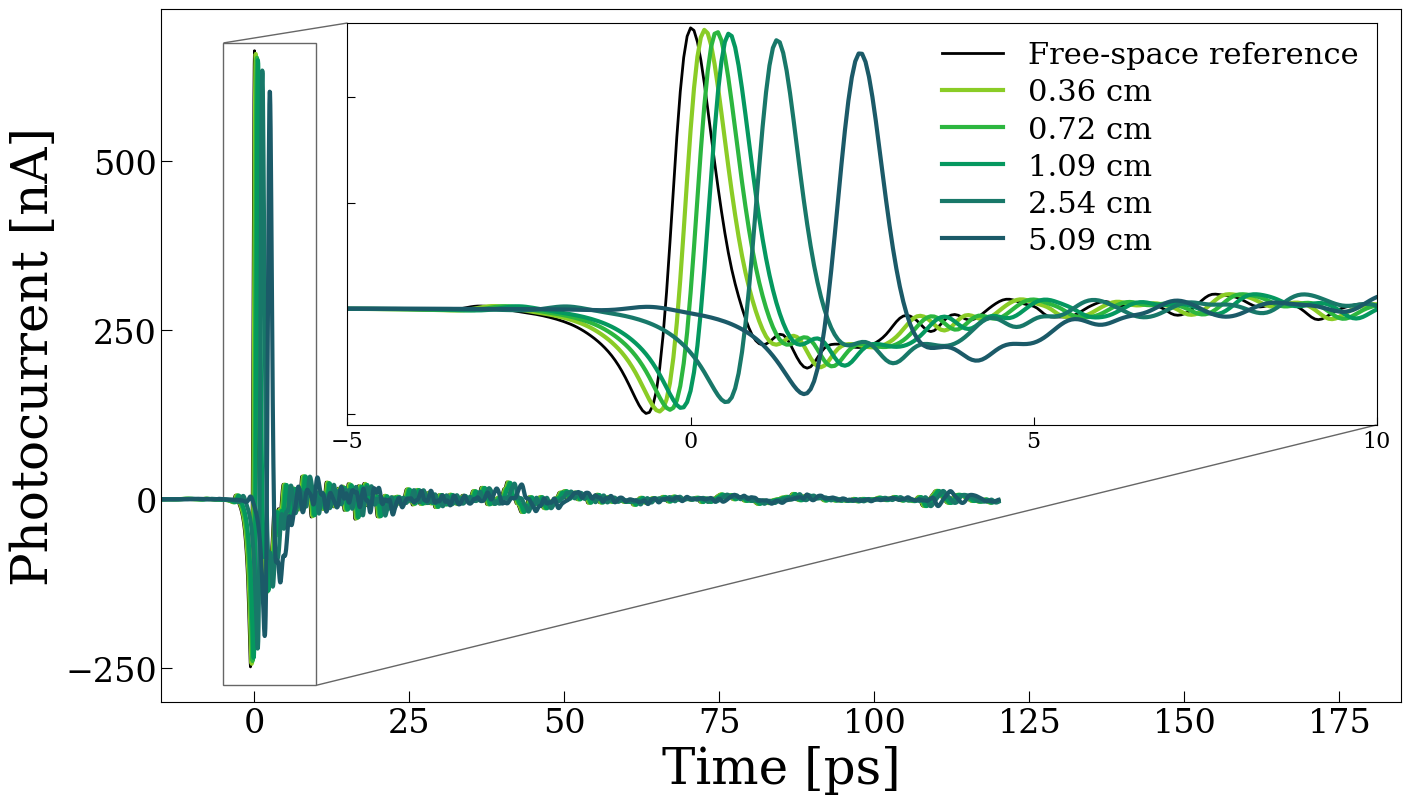

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

fig, ax = plt.subplots(figsize=(16, 9))

T_open,  pc_open  = site_25o4mm.get_base_pulse()

T0 = T_open[np.argmin(pc_open)]
t_ref = T_open - T0
y_ref = -pc_open

ax.set_xlim(-15, 185)

ylims = [-300, 725]
ax.set_ylim(ylims)
ax.set_yticks([-250, 0, 250, 500])
ax.xaxis.set_minor_locator(MultipleLocator(25))

ax.tick_params(axis="both", which='minor', size=4)
ax.tick_params(axis="both", which='major', size=8)

ax.set_xlabel("Time [ps]")
ax.set_ylabel("Photocurrent [nA]")

# ax.legend(frameon=False, loc="lower right", fontsize=22)

# inset
axins = inset_axes(ax, width="83%", height="58%", bbox_to_anchor=(0.15, 0.4, 1, 1), bbox_transform=ax.transAxes, loc="lower left", borderpad=0)

# plot references
ax.plot(t_ref, y_ref, color="k", lw=2, label="Free-space reference")
axins.plot(t_ref, y_ref, color="k", lw=2, label="Free-space reference")

# plot *all* samples in inset
for s in HD30_batch3.keys():
    width_cm = f"{HD30_batch3[s]['width']:.2f} cm"
    ax.plot(HD30_batch3[s]["T"] - T0, -HD30_batch3[s]["pc"], color=HD30_batch3[s]['color'], lw=3, label=width_cm)
    axins.plot(
        HD30_batch3[s]["T"] - T0,
        -HD30_batch3[s]["pc"],
        color=HD30_batch3[s]['color'],
        ls='-',
        lw=3,
        label=width_cm
    )

x1, x2 = -5, 10
axins.set_xlim(x1, x2)
axins.set_ylim([-275, 675])

axins.legend(frameon=False, loc="upper right", fontsize=22, handlelength=2.0, labelspacing=0.3, borderaxespad=0.2)

mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.4", lw=1)

axins.set_xticks([-5, 0, 5, 10])
axins.set_yticks([-250, 0, 250, 500], labels=[])

axins.tick_params(axis="both", size=6, labelsize=16)

fig.patch.set_facecolor("white")
# plt.tight_layout()
# plt.savefig("HD30_time_domain_inset.pdf", bbox_inches="tight", facecolor="white")
plt.show()

## Phase

In [15]:
# Phase cleaning (2*pi branch pick + mid-spectrum jump repair) now happens at LOAD time,
# via each sample's own TeraFlashAnalyzer.get_phase_diff() call (see the loading cells
# above) rather than a second pass over `batches` here -- get_phase_diff() is a thin
# instance wrapper over the same TeraToptica.clean_phase_diff() staticmethod this cell used
# to call directly, so behavior is unchanged; only WHEN it runs moved (verified: re-ran the
# full notebook before and after this refactor and diffed every sample's phase_diff/n_ulim/
# n_eff -- identical). Each loading block already passes max_smear_bins=2 (the same
# dataset-specific override this cell used to apply uniformly here -- this dataset's own
# measured ripple ceiling, ~2.3 rad worst case, clears clean_phase_diff's jump_height=5.2
# with margin, unlike a family of meteorite slab measurements whose ripple is correlated
# enough that its K=2 noise ceiling, ~5.76 rad, lands within 0.05 rad of a real jump here,
# ~5.72 rad -- this override exists because of a real missed correction in "Styrofoam 4.53
# cm" at ~1404.6 GHz, see clean_phase_diff's max_smear_bins docstring), and HD60's
# TeraScanAnalyzer instance gets unwrap=True directly at its own call site (it's the one
# legacy TeraScan measurement whose theta wraps faster than theta_base) rather than a bname
# string match here -- HD60 isn't currently added to `batches` either way.
#
# jump_range itself is left at clean_phase_diff()'s default (unbounded), same as the
# meteorite notebooks -- no local override here either. History: a jump_range capped at
# 1500 GHz (matching the meteorite data's own validity ceiling) missed a real, correctable
# 2*pi jump at ~1720 GHz in "Styrofoam 0.61 cm", shifting that sample's n_eff by
# +1.93-sigma; raising the cap to 2000 GHz fixed that one sample but is exactly the kind of
# per-dataset magic number that breaks again on the next sample with a real feature past
# 2000. The actual fix: leave jump_range's upper bound unbounded -- a correction only ever
# applies FORWARD from where it's detected, so a spurious "jump" found deep in the noise
# floor can only corrupt phase_diff above itself, never at or below a real feature.
# Verified on both datasets: for all 9 meteorite samples, phase_diff below 1500 GHz is
# byte-identical whether jump_range is capped at 1500 or left unbounded; for all samples
# here, unbounded reproduces "Styrofoam 0.61 cm" to within 0.06-sigma of legacy (vs.
# +1.93-sigma with the 1500 cap) and is simultaneously the best match to legacy across every
# other sample too. n_ulim can end up reporting a frequency deep in the noise floor when the
# only "untrusted" jump found is out there -- harmless, since downstream n/n_eff here
# already AND with each sample's own mask, which always excludes that region anyway.
#
# What's left here is just the n/n_eff computation, reading the phase_diff/n_ulim each
# sample's dict already carries in from load time.

for bname, b in {**batches, 'HD30_batch1_rejected': HD30_batch1_rejected}.items():
    for sample in b:
        phase_diff = b[sample]['phase_diff']

        b[sample]['delta_L'] = phase_diff*const.c/(2*np.pi*b[sample]['f']*1e9)
        b[sample]['n'] = 1 + b[sample]['delta_L']/b[sample]['width']*100 # convert to cm

        freq_mask = (b[sample]['f'] <= b[sample]['n_ulim']) # Can change if phase errors occur at high frequencies
        mask_n = freq_mask & (~b[sample]['mask'])

        b[sample]['n_masked'] = b[sample]['n'][mask_n]

        if sample == 'HD30 Batch1 2x1/8" (6.83 mm)':
            continue # Exclude this outlier sample from averaging

        b[sample]['n_eff'] = np.average(b[sample]['n_masked'], weights=b[sample]['t'][mask_n])
        b[sample]['n_eff_err'] = np.sqrt(np.average((b[sample]['n_masked'] - b[sample]['n_eff'])**2, weights=b[sample]['t'][mask_n]))

    if bname not in batches:
        continue # the rejected stacks: per-sample n for the diagnostics, no batch n_eff
    valid = [sample for sample in b if sample != 'HD30 Batch1 2x1/8" (6.83 mm)']

    ## Each average is weighted by the inverse variance is the materials are homogenous.
    comb_batches[bname]['n_eff'] = np.average([b[sample]['n_eff'] for sample in valid], weights=[1/b[sample]['n_eff_err']**2 for sample in valid])

    propagated_err = np.sqrt(1 / np.sum([1/b[sample]['n_eff_err']**2 for sample in valid]))
    scatter_err = np.sqrt(np.average([(b[sample]['n_eff'] - comb_batches[bname]['n_eff'])**2 for sample in valid], weights=[1/b[sample]['n_eff_err']**2 for sample in valid]))
    comb_batches[bname]['n_eff_err'] = max(propagated_err, scatter_err)


## Evenly weight the batches within each material type
zote_neff2 = np.mean([comb_batches[sample]['n_eff'] for sample in comb_batches if sample in HD30_batches])
propagated_err = np.sqrt(np.sum([comb_batches[sample]['n_eff_err']**2 for sample in comb_batches if sample in HD30_batches])) / len(HD30_batches)
scatter_err = np.sqrt(np.mean([(comb_batches[sample]['n_eff'] - zote_neff2)**2 for sample in comb_batches if sample in HD30_batches]))
zote_neff2_err = max(propagated_err, scatter_err)

styro_neff2 = np.mean([comb_batches[sample]['n_eff'] for sample in comb_batches if sample in styro_batches])
propagated_err = np.sqrt(np.sum([comb_batches[sample]['n_eff_err']**2 for sample in comb_batches if sample in styro_batches])) / len(styro_batches)
scatter_err = np.sqrt(np.mean([(comb_batches[sample]['n_eff'] - styro_neff2)**2 for sample in comb_batches if sample in styro_batches]))
styro_neff2_err = max(propagated_err, scatter_err)

print(f"""
Zotefoams: n_eff = {zote_neff2:.3f} ± {zote_neff2_err:.3f}
Styrofoams: n_eff = {styro_neff2:.3f} ± {styro_neff2_err:.3f}
""")


Zotefoams: n_eff = 1.015 ± 0.001
Styrofoams: n_eff = 1.020 ± 0.003



C:\Users\alexg\AppData\Local\Temp\ipykernel_32352\3145330843.py:42: RuntimeWarning: invalid value encountered in divide
  b[sample]['delta_L'] = phase_diff*const.c/(2*np.pi*b[sample]['f']*1e9)
C:\Users\alexg\AppData\Local\Temp\ipykernel_32352\3145330843.py:42: RuntimeWarning: divide by zero encountered in divide
  b[sample]['delta_L'] = phase_diff*const.c/(2*np.pi*b[sample]['f']*1e9)


In [16]:
for bname, b in comb_batches.items():
    print(f"{bname}: n_eff = {b['n_eff']:.4f} ± {b['n_eff_err']:.4f}")

Styrofoam_batch1: n_eff = 1.0204 ± 0.0026
HD30_batch1: n_eff = 1.0175 ± 0.0006
HD30_batch2: n_eff = 1.0142 ± 0.0011
HD30_batch3: n_eff = 1.0148 ± 0.0006
PP35_batch1: n_eff = 1.0179 ± 0.0001
PP35_batch2: n_eff = 1.0202 ± 0.0009
LD15_batch1: n_eff = 1.0090 ± 0.0001
LD15_batch2: n_eff = 1.0069 ± 0.0007
LD24_batch1: n_eff = 1.0127 ± 0.0002
LD24_batch2: n_eff = 1.0123 ± 0.0005
HD80_batch1: n_eff = 1.0370 ± 0.0005
HD110_batch1: n_eff = 1.0576 ± 0.0006


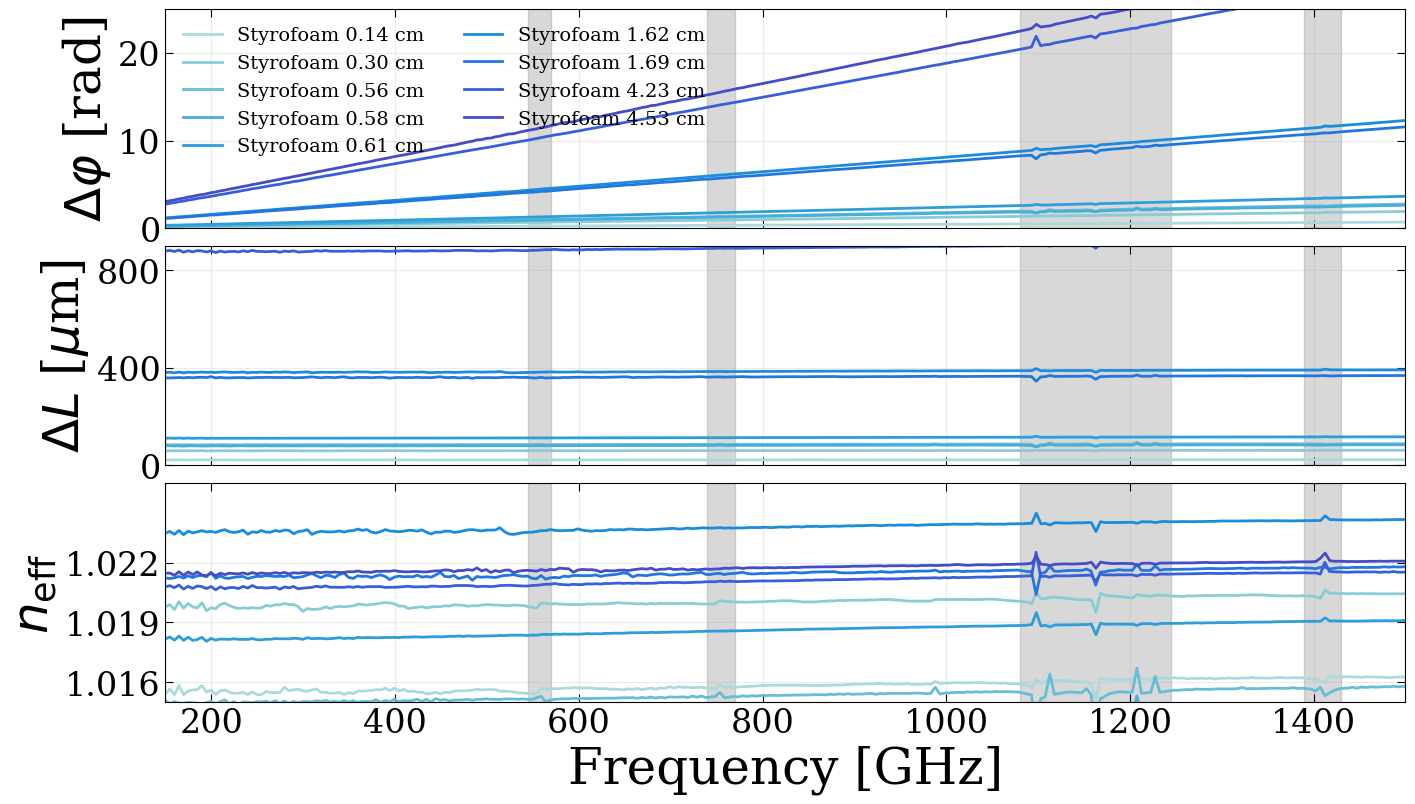

In [17]:
fig, axs = plt.subplots(
    3, 1, sharex=True, figsize=(16, 9),
    gridspec_kw=dict(height_ratios=[1, 1, 1], hspace=0.08)
)

for bname, b in batches.items():
    if "Styrofoam" not in bname:
        continue
    for sample in b:
        axs[0].plot(b[sample]['f'], b[sample]['phase_diff'], color=b[sample]['color'], lw=2, label=sample)
        axs[1].plot(b[sample]['f'], b[sample]['delta_L']*1e6, color=b[sample]['color'], lw=2, label=sample)
        axs[2].plot(b[sample]['f'], b[sample]['n'], lw=2, color=b[sample]['color'], label=sample)

# Axis labels
axs[0].set_ylabel(r'$\Delta \varphi$ [rad]')
axs[1].set_ylabel(r'$\Delta L$ [$\mu$m]')
axs[2].set_ylabel(r'$n_{\rm eff}$')
axs[2].set_xlabel('Frequency [GHz]')

# Limits / ticks
for ax in axs:
    for i, j in zip(mask_starts, mask_stops):
        ax.axvspan(i, j, color='gray', alpha=0.3)
    ax.set_xlim(150, 1500)
    # ax.set_xlim(0, 200)
    ax.grid(True, alpha=0.25)
    ax.tick_params(direction='in', length=6, top=True, right=True)

for i, j in zip(mask_starts, mask_stops):
    if ((i == 0) or (j >= 1500)):
        continue
    # else:
    #     axs[0].text((i+j)/2, 25, 'H$_2$O', horizontalalignment='center', verticalalignment='bottom', fontsize=12, color='black', fontweight='bold')

axs[0].set_ylim(0, 25)
axs[1].set_ylim(0, 900)
axs[2].set_ylim(1.015, 1.026)
axs[1].set_yticks([0, 400, 800])
axs[2].set_yticks([1.016, 1.019, 1.022])
# Legend (single, clean)
axs[0].legend(loc='upper left', fontsize=14, edgecolor='k', frameon=False, ncol=2)

# Remove x tick labels on upper panels (sharex already, but makes it cleaner)
plt.subplots_adjust(hspace=0.08)
axs[0].label_outer()
axs[1].label_outer()
plt.show()


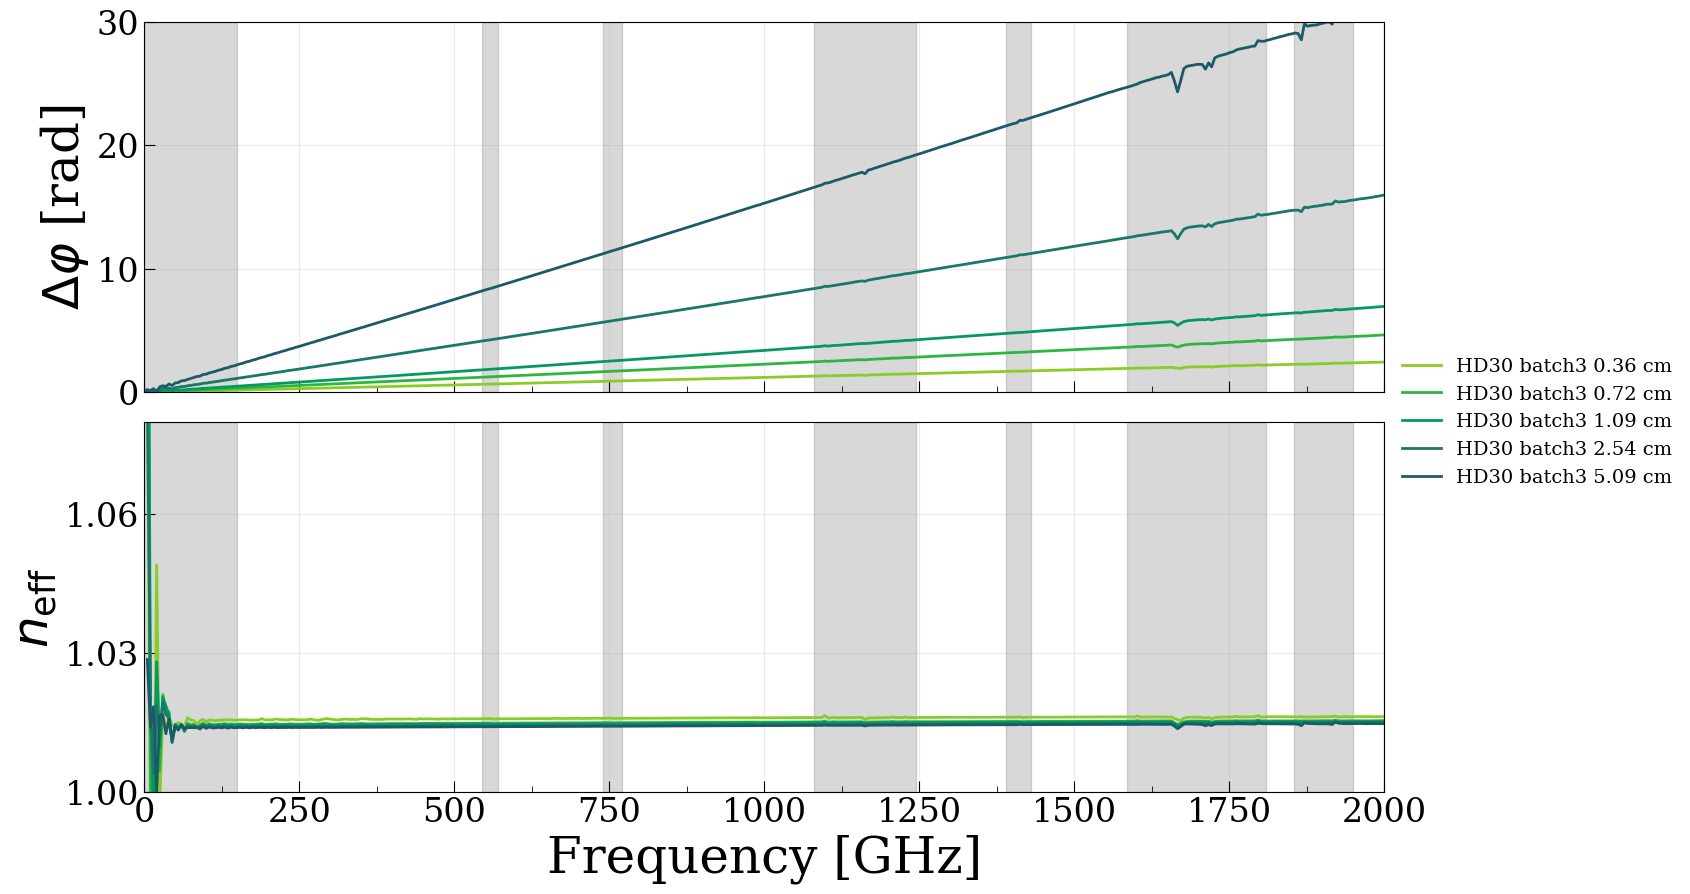

In [18]:
fig, axs = plt.subplots(
    2, 1, sharex=True, figsize=(16, 10),
    gridspec_kw=dict(height_ratios=[1, 1], hspace=0.08)
)

for bname, b in batches.items():
    if bname != 'HD30_batch3':
        continue

    # if bname not in other_zote_keys or bname == 'HD60 2.03 cm':
    #     continue
    for sample in b:
        # if sample != 'HD80 batch1 1.06 cm':
        #     continue

        color = b[sample]['color']

        axs[0].plot(b[sample]['f'], b[sample]['phase_diff'],  color=color, lw=2, label=sample)
        axs[1].plot(b[sample]['f'], b[sample]['n'],           color=color, lw=2, label=sample)

# Axis labels
axs[0].set_ylabel(r'$\Delta \varphi$ [rad]')
axs[1].set_ylabel(r'$n_{\rm eff}$')
axs[1].set_xlabel('Frequency [GHz]')

# Limits / ticks
for ax in axs:
    for i, j in zip(mask_starts, mask_stops):
        ax.axvspan(i, j, color='gray', alpha=0.3)
    ax.set_xlim(0, 2000)
    # ax.set_xlim(0, 200)
    ax.grid(True, alpha=0.25)
axs[1].xaxis.set_major_locator(MultipleLocator(250))
axs[1].xaxis.set_minor_locator(MultipleLocator(125))

for i, j in zip(mask_starts, mask_stops):
    if ((i == 0) or (j >= 1500)):
        continue

axs[0].set_ylim(0, 30)
axs[1].set_ylim(1, 1.08)
axs[1].set_yticks([1, 1.03, 1.06])
plt.legend(bbox_to_anchor=(1, 1), loc='center left', fontsize=14, edgecolor='k', frameon=False, ncol=1)

# Remove x tick labels on upper panels (sharex already, but makes it cleaner)
plt.subplots_adjust(hspace=0.08)
axs[0].label_outer()
axs[1].label_outer()

plt.show()

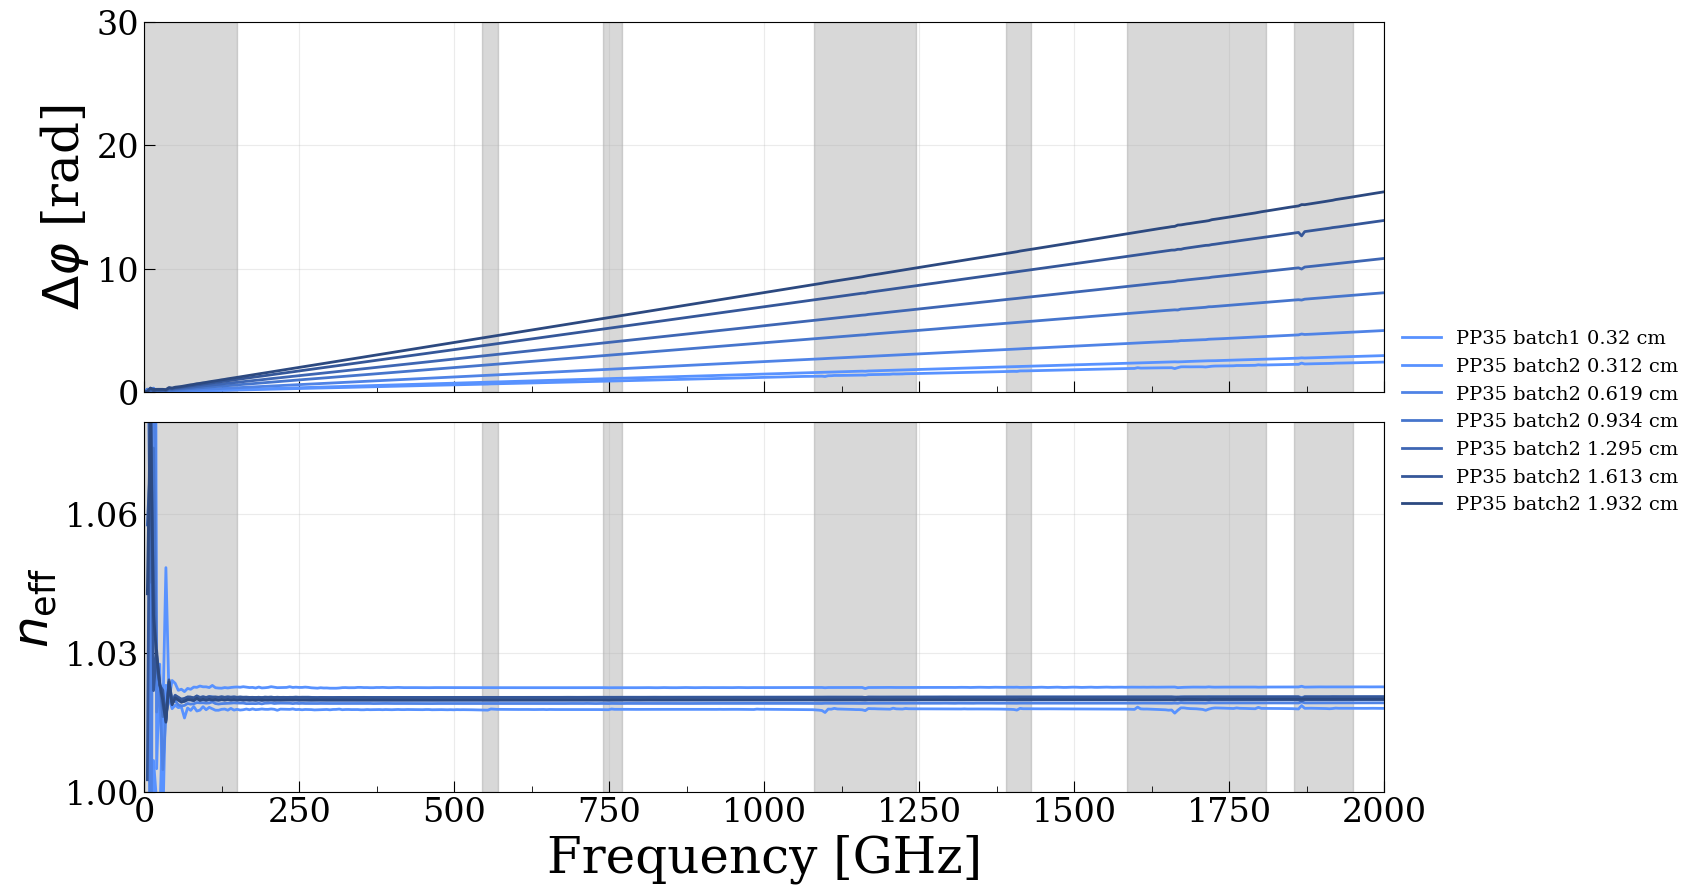

In [19]:
fig, axs = plt.subplots(
    2, 1, sharex=True, figsize=(16, 10),
    gridspec_kw=dict(height_ratios=[1, 1], hspace=0.08)
)

for bname, b in batches.items():
    if not bname.startswith('PP35'):
        continue

    # if bname not in other_zote_keys or bname == 'HD60 2.03 cm':
    #     continue
    for sample in b:
        # if sample != 'HD80 batch1 1.06 cm':
        #     continue

        color = b[sample]['color']

        axs[0].plot(b[sample]['f'], b[sample]['phase_diff'],  color=color, lw=2, label=sample)
        axs[1].plot(b[sample]['f'], b[sample]['n'],           color=color, lw=2, label=sample)

# Axis labels
axs[0].set_ylabel(r'$\Delta \varphi$ [rad]')
axs[1].set_ylabel(r'$n_{\rm eff}$')
axs[1].set_xlabel('Frequency [GHz]')

# Limits / ticks
for ax in axs:
    for i, j in zip(mask_starts, mask_stops):
        ax.axvspan(i, j, color='gray', alpha=0.3)
    ax.set_xlim(0, 2000)
    # ax.set_xlim(0, 200)
    ax.grid(True, alpha=0.25)
axs[1].xaxis.set_major_locator(MultipleLocator(250))
axs[1].xaxis.set_minor_locator(MultipleLocator(125))

for i, j in zip(mask_starts, mask_stops):
    if ((i == 0) or (j >= 1500)):
        continue

axs[0].set_ylim(0, 30)
axs[1].set_ylim(1, 1.08)
axs[1].set_yticks([1, 1.03, 1.06])
plt.legend(bbox_to_anchor=(1, 1), loc='center left', fontsize=14, edgecolor='k', frameon=False, ncol=1)

# Remove x tick labels on upper panels (sharex already, but makes it cleaner)
plt.subplots_adjust(hspace=0.08)
axs[0].label_outer()
axs[1].label_outer()

plt.show()

## Frequency Domain

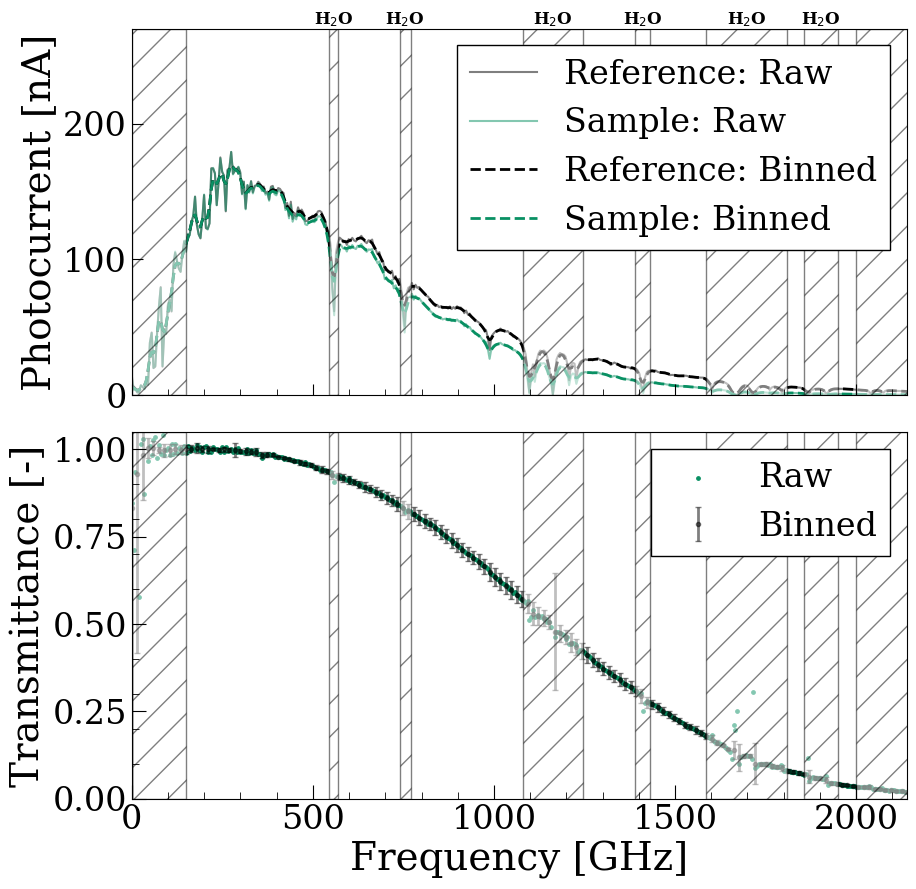

In [20]:
_, samp_amp = site_25o4mm.get_sample_current()
_, ref_amp  = site_25o4mm.get_base_current()

samp_amp_smoothed = getattr(site_25o4mm, 'bcsamp')
ref_amp_smoothed  = getattr(site_25o4mm, 'bcbase')
mes_err           = getattr(site_25o4mm, 'mes_err')

# Plot measurements and fits

b = batches['HD30_batch3']
sample = 'HD30 batch3 2.54 cm'
data = HD30_batch3[sample]

color = comb_batches["HD30_batch3"]['color']

fig, axs = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

alpha_matrix = np.vstack([b[sample]['alpha'] for sample in b])
alpha_err = np.std(alpha_matrix, axis=0, ddof=1)
width     = b[sample]['width']
t         = b[sample]['t']
err_stat = width * t *alpha_err
    
err_tot = np.sqrt(b[sample]['err']**2 + err_stat**2) # combine errors in quadrature

ax0, ax1 = axs

ax0.plot(data['f'], ref_amp, color='k', alpha=0.5, label='Reference: Raw', zorder=-10)
ax0.plot(data['f'], samp_amp, color=color, alpha=0.5, label='Sample: Raw', zorder=-10)
ax0.plot(data['f'], ref_amp_smoothed, color='k', linestyle='--', linewidth=2, label='Reference: Binned', zorder=-10)
ax0.plot(data['f'], samp_amp_smoothed, color=color, linestyle='--', linewidth=2, label='Sample: Binned', zorder=-10)
# ax1.plot(data['f'], mes_err, color='cyan', linestyle='-', linewidth=2, label='Photon noise floor', zorder=10)

ax1.scatter(data['f'], data['ut'], color=color, s=6, label='Raw', zorder=-10)
ax1.errorbar(data['f'][::data['boxnum']], data['t'][::data['boxnum']], yerr=err_tot[::data['boxnum']],
        fmt='o', markersize=3, linewidth=2, capsize=2, color='k', alpha=0.5, label='Binned', zorder=-10)
    # plt.plot(data[sample]['f'], data[sample]['cf'], color='k', linestyle='--', linewidth=2, alpha=0.7, zorder=10, label=r'Rayleigh $\times$ Mie Model' if i == len(data)-1 else None)
data_handles, data_labels = plt.gca().get_legend_handles_labels()

xlims = (0, 2140)

for i, j in zip(mask_starts, mask_stops):
    for ax in axs:
        ax.axvspan(i, j, facecolor='white', hatch='/', edgecolor='k', alpha=0.5, zorder=1)
    if (i == 0):
        # ax0.text((xlims[0]+j)/2, 270, 'Instr.\nLimit', horizontalalignment='center', verticalalignment='bottom', fontsize=12, color='black', fontweight='bold')
        continue
    elif (j == 10000):
        # ax0.text((i+xlims[1])/2, 270, 'Instr.\nLimit', horizontalalignment='center', verticalalignment='bottom', fontsize=12, color='black', fontweight='bold')
        continue
    else:
        ax0.text((i+j)/2, 270, 'H$_2$O', horizontalalignment='center', verticalalignment='bottom', fontsize=12, color='black', fontweight='bold')


handles, labels = plt.gca().get_legend_handles_labels()
misc_handles = [handle for handle in handles if handle not in data_handles]
custom_line = [mpl.lines.Line2D([0], [1], color='lime', linestyle='--', label='Fitted data')]

# plt.legend(handles=data_handles + custom_line + misc_handles, edgecolor='black', fontsize=16, loc='upper right')
ax0.legend(fontsize=24, loc='upper right', framealpha=1, edgecolor='black', facecolor='white', fancybox=False)
ax1.legend(fontsize=24, loc='upper right', framealpha=1, edgecolor='black', facecolor='white', fancybox=False)

ax1.set_xlim(xlims)
# ax0.set_yscale('log')
# ax1.set_yscale('log')
ax0.set_ylim(0, 270)
ax1.set_ylim(0, 1.05)
# ax1.set_ylim(1e-4, 1e0)
# ax1.set_ylim(0, 1.02)
ax1.yaxis.set_minor_locator(MultipleLocator(0.1))
ax0.xaxis.set_minor_locator(MultipleLocator(100))
plt.tick_params(axis='both', which='major', size=10)
plt.tick_params(axis='both', which='minor', size=5)
ax1.set_xlabel('Frequency [GHz]', fontsize=28)
ax0.set_ylabel('Photocurrent [nA]', fontsize=28)
ax1.set_ylabel('Transmittance [-]', fontsize=28)
plt.gcf().set_facecolor('white')
plt.subplots_adjust(hspace=0.1)

# plt.savefig('ut_vs_t_example.pdf', bbox_inches='tight', facecolor='white')
plt.show()

## Material properties

Polymer fraction $f_p$ (density mixing), polymer index $n_p$ and the Maxwell-Garnett loss tangent estimate. The full-Mie model needs $f_p$ and $n_p$ before fitting.

In [21]:
def f_p_from_rho(rho_eff, rho_p, rho_m=1.25):
    """Matrix volume fraction from density mixing: rho_eff = f_p rho_p + (1-f_p) rho_m."""
    return (rho_eff - rho_m) / (rho_p - rho_m)

def lt_eff(f_p, n_p, tan_delta_p, n_eff, n_m=1.0003):
    """
    Maxwell-Garnett (dilute polymer inclusions in gas host) effective loss tangent.
    tan_eff = n_p^2 * (n_n_eff^2 + 2n_m^2)^2 / [n_eff^2 * (n_p^2 + 2n_m^2)^2] * f_p tan_delta_p
    """
    num = n_p**2*(n_eff**2 + 2*n_m**2)**2
    den = n_eff**2*(n_p**2   + 2*n_m**2)**2
    return (num / den) * f_p * tan_delta_p

def lt_eff_walls(f_p, n_p, tan_delta_p, n_eff):
    """
    Effective loss tangent with all of the polymer in randomly oriented thin walls (dilute lamellae; the full-Mie model's
    picture). eps_eff - 1 = f_p [2/3 (eps_p - 1) + 1/3 (1 - 1/eps_p)], so eps_eff'' = f_p eps_p'' (2/3 + 1/(3 |eps_p|^2)) and
    tan_eff = eps_eff'' / n_eff^2. For PE this is 1.54x the Maxwell-Garnett (spheres) value above at the same f_p.
    """
    return f_p * n_p**2 * tan_delta_p * (2/3 + 1/(3*n_p**4)) / n_eff**2

def f_p_from_n_walls(n_eff, n_p):
    """Polymer fraction implied by n_eff with all of the polymer in randomly oriented thin walls (cross-check of the density value)."""
    e = n_p**2
    return (n_eff**2 - 1) / ((e - 1)*(2 + 1/e)/3)

## All of the polymer is taken to be in the walls (2026-10-13), consistent with the full-Mie model: the absorption estimate
## uses lt_eff_walls; lt_eff (Maxwell-Garnett spheres) is kept for reference.
## Bulk loss tangents: one in-band value per polymer, applied consistently to every foam.
## Birch, Dromey & Lesurf, Infrared Phys. 21, 225 (1981) (290 K) for PE and PS; Afsar, IEEE Trans. Instrum. Meas. 36, 530 (1987) for PP.
for bname, b in comb_batches.items():

    ## Estimate the loss tangent
    if "HD" in bname:
        b['rho_p'] = 950
        lt_p      = 3.1e-4   # HDPE at 160 GHz, Birch et al. 1981
        b['n_p'] = 1.54
        
    elif "LD" in bname:
        b['rho_p'] = 925
        lt_p       = 3.1e-4   # LDPE at 160 GHz, Birch et al. 1981
        b['n_p']   = 1.514  # Literature estimates this value as slightly lower...
        
    elif "Styrofoam" in bname:
        b['rho_p'] = 1050
        lt_p       = 1.8e-3   # Polystyrene at 150 GHz, Birch et al. 1981
        b['n_p']   = 1.59
    elif "PP" in bname:
        b['rho_p'] = 905
        lt_p       = 6.2e-4   # Polypropylene at 200 GHz, Afsar 1987
        b['n_p']   = 1.5
    else:
        raise ValueError(f"Unknown material type: {bname}")

    b['f_p'] = f_p_from_rho(b['density'], b['rho_p'])
    b['lt_p'] = lt_p
    b['lt']  = lt_eff_walls(b['f_p'], b['n_p'], lt_p, b['n_eff'])
    b['f_p_n'] = f_p_from_n_walls(b['n_eff'], b['n_p'])

for bname, b in comb_batches.items():
    print(f"{bname:<19}: f_p = {b['f_p']:.3f} (density), {b['f_p_n']:.3f} (n_eff, thin walls), lt = {b['lt']:.3e} (thin walls; MG {lt_eff(b['f_p'], b['n_p'], b['lt_p'], b['n_eff']):.3e})")

Styrofoam_batch1   : f_p = 0.036 (density), 0.034 (n_eff, thin walls), lt = 1.131e-04 (thin walls; MG 7.098e-05)
HD30_batch1        : f_p = 0.030 (density), 0.032 (n_eff, thin walls), lt = 1.562e-05 (thin walls; MG 1.038e-05)
HD30_batch2        : f_p = 0.030 (density), 0.026 (n_eff, thin walls), lt = 1.572e-05 (thin walls; MG 1.040e-05)
HD30_batch3        : f_p = 0.030 (density), 0.027 (n_eff, thin walls), lt = 1.571e-05 (thin walls; MG 1.039e-05)
PP35_batch1        : f_p = 0.037 (density), 0.035 (n_eff, thin walls), lt = 3.683e-05 (thin walls; MG 2.567e-05)
PP35_batch2        : f_p = 0.037 (density), 0.040 (n_eff, thin walls), lt = 3.666e-05 (thin walls; MG 2.563e-05)
LD15_batch1        : f_p = 0.015 (density), 0.017 (n_eff, thin walls), lt = 7.585e-06 (thin walls; MG 5.138e-06)
LD15_batch2        : f_p = 0.015 (density), 0.013 (n_eff, thin walls), lt = 7.616e-06 (thin walls; MG 5.145e-06)
LD24_batch1        : f_p = 0.025 (density), 0.024 (n_eff, thin walls), lt = 1.246e-05 (thin wall

## Nested Sampling

**Full-Mie thin-shell model with tan δ fixed** (`fullmie_funcs_fxlt.py`). Everything else matches `main.ipynb` (see its Nested Sampling cell): model, priors, data, likelihood, `nlive` and `dlogz`. tan δ is fixed at the thin-wall prediction `b['lt']`: all of the polymer in the walls, with the bulk tan δ of Birch et al. and Afsar. That value is high, so the choice is conservative.

$$\alpha = \frac{2\pi n_{\rm eff}\tan\delta}{c}f + C\,\langle Q_{\rm Mie}(x)\rangle_{\rm area},
\qquad Q_{\rm Mie} = \frac{2}{x^2}\sum_{n=1}^{\infty}(2n+1)\left(|a_n|^2 + |b_n|^2\right) = \left(\frac{2\ell}{d}\right)^2 G(x; n_p),
\qquad x = \frac{\pi d f}{c}$$

Free parameters:
- $C$ [cm⁻¹]: cell cross-sections a ray meets per cm.
- $d_{\rm med}$ [µm]: median of the number distribution of cell diameters.
- $s$: log-normal width of $\ln d$.

$\ell/d$ comes from the density and $n_p$ from the literature.

The posterior samples below carry tan δ as a constant first column, so every downstream cell reads them as `main.ipynb` does. The R+M+a_RM fits behind the Eq. 15–16 comparison are also its fixed-tan δ fits (`pkls/*_rma_fxlt_fp{GATE_TAG}.pkl`).

Numba just in time (`njit`) version for efficient sampling

In [22]:
from fitting_funcs import IRBF_njit, IRBF_alpha_njit   # R+M+a_RM, kept for comparison
from fullmie_funcs import MIE_njit, MIE_alpha_njit, fitting_mie, shell_table, wall_factor

TAG = 'fullmie_fxlt'   # suffix for this model's pkls and figures

def IRBF_abs(f, lt, width, n):
    loss      = 2e7*np.pi*n*lt*f/const.c
    Abs_perc = 100*(1 - np.exp(-width*loss))
    return Abs_perc

def chi2_dof(f, t, C, IRBF, len_params):
    chi2 = np.sum(((t - IRBF)/C)**2)
    dof  = len(f) - len_params
    return chi2/dof

## Per-batch model inputs: G(x) table for the batch polymer index, void fraction f_m = 1 - f_p
for bname, b in comb_batches.items():
    b['mie_g'] = shell_table(b['n_p'])
    b['f_m']   = 1 - b['f_p']

############# Configure to adjust the nested sampling #############
nlive = 10000
dlogz = 0.01
ncpu  = 4

HD110_batch1 96


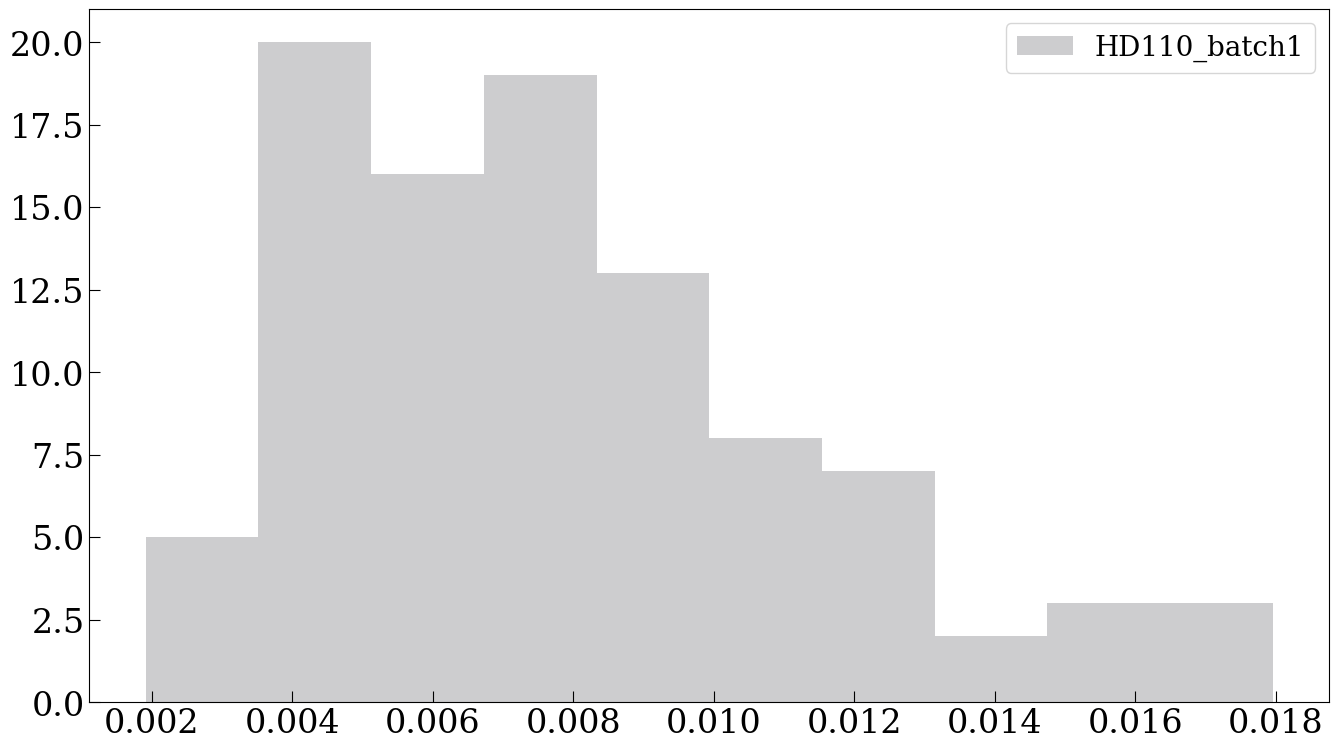

In [23]:
for bname, b in comb_batches.items():
    # if bname == 'HD60 2.03 cm':
    #     continue
    if bname != 'HD110_batch1':
        continue

    err_comb = b['err_comb']
    color = b['color']
    plt.hist(err_comb, alpha=0.5, label=bname, color=color)
    plt.legend(loc='upper right')
    print(bname, len(err_comb))

plt.show()

In [24]:
import fullmie_funcs
import fullmie_funcs_fxlt
import fitting_funcs_fxlt
from fullmie_funcs_fxlt import fitting_mie_fxlt
from fitting_funcs_fxlt import fitting as fitting_rma_fxlt
from fit_cache import fingerprint, module_source_hash, load_fit, save_fit, run_info

## tan_delta fixed at the thin-wall prediction b['lt']. Same fingerprints and cache files as main.ipynb's fixed-loss-tangent
## section, so the two notebooks share these fits.
mie_fx_hash = module_source_hash(fullmie_funcs) + module_source_hash(fullmie_funcs_fxlt)
rma_fx_hash = module_source_hash(fitting_funcs_fxlt)
MODEL_PARAMS = list(fullmie_funcs.PARAM_NAMES)   # ['tan_delta' (fixed), 'd_med_um', 's', 'C_per_cm']

def with_lt(samples, lt):
    # posterior samples with the fixed tan_delta as a constant first column, the layout of the free fits
    return np.column_stack([np.full(len(samples), lt), samples])

RMA = {}
for bname, b in comb_batches.items():
    bname_cleaned = bname.replace(" ", "_").replace('"', 'in')
    f_, t, width, err, n_eff, lt = b['f_comb'], b['t_comb'], b['width_comb'], b['err_comb'], b['n_eff'], b['lt']
    info = run_info(lt=float(lt), nlive=nlive, dlogz=dlogz, n_eff=float(n_eff), gate_end_ps=GATE_END_PS, gate_taper_ps=GATE_TAPER_PS)

    fpath = f'pkls/{bname_cleaned}_fullmie_fxlt_fp{GATE_TAG}.pkl'
    b['fit_fp'] = fingerprint('fullmie_fxlt', mie_fx_hash, f_, t, width, err, n_eff, lt, b['mie_g'], b['f_m'])
    results = load_fit(fpath, b['fit_fp'], min_nlive=nlive)
    if results is None:
        results = fitting_mie_fxlt(f_, t, width, err, n_eff, lt, b['mie_g'], b['f_m'], nlive, dlogz, ncpu=ncpu)
        results.summary()
        save_fit(fpath, results, b['fit_fp'], info | {'model': 'fullmie_fxlt'})

    b['results'] = results
    b['weights'] = np.exp(results['logwt'] - results['logz'][-1])
    b['samples'] = with_lt(dynesty.utils.resample_equal(results.samples, b['weights']), lt)
    print(f'Number of posterior {bname} samples:', len(b['samples']), f'(tan_delta fixed at {lt:.2e})')

    ## R+M+a_RM with the same fixed tan_delta, for the Eq. 15-16 cell sizes
    fpath = f'pkls/{bname_cleaned}_rma_fxlt_fp{GATE_TAG}.pkl'
    fp = fingerprint('rma_fxlt', rma_fx_hash, f_, t, width, err, n_eff, lt)
    res = load_fit(fpath, fp, min_nlive=nlive)
    if res is None:
        res = fitting_rma_fxlt(f_, t, width, err, n_eff, lt, nlive, dlogz, ncpu=ncpu)
        save_fit(fpath, res, fp, info | {'model': 'rma_fxlt'})
    w_ = np.exp(res['logwt'] - res['logz'][-1])
    RMA[bname] = dict(results=res, fit_fp=fp, samples=with_lt(dynesty.utils.resample_equal(res.samples, w_), lt))

Number of posterior Styrofoam_batch1 samples: 201989 (tan_delta fixed at 1.13e-04)


Number of posterior HD30_batch1 samples: 192167 (tan_delta fixed at 1.56e-05)


Number of posterior HD30_batch2 samples: 217127 (tan_delta fixed at 1.57e-05)


Number of posterior HD30_batch3 samples: 219311 (tan_delta fixed at 1.57e-05)


Number of posterior PP35_batch1 samples: 199013 (tan_delta fixed at 3.68e-05)


Number of posterior PP35_batch2 samples: 188037 (tan_delta fixed at 3.67e-05)


... (2 outputs left out)

Number of posterior LD24_batch1 samples: 237355 (tan_delta fixed at 1.25e-05)


Number of posterior LD24_batch2 samples: 212424 (tan_delta fixed at 1.25e-05)


Number of posterior HD80_batch1 samples: 252731 (tan_delta fixed at 4.12e-05)


Number of posterior HD110_batch1 samples: 213080 (tan_delta fixed at 5.47e-05)


In [25]:
from fullmie_funcs import alpha_batch_params_mie, components_batch_params_mie
from fit_cache import load_derived, save_derived

## Model bands use a random subset of the posterior (each full-Mie evaluation averages 41 cell sizes)
N_DRAW = 4000
rng = np.random.default_rng(0)

for bname, b in comb_batches.items():
    b['draws'] = b['samples'][rng.choice(len(b['samples']), size=min(N_DRAW, len(b['samples'])), replace=False)]

    bname_cleaned = bname.replace(" ", "_").replace('"', 'in')
    fpath = f'pkls/{bname_cleaned}_{TAG}_alpha_fp{GATE_TAG}.pkl'
    fp = fingerprint(b['fit_fp'], f, b['n_eff'], b['draws'])

    cached = load_derived(fpath, fp)
    if cached is not None:
        b['alpha_lower'], b['ns_alpha'], b['alpha_upper'] = cached
    else:
        alpha = alpha_batch_params_mie(f, b['draws'], b['n_eff'], b['mie_g'], b['f_m'])
        b['alpha_lower'], b['ns_alpha'], b['alpha_upper'] = np.percentile(alpha, [16, 50, 84], axis=0)
        save_derived(fpath, (b['alpha_lower'], b['ns_alpha'], b['alpha_upper']), fp)

Styrofoam_batch1_fullmie_fxlt_alpha_fp_g120.pkl: recomputing (fingerprint a6f823eef43b5314 != 5f867bf2e8fc9b3f (inputs changed))


HD30_batch1_fullmie_fxlt_alpha_fp_g120.pkl: recomputing (fingerprint 9b1d0282965cfb4d != 199366b805cfcf60 (inputs changed))


HD30_batch2_fullmie_fxlt_alpha_fp_g120.pkl: recomputing (fingerprint 6b0a39cca42c53a9 != 0f074db3970de337 (inputs changed))


HD30_batch3_fullmie_fxlt_alpha_fp_g120.pkl: recomputing (fingerprint 84775cd2f317579c != fccdce17a8687276 (inputs changed))


PP35_batch1_fullmie_fxlt_alpha_fp_g120.pkl: recomputing (fingerprint 44f890491678816d != 1f1c2ae1bdf575fc (inputs changed))


PP35_batch2_fullmie_fxlt_alpha_fp_g120.pkl: recomputing (fingerprint cfcc4f3f71200794 != d08f18205e5067e4 (inputs changed))


... (2 outputs left out)

LD24_batch1_fullmie_fxlt_alpha_fp_g120.pkl: recomputing (fingerprint 923a1f3fdafa6dcf != 79ad214b101e7a2a (inputs changed))


LD24_batch2_fullmie_fxlt_alpha_fp_g120.pkl: recomputing (fingerprint e1b3673348a8eabf != e569e20d3087e9e3 (inputs changed))


HD80_batch1_fullmie_fxlt_alpha_fp_g120.pkl: recomputing (fingerprint 5e0cb6ba92dcf552 != 39ffd9d8b5db8dc1 (inputs changed))


HD110_batch1_fullmie_fxlt_alpha_fp_g120.pkl: recomputing (fingerprint 88f9209d872a48bf != 50d549ce483a7a01 (inputs changed))


In [26]:
w = 5 # 5 cm assembly example

for bname, b in comb_batches.items():
    q = np.percentile(b['samples'], [16, 50, 84], axis=0)

    b['params']       = q[1]
    b['upper_params'] = q[2] - q[1]
    b['lower_params'] = q[1] - q[0]
    b['C_params'] = (q[2] - q[0])/2

    # We use the 95th percentile, the 2 sigma UL
    q = np.percentile(b['samples'], 95, axis=0)
 
    b['upper_params'][0] = q[0]
    # b['params'][0]       = np.nan # We'll use the 95th percentile, so make sure we don't use the median
    b['lower_params'][0] = 0

    b[f'T_upper_5cm'], b[f'ns_T_5cm'], b[f'T_lower_5cm'] = np.exp(-w*b['alpha_lower']), np.exp(-w*b['ns_alpha']), np.exp(-w*b['alpha_upper'])

    n_eff = b['n_eff']

    for sample_name, sample in batches[bname].items():
        ## transform samples from parameter space to transmission
        width = sample['width']
        sample['T_upper'], sample['ns_T'], sample['T_lower'] = np.exp(-width*b['alpha_lower']), np.exp(-width*b['ns_alpha']), np.exp(-width*b['alpha_upper'])
        diff = sample['T_upper'] - sample['T_lower']

## Combined Sampling Results

In [27]:
def round_uncertainty(x):
    """Return (rounded_value, decimal_places_for_round())."""
    x = float(x)
    if x == 0.0:
        return 0.0, 0

    exponent = int(np.floor(np.log10(abs(x))))

    # first_digit = abs(x) / 10**exponent
    # sigfigs = 2 if first_digit < 1.95 else 1
    sigfigs = 1
    
    decimals = int(sigfigs - 1 - exponent)  # can be negative!

    return round(x, decimals), decimals

def sci_scale(x):
    """
    Return (scaled_x, exponent) such that:
    x = scaled_x * 10**exponent
    """
    if x == 0:
        return 0.0, 0
    exponent = int(np.floor(np.log10(abs(x))))
    return x / 10**exponent, exponent

def format_unc(mu, C_minus, C_plus, sci_thresh=1e-3):
    mu = float(mu)
    C_minus = float(C_minus)
    C_plus  = float(C_plus)

    use_sci = abs(mu) < sci_thresh and mu != 0

    if use_sci:
        mu_s, exp = sci_scale(mu)
        sm_s = C_minus / 10**exp
        sp_s = C_plus  / 10**exp
    else:
        mu_s, sm_s, sp_s = mu, C_minus, C_plus
        exp = None

    # Determine rounding from uncertainties
    _, d1 = round_uncertainty(sm_s)
    _, d2 = round_uncertainty(sp_s)
    decimals = max(d1, d2)

    mu_r = round(mu_s, decimals)
    sm_r = round(sm_s, decimals)
    sp_r = round(sp_s, decimals)

    prec = max(decimals, 0)
    fmt = f"{{:.{prec}f}}"

    core = rf"{fmt.format(mu_r)}^{{+{fmt.format(sp_r)}}}_{{-{fmt.format(sm_r)}}}"

    if use_sci:
        return rf"${core}\times10^{{{exp}}}$"
    else:
        return rf"${core}$"
    
def format_unc_1sided(mu, C, sci_thresh=1e-3, shorthand=True):
    mu = float(mu)
    C = float(C)

    use_sci = abs(mu) < sci_thresh and mu != 0

    if use_sci:
        mu_s, exp = sci_scale(mu)
        C_s = C / 10**exp
    else:
        mu_s, C_s = mu, C
        exp = None

    _, decimals = round_uncertainty(C_s)
    mu_r = round(mu_s, decimals)
    C_r = round(C_s, decimals)

    prec = max(decimals, 0)
    fmt = f"{{:.{prec}f}}"

    if shorthand and not use_sci:
        ### e.g. 1.013(1) for 1.013 ± 0.001
        C_int = round(C_r * 10**prec)
        core = rf"{fmt.format(mu_r)}({C_int})"
        return rf"${core}$"

    core = rf"{fmt.format(mu_r)} \pm {fmt.format(C_r)}"

    if use_sci:
        return rf"${core}\times10^{{{exp}}}$"
    else:
        return rf"${core}$"
    
def format_val(val, sci_thresh=1e-2):
    val = float(val)
    
    use_sci = abs(val) < sci_thresh and val != 0

    if use_sci:
        exp = int(np.floor(np.log10(abs(val))))
        core = val / 10**exp
        return rf"${core:.1f}\times10^{{{exp}}}$"
    else: 
        return rf"${val:.2f}$"


def get_corner_handles(bs, type=None):
    handles = []
    
    for b in bs:
        if type == None:
            sample_cleaned = b.replace('_', ' ')
        elif type == 'HD30':
            sample_cleaned = b.replace('_', ' ').replace('HD30 ', '').replace('batch', 'Batch ')
        elif type == 'Styrofoam':
            sample_cleaned = b.replace('_', ' ').replace('Styrofoam', '').replace('batch', 'Batch ')
        else:
            raise ValueError("type must be None, 'HD30', or 'Styrofoam'")
        base = comb_batches[b]['color']

        # Convert to RGBA and make a lighter facecolor (blend with white)
        r, g, b, a = mcolors.to_rgba(base)
        light = (0.5 + 0.5*r, 0.5 + 0.5*g, 0.5 + 0.5*b, 0.9)
        dark  = (r, g, b, 1.0)                             

        # Zero-size Rectangle proxy like anesthetic (width/height don't matter for legend)
        patch = mpatches.Rectangle(
            (0, 0), 0, 0,
            facecolor=dark,
            edgecolor=light,
            linewidth=4,
            label=sample_cleaned,
        )
        handles.append(patch)

    return handles

Get band averages from the estimates

In [28]:
band_windows_full = {
    "30":  (24, 30),
    "40":  (30, 47),
    "90":  (75, 110),
    "150": (120, 165),
    "220": (195, 255),
    "280": (260, 305),
    "350": (330, 370),
    "850": (850, 890)
}

for bname, b in comb_batches.items():
    ## Constrain the components
    n_eff        = b["n_eff"]
    lt           = b["lt"]

    bname_cleaned = bname.replace(" ", "_").replace('"', 'in')
    fpath = f'pkls/{bname_cleaned}_{TAG}_components_fp{GATE_TAG}.pkl'
    fp = fingerprint(b['fit_fp'], f, w, n_eff, b['draws'])

    cached = load_derived(fpath, fp)
    if cached is not None:
        (Abs_lower, Abs, Abs_upper,
         Sca_lower, Sca, Sca_upper) = cached
    else:
        Abs_s, Sca_s = components_batch_params_mie(f, b['draws'], w, n_eff, b['mie_g'], b['f_m'])

        Abs_lower, Abs, Abs_upper = np.percentile(Abs_s, [16, 50, 84], axis=0)
        Sca_lower, Sca, Sca_upper = np.percentile(Sca_s, [16, 50, 84], axis=0)

        save_derived(fpath, (Abs_lower, Abs, Abs_upper,
                             Sca_lower, Sca, Sca_upper), fp)

    # Bookmark
    # if bname != 'PP35_batch1':
    Abs_lower = np.zeros_like(Abs_lower)
    Abs = IRBF_abs(f, lt, w, n_eff)
    Abs_upper = 2*Abs

    estimates = {
        "Abs": dict(arr=Abs, upper=Abs_upper, lower=Abs_lower, color='tab:red',    ls='-'),
        "Sca": dict(arr=Sca, upper=Sca_upper, lower=Sca_lower, color='tab:blue',   ls='-'),
    }

    b["estimates"] = estimates

    band_avgs = {}
    for band, (lo_f, hi_f) in band_windows_full.items():
        sel = (f > lo_f) & (f < hi_f)
        
        for comp, est_data in estimates.items():
            val       = np.mean(est_data['arr'][sel])
            upper_val = np.mean(est_data['upper'][sel])
            lower_val = np.mean(est_data['lower'][sel])

            up = upper_val - val
            lo = val - lower_val

            band_avgs[(band, comp)]            = val
            band_avgs[(band, f"{comp}_upper")] = up
            band_avgs[(band, f"{comp}_lower")] = lo

    b["band_avgs"] = band_avgs

    ## Band averaged transmission with uncertainties
    T_lower, ns_T, T_upper = b['T_lower_5cm'], b['ns_T_5cm'], b['T_upper_5cm']
    for band_name, (lo_f, hi_f) in band_windows_full.items():
        sel = (f > lo_f) & (f < hi_f)
        val = float(np.mean(ns_T[sel]))
        upper_val = float(np.mean(T_upper[sel]))
        lower_val = float(np.mean(T_lower[sel]))

        up = upper_val - val
        lo = val - lower_val

        b[f"T{band_name}"] = format_unc(val, lo, up)

Styrofoam_batch1_fullmie_fxlt_components_fp_g120.pkl: recomputing (fingerprint 738b592a0591a8c0 != 3c621d1dc2068b72 (inputs changed))


HD30_batch1_fullmie_fxlt_components_fp_g120.pkl: recomputing (fingerprint 9692ccfd4f3565b8 != d1483a5baea4ef7d (inputs changed))


HD30_batch2_fullmie_fxlt_components_fp_g120.pkl: recomputing (fingerprint 617d650ebbfc6d58 != 2d2b338cc9487e28 (inputs changed))


HD30_batch3_fullmie_fxlt_components_fp_g120.pkl: recomputing (fingerprint e62cee4cc5c9bc88 != d30db2ebdc9b90d6 (inputs changed))


PP35_batch1_fullmie_fxlt_components_fp_g120.pkl: recomputing (fingerprint 6f74be212fd2ce1d != 8a88981261136806 (inputs changed))


PP35_batch2_fullmie_fxlt_components_fp_g120.pkl: recomputing (fingerprint bde6949e2bc336bd != ea3b4bf567e17328 (inputs changed))


... (2 outputs left out)

LD24_batch1_fullmie_fxlt_components_fp_g120.pkl: recomputing (fingerprint 1bfd8e77ae9979c1 != d46ea0ceea98d528 (inputs changed))


LD24_batch2_fullmie_fxlt_components_fp_g120.pkl: recomputing (fingerprint 3ef110d77f74cd7c != cf4c12cd5e33e4cd (inputs changed))


HD80_batch1_fullmie_fxlt_components_fp_g120.pkl: recomputing (fingerprint b3bbda133fccfa5d != 77eb91fc6f54d53f (inputs changed))


HD110_batch1_fullmie_fxlt_components_fp_g120.pkl: recomputing (fingerprint 694168be9a2f193a != b247dd04d2bddcd2 (inputs changed))


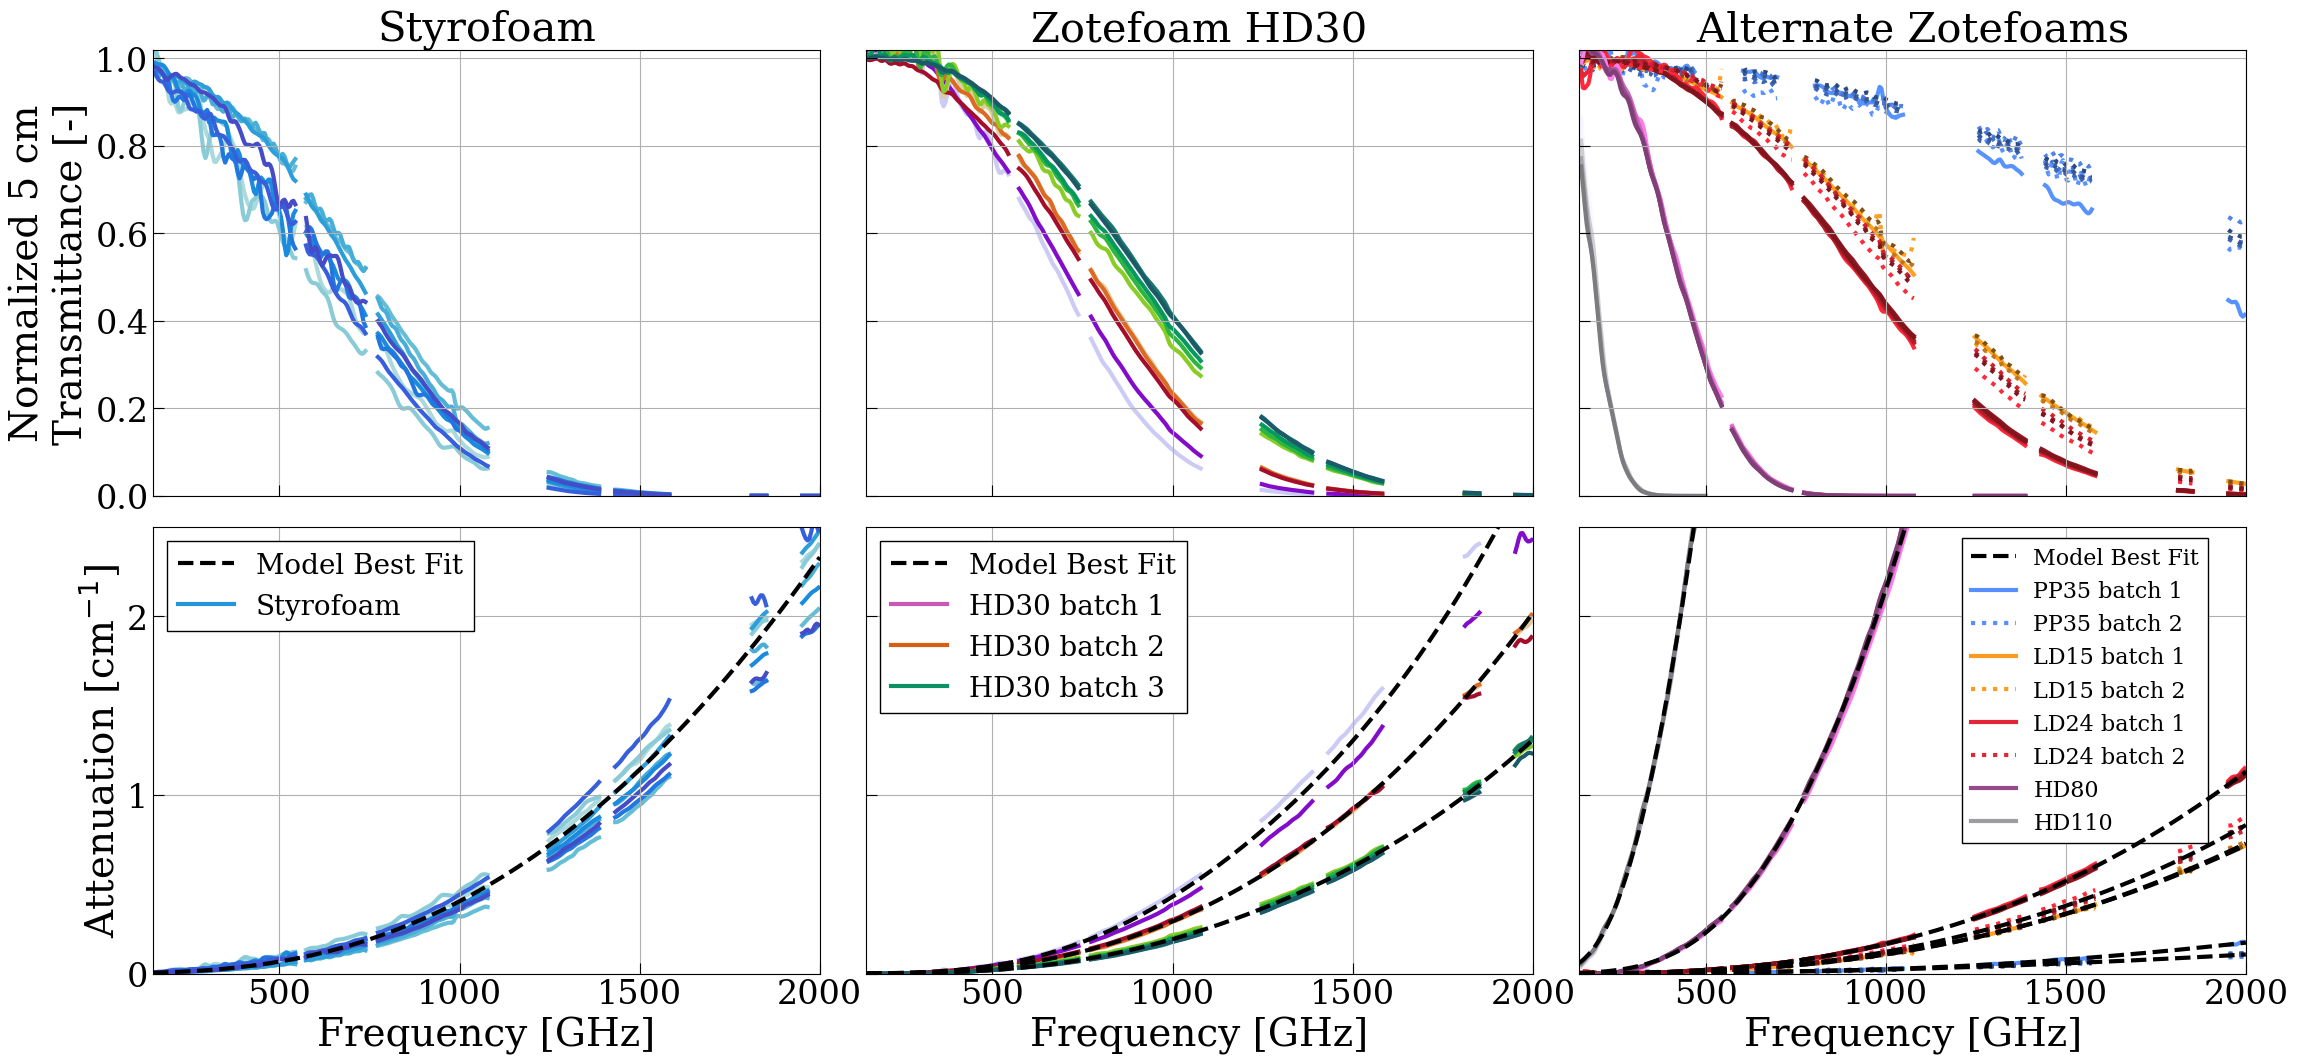

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(27, 12), sharex=True, sharey='row')

lw = 3
plt.xlim(150, 2000)
axes[0, 0].set_ylim(0, 1.02)
axes[1, 0].set_ylim(0, 2.5)
axes[0, 0].set_ylabel('Normalized 5 cm\nTransmittance [-]', fontsize=28)
axes[1, 0].set_ylabel(r'Attenuation [cm$^{-1}$]', fontsize=28)

for ax in axes[1, :]:
    ax.set_xlabel('Frequency [GHz]', fontsize=28)


for bname, b in batches.items():
    i = 0
    if bname in styro_batches:
        ax1 = axes[0, 0]
        ax2 = axes[1, 0]

    elif bname in HD30_batches:
        ax1 = axes[0, 1]
        ax2 = axes[1, 1]

    elif bname in other_zote_keys and bname != 'HD60 2.03 cm':
        ax1 = axes[0, 2]
        ax2 = axes[1, 2]

    else:
        continue

    for j, sample in enumerate(b):
        if '(2)' in sample:
            continue

        f_    = b[sample]['f']
        t     = b[sample]['t']
        alpha = b[sample]['alpha']
        err   = b[sample]['err']
        mask  = b[sample]['mask']

        ns_T = b[sample]['ns_T']
        ns_alpha = comb_batches[bname]['ns_alpha']
        width = b[sample]['width']
        ns_T_5cm = ns_T**(5/width)

        t_5cm_masked = np.where(mask, np.nan, t**(5/width))
        alpha_masked = np.where(mask, np.nan, alpha)

        color = b[sample]['color']

        zorder=-9 if sample == 'LD15 batch1 2.65 cm' else -10

        ls = ':' if 'batch2' in sample and bname in other_zote_keys else '-'

        ax1.plot(f_, t_5cm_masked, color=color, lw=lw, ls=ls, zorder=zorder)
        ax2.plot(f_, alpha_masked, color=color, lw=lw, ls=ls, zorder=zorder)

        # transform to display coordinates

        if i == 0:
            ax2.plot(f, ns_alpha, color='k', linestyle='--', lw=3, zorder=10)
            # ax1.plot(f, ns_T_5cm, color='k', linestyle='--', lw=3, zorder=10)

        i += 1

for ax in axes.flatten():
    ax.grid(True)

custom_line = mpl.lines.Line2D([0], [1], color='k', linestyle='--', lw=3, label='Model Best Fit')

styro_line  = mpl.lines.Line2D([0], [1], color=comb_batches['Styrofoam_batch1']['color'], lw=3, label='Styrofoam')

hd30_line1 = mpl.lines.Line2D([0], [1], color=comb_batches['HD30_batch1']['color'], lw=3, label='HD30 batch 1')
hd30_line2 = mpl.lines.Line2D([0], [1], color=comb_batches['HD30_batch2']['color'], lw=3, label='HD30 batch 2')
hd30_line3 = mpl.lines.Line2D([0], [1], color=comb_batches['HD30_batch3']['color'], lw=3, label='HD30 batch 3')

pp35_line  = mpl.lines.Line2D([0], [1], color=comb_batches['PP35_batch1']['color'], lw=3, label='PP35 batch 1')
pp35_line2 = mpl.lines.Line2D([0], [1], color=comb_batches['PP35_batch1']['color'], lw=3, ls=':', label='PP35 batch 2')
ld15_line1 = mpl.lines.Line2D([0], [1], color=comb_batches['LD15_batch1']['color'], lw=3, label='LD15 batch 1')
ld15_line2 = mpl.lines.Line2D([0], [1], color=comb_batches['LD15_batch2']['color'], lw=3, ls=':', label='LD15 batch 2')
ld24_line1 = mpl.lines.Line2D([0], [1], color=comb_batches['LD24_batch1']['color'], lw=3, label='LD24 batch 1')
ld24_line2 = mpl.lines.Line2D([0], [1], color=comb_batches['LD24_batch2']['color'], lw=3, ls=':', label='LD24 batch 2')
hd80_line  = mpl.lines.Line2D([0], [1], color=comb_batches['HD80_batch1']['color'], lw=3, label='HD80')
hd110_line = mpl.lines.Line2D([0], [1], color=comb_batches['HD110_batch1']['color'], lw=3, label='HD110')

handles = [custom_line, styro_line]

axes[1, 0].legend(handles=handles, loc='upper left', fontsize=20, framealpha=1, edgecolor='black', facecolor='white', fancybox=False)

handles = [custom_line, hd30_line1, hd30_line2, hd30_line3]
axes[1, 1].legend(handles=handles, loc='upper left', fontsize=20, framealpha=1, edgecolor='black', facecolor='white', fancybox=False)

handles = [custom_line, pp35_line, pp35_line2, ld15_line1, ld15_line2, ld24_line1, ld24_line2, hd80_line, hd110_line]
axes[1, 2].legend(handles=handles, loc='upper right', fontsize=16, framealpha=1, edgecolor='black', facecolor='white', fancybox=False, bbox_to_anchor=(0.96, 1.0))

axes[0, 0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
axes[1, 0].set_yticks([0, 1, 2])
axes[0, 0].set_title('Styrofoam', fontsize=30)
axes[0, 1].set_title('Zotefoam HD30', fontsize=30)
axes[0, 2].set_title('Alternate Zotefoams', fontsize=30)

plt.gcf().set_facecolor('white')
plt.subplots_adjust(wspace=0.07, hspace=0.07)
plt.savefig(f'spectras-e_{TAG}.pdf')
plt.show()

Tweaked version with context for SPIE poster

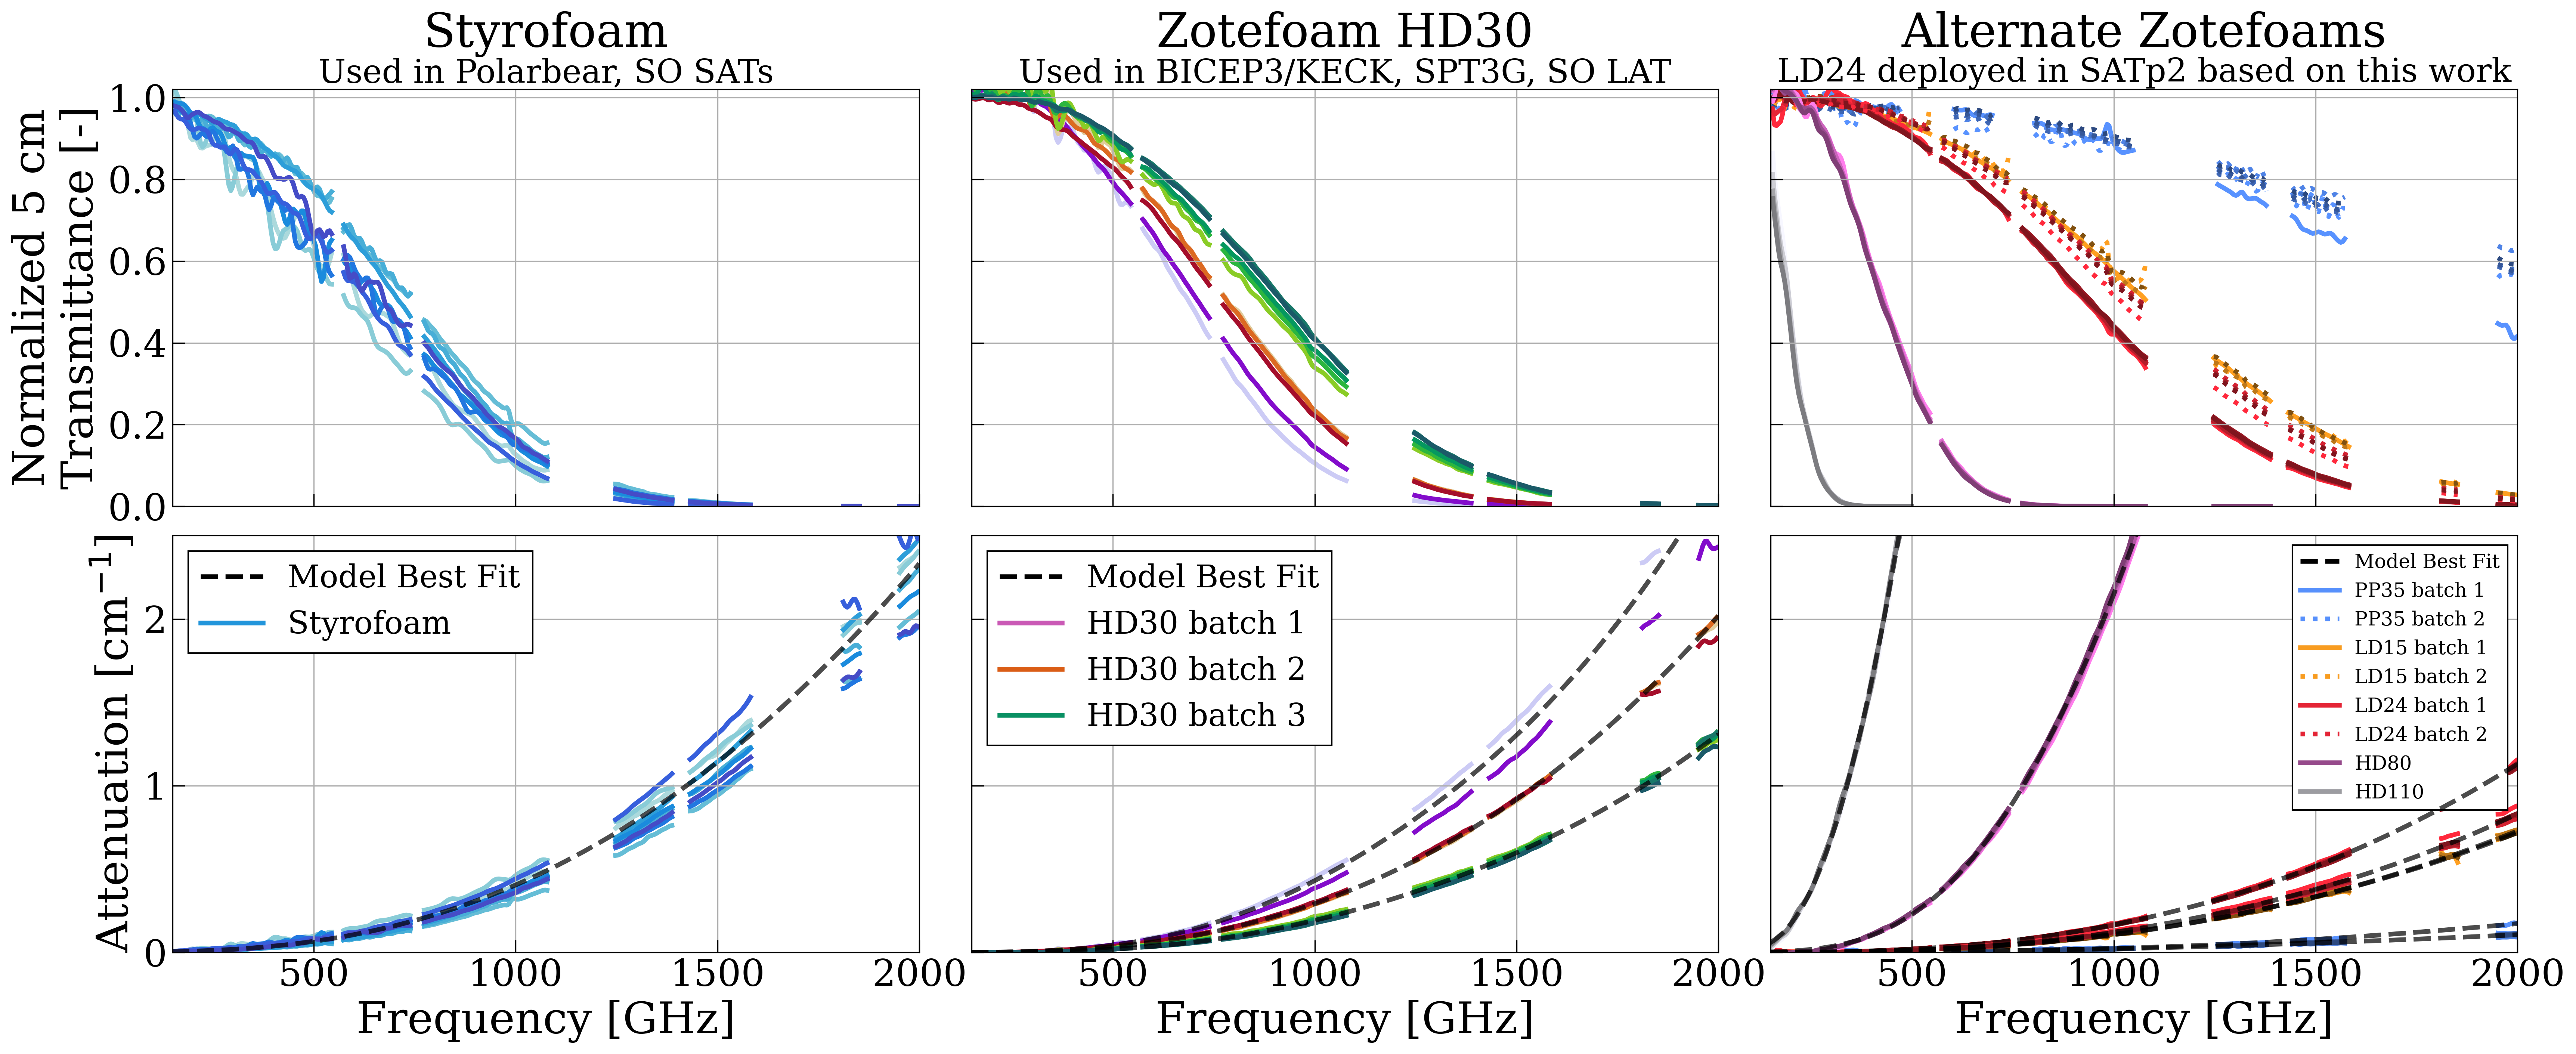

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(27, 10), sharex=True, sharey='row', dpi=300)

lw = 3
plt.xlim(150, 2000)
axes[0, 0].set_ylim(0, 1.02)
axes[1, 0].set_ylim(0, 2.5)
axes[0, 0].set_ylabel('Normalized 5 cm\nTransmittance [-]', fontsize=28)
axes[1, 0].set_ylabel(r'Attenuation [cm$^{-1}$]', fontsize=28)

for ax in axes[1, :]:
    ax.set_xlabel('Frequency [GHz]', fontsize=28)


for bname, b in batches.items():
    i = 0
    if bname in styro_batches:
        ax1 = axes[0, 0]
        ax2 = axes[1, 0]

    elif bname in HD30_batches:
        ax1 = axes[0, 1]
        ax2 = axes[1, 1]

    elif bname in other_zote_keys and bname != 'HD60 2.03 cm':
        ax1 = axes[0, 2]
        ax2 = axes[1, 2]

    else:
        continue

    for j, sample in enumerate(b):
        if '(2)' in sample:
            continue

        f_    = b[sample]['f']
        t     = b[sample]['t']
        alpha = b[sample]['alpha']
        err   = b[sample]['err']
        mask  = b[sample]['mask']

        ns_T = b[sample]['ns_T']
        ns_alpha = comb_batches[bname]['ns_alpha']
        width = b[sample]['width']
        ns_T_5cm = ns_T**(5/width)

        ls = ':' if 'batch2' in sample and bname in other_zote_keys else '-'

        t_5cm_masked = np.where(mask, np.nan, t**(5/width))
        alpha_masked = np.where(mask, np.nan, alpha)

        color = b[sample]['color']

        zorder=-9 if sample == 'LD15 batch1 2.65 cm' else -10

        ax1.plot(f_, t_5cm_masked, color=color, lw=lw, ls=ls, zorder=zorder)
        ax2.plot(f_, alpha_masked, color=color, lw=lw, zorder=zorder)

        # transform to display coordinates

        if i == 0:
            alpha=0.7
            ax2.plot(f, ns_alpha, color='k', linestyle='--', lw=3, alpha=alpha, zorder=10)
            # ax1.plot(f, ns_T_5cm, color='k', linestyle='--', lw=3, zorder=10)

        i += 1


for ax in axes.flatten():
    ax.grid(True)

custom_line = mpl.lines.Line2D([0], [1], color='k', linestyle='--', lw=3, label='Model Best Fit')

styro_line  = mpl.lines.Line2D([0], [1], color=comb_batches['Styrofoam_batch1']['color'], lw=3, label='Styrofoam')

hd30_line1 = mpl.lines.Line2D([0], [1], color=comb_batches['HD30_batch1']['color'], lw=3, label='HD30 batch 1')
hd30_line2 = mpl.lines.Line2D([0], [1], color=comb_batches['HD30_batch2']['color'], lw=3, label='HD30 batch 2')
hd30_line3 = mpl.lines.Line2D([0], [1], color=comb_batches['HD30_batch3']['color'], lw=3, label='HD30 batch 3')

pp35_line  = mpl.lines.Line2D([0], [1], color=comb_batches['PP35_batch1']['color'], lw=3, label='PP35 batch 1')
pp35_line2 = mpl.lines.Line2D([0], [1], color=comb_batches['PP35_batch1']['color'], lw=3, ls=':', label='PP35 batch 2')
ld15_line1 = mpl.lines.Line2D([0], [1], color=comb_batches['LD15_batch1']['color'], lw=3, label='LD15 batch 1')
ld15_line2 = mpl.lines.Line2D([0], [1], color=comb_batches['LD15_batch2']['color'], lw=3, ls=':', label='LD15 batch 2')
ld24_line1 = mpl.lines.Line2D([0], [1], color=comb_batches['LD24_batch1']['color'], lw=3, label='LD24 batch 1')
ld24_line2 = mpl.lines.Line2D([0], [1], color=comb_batches['LD24_batch2']['color'], lw=3, ls=':', label='LD24 batch 2')
hd80_line  = mpl.lines.Line2D([0], [1], color=comb_batches['HD80_batch1']['color'], lw=3, label='HD80')
hd110_line = mpl.lines.Line2D([0], [1], color=comb_batches['HD110_batch1']['color'], lw=3, label='HD110')

handles = [custom_line, styro_line]

axes[1, 0].legend(handles=handles, loc='upper left', fontsize=20, framealpha=1, edgecolor='black', facecolor='white', fancybox=False)

handles = [custom_line, hd30_line1, hd30_line2, hd30_line3]
axes[1, 1].legend(handles=handles, loc='upper left', fontsize=20, framealpha=1, edgecolor='black', facecolor='white', fancybox=False)

handles = [custom_line, pp35_line, pp35_line2, ld15_line1, ld15_line2, ld24_line1, ld24_line2, hd80_line, hd110_line]
axes[1, 2].legend(handles=handles, loc='upper right', fontsize=12.5, framealpha=1, edgecolor='black', facecolor='white', fancybox=False)

axes[0, 0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
axes[1, 0].set_yticks([0, 1, 2])
axes[0, 0].set_title('Styrofoam', fontsize=30, y=1.08)
axes[0, 0].annotate('Used in Polarbear, SO SATs', xy=(0.5, 1), xycoords='axes fraction', fontsize=21, ha='center', va='bottom')
axes[0, 1].set_title('Zotefoam HD30', fontsize=30, y=1.08)
axes[0, 1].annotate('Used in BICEP3/KECK, SPT3G, SO LAT', xy=(0.5, 1), xycoords='axes fraction', fontsize=21, ha='center', va='bottom')
axes[0, 2].set_title('Alternate Zotefoams', fontsize=30, y=1.08)
axes[0, 2].annotate('LD24 deployed in SATp2 based on this work', xy=(0.5, 1), xycoords='axes fraction', fontsize=21, ha='center', va='bottom')

plt.gcf().set_facecolor('white')
plt.subplots_adjust(wspace=0.07, hspace=0.07)
plt.savefig(f'spectras-poster_{TAG}.pdf')
plt.show()

In [31]:
rows = []

param_names = ["Loss tangent", "d_med [um]", "s", "C [1/cm]"]

for bname, b in comb_batches.items():
    if 'HD60' in bname:
        continue
    row = {"Sample": DISPLAY_MAP[bname]}

    # Get the parameters and uncertainties from the appropriate fit

    for i, pname in enumerate(param_names):
        val = float(b['params'][i])
        up  = float(b['upper_params'][i])
        lo  = float(b['lower_params'][i])

        if pname == 'Loss tangent':
                row[pname] = rf"$\sim {format_val(b['lt'])[1:]}"  # fixed, not fit
        else:
            row[pname] = format_unc(val, lo, up)

    val = b['n_eff']
    sig = b['n_eff_err']

    row["n_eff^2"] = format_unc_1sided(val, sig)

    rows.append(row)

df = pd.DataFrame(rows)

for _, row in df.iterrows():
    cells = [row["Sample"]] + [row[p] for p in param_names] + [row["n_eff^2"]]
    print(" & ".join(cells) + r" \\")

Styrofoam batch & $\sim 1.1\times10^{-4}$ & $4.1^{+7.3}_{-0.8}$ & $0.92^{+0.02}_{-0.13}$ & $3400^{+700}_{-1800}$ & $1.020(3)$ \\
HD30 batch 1 & $\sim 1.6\times10^{-5}$ & $70^{+9}_{-9}$ & $0.22^{+0.06}_{-0.06}$ & $4000^{+700}_{-500}$ & $1.0175(6)$ \\
HD30 batch 2 & $\sim 1.6\times10^{-5}$ & $41^{+7}_{-9}$ & $0.43^{+0.06}_{-0.05}$ & $3600^{+500}_{-300}$ & $1.014(1)$ \\
HD30 batch 3 & $\sim 1.6\times10^{-5}$ & $61^{+3}_{-3}$ & $0.24^{+0.02}_{-0.02}$ & $2300^{+110}_{-100}$ & $1.0148(6)$ \\
PP35 batch 1 & $\sim 3.7\times10^{-5}$ & $48^{+2}_{-6}$ & $0.09^{+0.09}_{-0.06}$ & $670^{+130}_{-50}$ & $1.01789(8)$ \\
PP35 batch 2 & $\sim 3.7\times10^{-5}$ & $150^{+10}_{-10}$ & $0.18^{+0.05}_{-0.04}$ & $15^{+2}_{-2}$ & $1.0202(9)$ \\
LD15 batch 1 & $\sim 7.6\times10^{-6}$ & $3.4^{+0.4}_{-0.2}$ & $0.876^{+0.007}_{-0.013}$ & $26000^{+1000}_{-2000}$ & $1.0090(1)$ \\
LD15 batch 2 & $\sim 7.6\times10^{-6}$ & $12^{+11}_{-6}$ & $0.68^{+0.10}_{-0.11}$ & $14000^{+10000}_{-6000}$ & $1.0069(7)$ \\
LD24 batch 1 

In [32]:
rows = []

param_names = ["Loss tangent", "d_med [um]", "s", "C [1/cm]"]

for bname, b in comb_batches.items():
    T_lower, ns_T, T_upper = b['T_lower_5cm'], b['ns_T_5cm'], b['T_upper_5cm']

    row = {"Sample": bname}

    row["Loss tangent"] = b['lt']  # fixed, not fit

    # --- parameters with uncertainties ---
    for i, pname in enumerate(param_names[1:], start=1):
        val = float(b['params'][i])
        up  = float(b['upper_params'][i])
        lo  = float(b['lower_params'][i])

        row[pname] = format_unc(val, lo, up)

    row["n_eff^2"] = rf"${b['n_eff']:.3f} \pm {b['n_eff_err']:.4f}$"

    # --- band-averaged transmittance ---
    for band_name, (lo_f, hi_f) in band_windows_full.items():
        sel = (f > lo_f) & (f < hi_f)

        val       = 100*float(np.mean(ns_T[sel]))
        upper_val = 100*float(np.mean(T_upper[sel]))
        lower_val = 100*float(np.mean(T_lower[sel]))

        up = upper_val - val
        lo = val - lower_val

        # row[f"T{band_name} [%]"] = format_unc(val, lo, up)

    rows.append(row)

df = pd.DataFrame(rows)
df

,Sample,Loss tangent,d_med [um],s,C [1/cm],n_eff^2
0,Styrofoam_batch1,0.000113,$4.1^{+7.3}_{-0.8}$,$0.92^{+0.02}_{-0.13}$,$3400^{+700}_{-1800}$,$1.020 \pm 0.0026$
1,HD30_batch1,0.000016,$70^{+9}_{-9}$,$0.22^{+0.06}_{-0.06}$,$4000^{+700}_{-500}$,$1.017 \pm 0.0006$
2,HD30_batch2,0.000016,$41^{+7}_{-9}$,$0.43^{+0.06}_{-0.05}$,$3600^{+500}_{-300}$,$1.014 \pm 0.0011$
3,HD30_batch3,0.000016,$61^{+3}_{-3}$,$0.24^{+0.02}_{-0.02}$,$2300^{+110}_{-100}$,$1.015 \pm 0.0006$
4,PP35_batch1,0.000037,$48^{+2}_{-6}$,$0.09^{+0.09}_{-0.06}$,$670^{+130}_{-50}$,$1.018 \pm 0.0001$
5,PP35_batch2,0.000037,$150^{+10}_{-10}$,$0.18^{+0.05}_{-0.04}$,$15^{+2}_{-2}$,$1.020 \pm 0.0009$
6,LD15_batch1,0.000008,$3.4^{+0.4}_{-0.2}$,$0.876^{+0.007}_{-0.013}$,$26000^{+1000}_{-2000}$,$1.009 \pm 0.0001$
7,LD15_batch2,0.000008,$12^{+11}_{-6}$,$0.68^{+0.10}_{-0.11}$,$14000^{+10000}_{-6000}$,$1.007 \pm 0.0007$
8,LD24_batch1,0.000012,$41^{+3}_{-3}$,$0.44^{+0.02}_{-0.02}$,$3000^{+200}_{-100}$,$1.013 \pm 0.0002$
9,LD24_batch2,0.000012,$56^{+4}_{-4}$,$0.28^{+0.03}_{-0.02}$,$2600^{+200}_{-200}$,$1.012 \pm 0.0005$


In [33]:
# bname = 'LD15_batch1'
bname = 'PP35_batch1'

ns_params = comb_batches[bname]['params']
n_eff     = comb_batches[bname]['n_eff']
alpha16, alpha50, alpha84 = comb_batches[bname]['alpha_lower'], comb_batches[bname]['ns_alpha'], comb_batches[bname]['alpha_upper']
lt = comb_batches[bname]['lt']

idx = np.argmin(np.abs(f - 200))
mu = np.exp(-0.1*alpha50[idx])
low = np.exp(-0.1*alpha84[idx])
up = np.exp(-0.1*alpha16[idx])
sig = (up - low)/2
print(f"Styrofoam per mm Tranmission @ 200 GHz: {mu:.5f}±{sig:.5f}")

idx = np.argmin(np.abs(f - 280))
loss = IRBF_abs(280, lt, 5, n_eff)
print(f"For a {w} cm filter\n-----")
print(f"loss @ 280 GHz: {loss:.2f}%")
mu = np.exp(-w * alpha50[idx])
low = np.exp(-w * alpha84[idx])
up = np.exp(-w * alpha16[idx])
sig = (up - low)/2
print(f"Tranmission @ 280 GHz: {mu:.3f}±{sig:.3f}")

ns_params = comb_batches[bname]['params']
n_eff     = comb_batches[bname]['n_eff']
alpha16, alpha50, alpha84 = comb_batches[bname]['alpha_lower'], comb_batches[bname]['ns_alpha'], comb_batches[bname]['alpha_upper']
lt = comb_batches[bname]['lt']

idx = np.argmin(np.abs(f - 280))
loss = IRBF_abs(280, lt, 5, n_eff)
print(f"For a {w} cm HD30 filter\n-----")
print(f"loss @ 280 GHz: {loss:.2f}%")
mu = np.exp(-w * alpha50[idx])
low = np.exp(-w * alpha84[idx])
up = np.exp(-w * alpha16[idx])
sig = (up - low)/2
print(f"Tranmission @ 280 GHz: {mu:.4f}±{sig:.4f}")

Styrofoam per mm Tranmission @ 200 GHz: 0.99984±0.00000
For a 5 cm filter
-----
loss @ 280 GHz: 1.09%
Tranmission @ 280 GHz: 0.988±0.000
For a 5 cm HD30 filter
-----
loss @ 280 GHz: 1.09%
Tranmission @ 280 GHz: 0.9884±0.0000


In [34]:
mu

np.float64(0.9884443498893035)

In [35]:
# comb_batches['HD60 2.03 cm']

In [36]:
bname = 'Styrofoam_batch1'
ba = comb_batches[bname]['band_avgs']

Sca, Sca_upper, Sca_lower = ba['280', 'Sca'], ba['280', 'Sca_upper'], ba['280', 'Sca_lower']

print(f"Batch: {bname}")
print("280 GHz scattering loss, 5 cm [%]:", format_unc(Sca, Sca_lower, Sca_upper))
print('-'*27, end='\n\n')

Batch: Styrofoam_batch1
280 GHz scattering loss, 5 cm [%]: $4.8^{+0.2}_{-0.2}$
---------------------------



In [37]:
Scatters = []
for bname in HD30_batches:
    Scatters.append(float(comb_batches[bname]['band_avgs'][('280', 'Sca')]))

Scatter = np.mean(Scatters)
Scatter_std = np.std(Scatters)

print(f"280 GHz Scattering for HD30 (over all batches): {Scatter:.1f}% ±{Scatter_std:.1f}%")

280 GHz Scattering for HD30 (over all batches): 1.8% ±0.6%


In [38]:
for bname in ['LD24_batch2', 'PP35_batch1', 'PP35_batch2']:
    ba = comb_batches[bname]['band_avgs']
    Scatter, Scatter_upper, Scatter_lower = float(ba[('280', 'Sca')]), float(ba[('280', 'Sca_upper')]), float(ba[('280', 'Sca_lower')])
    print(f"280 GHz Scattering for {bname}: {Scatter:.5f}% +{Scatter_upper:.5f}% -{Scatter_lower:.5f}%")

280 GHz Scattering for LD24_batch2: 0.67086% +0.01309% -0.01169%
280 GHz Scattering for PP35_batch1: 0.06526% +0.00093% -0.00083%
280 GHz Scattering for PP35_batch2: 0.17081% +0.00742% -0.00731%


In [39]:
bname = 'LD24_batch2'
## Difference
# bname2 = 'Styrofoam_batch2'
bname2 = 'PP35_batch1'

def band_val(bname, comp, band='280'):
    ba = comb_batches[bname]['band_avgs']
    return float(ba[(band, f'{comp}_lower')]), float(ba[(band, comp)]), float(ba[(band, f'{comp}_upper')])

print(f"280 GHz difference between {bname} and {bname2}:")
for comp, label in [('Sca', 'Scattering'), ('Abs', 'Absorption')]:
    lo1, v1, up1 = band_val(bname, comp)
    lo2, v2, up2 = band_val(bname2, comp)
    print(f"{label}: {v1 - v2:.2f} +{np.sqrt(up1**2 + lo2**2):.2f} -{np.sqrt(lo1**2 + up2**2):.2f}")

280 GHz difference between LD24_batch2 and PP35_batch1:
Scattering: 0.61 +0.01 -0.01
Absorption: -0.73 +1.17 -1.17


## Optical Loading Table

In [40]:
from scipy.constants import k
Tphys = 273
Npol = 1

bands = ['90', '150', '220', '280']
bandwidths = [35.0, 45.0, 45.0, 65.0]  # GHz

loading_batches = [
    ('Styrofoam', comb_batches['Styrofoam_batch1']),
    # ('LD15', comb_batches['LD15 batch1 2.65 cm']),
    # ('LD24', comb_batches['LD24 batch1 2.60 cm']),
    ('HD30', comb_batches['HD30_batch3']),
]

for name, b in loading_batches:

    row_entries_odd = [name]
    row_entries_even = ['']

    for i, (band, dnu) in enumerate(zip(bands, bandwidths)):

        row_entries = row_entries_odd if i % 2 == 0 else row_entries_even

        Abs = float(b['band_avgs'][(band, 'Abs')]) / 100.0

        T_RJ = Tphys * Abs
        P = Npol * k * T_RJ * dnu * 1e21   # convert GHz Ã¢â€ â€™ Hz and Watts Ã¢â€ â€™ pW

        if name in ['Thin Sheets 1 (Worst)', 'Thick Sheets 2 (Best)', 'Representative Filter']:
            Abs_lower = float(b['band_avgs'][(band, 'Abs_lower')]) / 100.0
            Abs_upper = float(b['band_avgs'][(band, 'Abs_upper')]) / 100.0  
            T_RJ_lower = Tphys * Abs_lower
            T_RJ_upper = Tphys * Abs_upper
            P_lower = Npol * k * T_RJ_lower * dnu * 1e21
            P_upper = Npol * k * T_RJ_upper * dnu * 1e21

            row_entries.extend([
                format_unc(Abs, Abs_lower, Abs_upper, sci_thresh=0.01),
                format_unc(T_RJ, T_RJ_lower, T_RJ_upper, sci_thresh=0.01),
                format_unc(P, P_lower, P_upper, sci_thresh=0.01),
            ])
                
        elif name in ['LD15', 'LD24', 'HD30']:
            row_entries.extend([
                format_val(Abs),
                format_val(T_RJ),
                format_val(P)
            ])

        else:
            row_entries.extend([
                f"{Abs:.4f}",
                f"{T_RJ:.2f}",
                f"{P:.2f}"
            ])

    print(" & ".join(row_entries_odd) + r" \\")
    print(" & ".join(row_entries_even) + r" \\[6pt]")

Styrofoam & 0.0111 & 3.04 & 1.47 & 0.0268 & 7.33 & 4.55 \\
 & 0.0171 & 4.66 & 2.90 & 0.0336 & 9.17 & 8.23 \\[6pt]
HD30 & $1.5\times10^{-3}$ & $0.42$ & $0.20$ & $3.8\times10^{-3}$ & $1.02$ & $0.64$ \\
 & $2.4\times10^{-3}$ & $0.65$ & $0.40$ & $4.7\times10^{-3}$ & $1.29$ & $1.15$ \\[6pt]


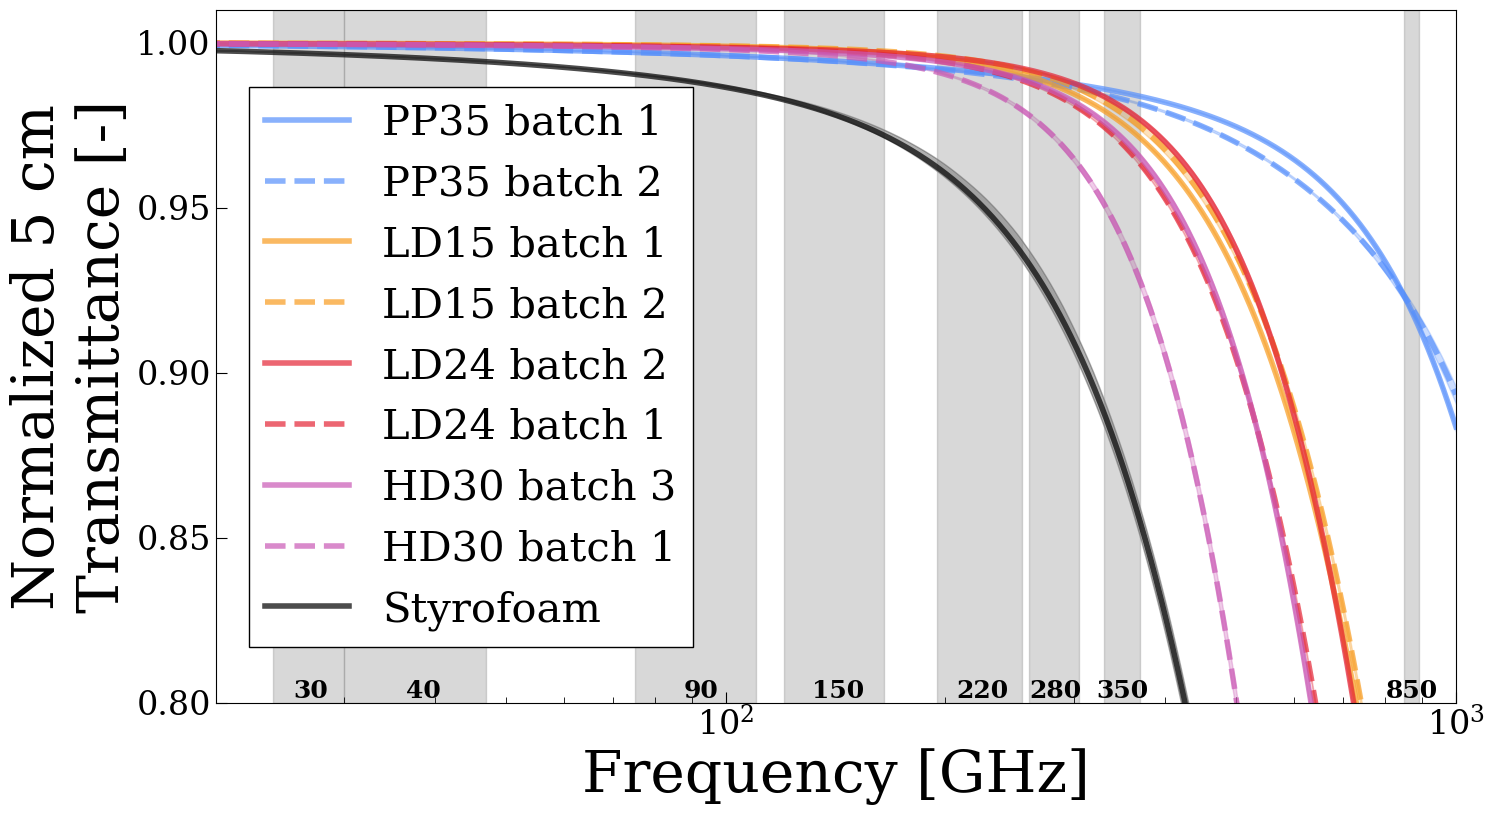

In [41]:
from matplotlib.ticker import NullFormatter

DISPLAY_MAP2 = {
    "PP35_batch1": ["PP35 batch 1", colors[0], '-'],
    "PP35_batch2": ["PP35 batch 2", colors[0], '--'],
    "LD15_batch1": ["LD15 batch 1", colors[1], '-'],
    "LD15_batch2": ["LD15 batch 2", colors[1], '--'],
    "LD24_batch2": ["LD24 batch 2", colors[2], '-'],
    "LD24_batch1": ["LD24 batch 1", colors[2], '--'],
    "HD30_batch3": ["HD30 batch 3", comb_batches['HD30_batch1']['color'], '-'],
    "HD30_batch1": ["HD30 batch 1", comb_batches['HD30_batch1']['color'], '--'],
    "Styrofoam_batch1": ["Styrofoam", 'k', '-'],
}

fig, ax = plt.subplots(figsize=(16, 9), dpi=100)

# Plot measurements and fits
for bname in DISPLAY_MAP2.keys():
    b = comb_batches[bname]
    label, color, ls = DISPLAY_MAP2[bname]

    ns_T = b['ns_T_5cm']
    ns_T_upper = b['T_upper_5cm']
    ns_T_lower = b['T_lower_5cm']

    ns_T_upper2 = 2*ns_T_upper - ns_T
    ns_T_lower2 = 2*ns_T_lower - ns_T

    if bname not in ['LD15 batch1 2.65 cm', 'LD24 batch1 2.60 cm']:
        plt.fill_between(f, ns_T_lower2, ns_T_upper2, color=color, alpha=0.3)

    plt.plot(f, ns_T, color=color, lw=4, label=label, linestyle=ls, alpha=0.7)

xticks = []
for band, (i, j) in band_windows_full.items():
    plt.axvspan(i, j, color='gray', alpha=0.3)
    plt.text((i+j)/2, 0.80, band, horizontalalignment='center', verticalalignment='bottom', fontsize=18, color='black', fontweight='bold')

ax.legend(loc='lower left', bbox_to_anchor=(0.01, 0.05), fontsize=30, edgecolor='black', facecolor='white', framealpha=1, fancybox=False)

plt.xlim(20, 1000)
ax.yaxis.set_major_locator(MultipleLocator(0.05))
plt.ylim(0.8, 1.01)
plt.xscale('log')
ax.xaxis.set_minor_formatter(NullFormatter())

plt.xlabel('Frequency [GHz]', fontsize=42)
plt.ylabel('Normalized 5 cm\nTransmittance [-]', fontsize=42)
plt.gcf().set_facecolor('white')
plt.savefig(f'5cm_spectra-d_{TAG}.pdf', bbox_inches='tight', facecolor='white')
plt.show()

In [42]:
rows = []

# header = ["Sample"] + [f"T{band} [%]" for band in band_windows_full.keys()]
# rows.append(dict(zip(header, header)))

for bname, b in list(comb_batches.items()):
    if bname not in ['Styrofoam_batch1', 'LD15 batch1 2.65 cm', 'LD15 batch2 0.30 cm', 'LD24 batch1 2.60 cm', 'LD24 batch2 0.34 cm', 'HD30_batch1', 'HD30_batch2', 'HD30_batch3', 'HD80', 'HD110']:
        continue

    row = {"Sample": bname}
    
    T_lower, ns_T, T_upper = b['T_lower_5cm'], b['ns_T_5cm'], b['T_upper_5cm']

    # --- band-averaged transmittance ---
    for band_name, (lo_f, hi_f) in band_windows_full.items():
        sel = (f > lo_f) & (f < hi_f)

        val = 100*float(np.mean(ns_T[sel]))
        upper_val = 100*float(np.mean(T_upper[sel]))
        lower_val = 100*float(np.mean(T_lower[sel]))

        up = upper_val - val
        lo = val - lower_val

        row[f"T{band_name} [%]"] = format_unc(val, lo, up)

    rows.append(row)

df = pd.DataFrame(rows)
df

# for _, row in df.iterrows():
#     cells = [row["Sample"]] + [row[f"T{band} [%]"] for band in band_windows_full.keys()]
#     print(" & ".join(cells) + r" \\")

,Sample,T30 [%],T40 [%],T90 [%],T150 [%],T220 [%],T280 [%],T350 [%],T850 [%]
0,Styrofoam_batch1,$99.6729^{+0.0003}_{-0.0001}$,$99.5307^{+0.0011}_{-0.0005}$,$98.767^{+0.019}_{-0.008}$,$97.76^{+0.06}_{-0.03}$,$94.99^{+0.17}_{-0.09}$,$92.0^{+0.2}_{-0.1}$,$87.2^{+0.2}_{-0.2}$,$24.4^{+0.4}_{-0.3}$
1,HD30_batch1,$99.954817^{+0.000005}_{-0.000005}$,$99.93492^{+0.00002}_{-0.00002}$,$99.8144^{+0.0006}_{-0.0007}$,$99.590^{+0.003}_{-0.004}$,$98.60^{+0.02}_{-0.02}$,$97.10^{+0.04}_{-0.04}$,$93.99^{+0.07}_{-0.08}$,$24.2^{+0.5}_{-0.5}$
2,HD30_batch2,$99.95470^{+0.00001}_{-0.00002}$,$99.93483^{+0.00006}_{-0.00008}$,$99.818^{+0.002}_{-0.002}$,$99.61^{+0.01}_{-0.01}$,$98.76^{+0.05}_{-0.06}$,$97.5^{+0.1}_{-0.1}$,$95.0^{+0.2}_{-0.2}$,$37.9^{+0.1}_{-0.1}$
3,HD30_batch3,$99.954824^{+0.000002}_{-0.000002}$,$99.935313^{+0.000007}_{-0.000008}$,$99.8324^{+0.0002}_{-0.0002}$,$99.690^{+0.001}_{-0.001}$,$99.190^{+0.007}_{-0.007}$,$98.50^{+0.02}_{-0.02}$,$97.08^{+0.03}_{-0.03}$,$53.3^{+0.2}_{-0.2}$


# Estimating Cell Sizes

In [43]:
## Nominal cell sizes for comparison
comb_batches['LD15_batch1']['cell_size'] = 380e-6
comb_batches['LD15_batch2']['cell_size'] = 380e-6
comb_batches['LD24_batch1']['cell_size'] = 300e-6
comb_batches['LD24_batch2']['cell_size'] = 300e-6
comb_batches['HD30_batch1']['cell_size']  = 400e-6
comb_batches['HD30_batch2']['cell_size']  = 400e-6
comb_batches['HD30_batch3']['cell_size']  = 400e-6
# comb_batches['HD60 2.03 cm']['cell_size'] = 400e-6
comb_batches['HD80_batch1']['cell_size'] = 600e-6
comb_batches['HD110_batch1']['cell_size'] = 1050e-6
comb_batches['PP35_batch1']['cell_size']  = 50e-6  # July pre-production sheet, microscope estimate in the draft
comb_batches['PP35_batch2']['cell_size']  = 150e-6 # Technifab: Zotefoams PP datasheet value

## R+M+a_RM length-scale inversion (Eqs. 15-16), evaluated on the R+M+a_RM pkls for comparison
def _cm_factor(n_p):
    np2 = n_p**2
    return np.abs((np2 + 2)*(1 + 2*np2) - 2*(np2 - 1)**2) / np.abs((1 + 2*np2)*(np2 - 1))

def eff_cell_diameter(K_Mie_GHz, K_Ray_GHz, n_p=1.54, n_m=1.0003, c=3e8):
    m   = n_p / n_m
    return c * (m - 1) * K_Mie_GHz*1e9 / (n_m * np.pi * np.sqrt(6) * (K_Ray_GHz*1e9)**2) * _cm_factor(n_p)

def eff_wall_thickness(K_Mie_GHz, d, C, f_m, n_p=1.54, n_m=1.0003, c=3e8):
    m   = n_p / n_m
    C_m = C * 100
    return c / (2 * n_m * np.pi * (m - 1) * K_Mie_GHz*1e9) * np.sqrt(C_m * d / (6 * f_m))

def wall_thickness(d, f_m):
    return d/2 * (1 - f_m**(1/3))

rows = []
for bname, b in comb_batches.items():
    d_med, s, C = b['samples'][:, 1], b['samples'][:, 2], b['samples'][:, 3]
    cl = wall_factor(b['f_m'])
    d_32 = d_med*np.exp(2.5*s**2)                                  # Sauter mean (volume / area)
    C_geo = 1.5*b['f_m']/(d_32*1e-4)                               # encounters per cm, cells of these sizes filling f_m [cm^-1]

    ## Log-normal number distribution of cell diameters
    derived = {
        'd_med':   d_med,                                          # number-weighted median
        'd_lo':    d_med*np.exp(-s),                               # 68% of cells between d_lo and d_hi
        'd_hi':    d_med*np.exp(s),
        'd_mean':  d_med*np.exp(s**2/2),
        'd_std':   d_med*np.exp(s**2/2)*np.sqrt(np.exp(s**2) - 1),
        'd_32':    d_32,
        's':       s,
        'C':       C,
        'C_geo':   C_geo,
        'C/C_geo': C/C_geo,                                        # the 2026-10-13 parameter A
        'C/C_sf':  C*d_32*1e-4/1.5,                                # against space-filling cells holding all of the polymer, 3/(2 d_32)
        'ell_eff': cl*d_med*np.sqrt(C/C_geo),                      # wall thickness for which the encounters are geometric, at d_med
    }
    q = {key: np.percentile(val, [16, 50, 84]) for key, val in derived.items()}

    def fmt(key, nd=0):
        lo, md, hi = q[key]
        return f"{md:.{nd}f} +{hi - md:.{nd}f}/-{md - lo:.{nd}f}"

    row = {
        "sample":            bname,
        "density [kg/m^3]":  b["density"],
        "d_th [um]":         f"{b['cell_size']*1e6:.0f}" if 'cell_size' in b else '',
        "d_med [um]":        fmt('d_med'),
        "68% of cells [um]": f"{q['d_lo'][1]:.0f}-{q['d_hi'][1]:.0f}",
        "mean ± std [um]":   f"{q['d_mean'][1]:.0f} ± {q['d_std'][1]:.0f}",
        "d_32 [um]":         fmt('d_32'),
        "s":                 fmt('s', 2),
        "C [1/cm]":          fmt('C'),
        "C_geo [1/cm]":      fmt('C_geo'),
        "C/C_geo":           fmt('C/C_geo', 2),
        "C/C_sf":            fmt('C/C_sf', 2),
        "ell_th [um]":       f"{wall_thickness(b['cell_size'], b['f_m'])*1e6:.2f}" if 'cell_size' in b else '',
        "ell_eff [um]":      fmt('ell_eff', 2),
    }

    if bname in RMA and any(key in bname for key in ('HD', 'LD', 'PP35')):  # R+M+a_RM fit of the same data (fit cell)
        med_rma = np.median(RMA[bname]['samples'], axis=0)
        C_rma, K_Ray_rma, K_Mie_rma = med_rma[1], med_rma[2], med_rma[3]
        d_inv = eff_cell_diameter(K_Mie_rma, K_Ray_rma, n_p=b['n_p'])
        row["d R+M+a Eq.15 [um]"]   = f"{d_inv*1e6:.0f}"
        row["ell R+M+a Eq.16 [um]"] = f"{eff_wall_thickness(K_Mie_rma, d_inv, C_rma, b['f_m'], n_p=b['n_p'])*1e6:.2f}"

    rows.append(row)

df = pd.DataFrame(rows).set_index("sample").sort_values("density [kg/m^3]")
df

,density [kg/m^3],d_th [um],d_med [um],68% of cells [um],mean ± std [um],d_32 [um],s,C [1/cm],C_geo [1/cm],C/C_geo,C/C_sf,ell_th [um],ell_eff [um],d R+M+a Eq.15 [um],ell R+M+a Eq.16 [um]
sample,,,,,,,,,,,,,,,
LD15_batch1,15.0,380,3 +0/-0,1-8,5 ± 5,23 +1/-1,0.88 +0.01/-0.01,26175 +1240/-2197,636 +17/-31,41.13 +0.84/-1.51,40.52 +0.83/-1.49,0.95,0.05 +0.01/-0.00,83,0.84
LD15_batch2,15.0,380,12 +11/-6,6-23,15 ± 11,37 +13/-10,0.68 +0.10/-0.11,13945 +10095/-5711,397 +146/-104,35.08 +9.25/-6.95,34.56 +9.12/-6.85,0.95,0.17 +0.12/-0.07,95,0.80
LD24_batch2,24.0,300,56 +4/-4,42-74,58 ± 17,68 +2/-2,0.28 +0.03/-0.02,2622 +186/-159,215 +8/-7,12.20 +0.44/-0.40,11.90 +0.43/-0.39,1.24,0.81 +0.04/-0.05,307,0.54
LD24_batch1,24.0,300,41 +3/-3,26-63,45 ± 21,66 +2/-2,0.44 +0.02/-0.02,3017 +176/-141,222 +8/-7,13.60 +0.30/-0.25,13.26 +0.30/-0.25,1.24,0.62 +0.04/-0.04,102,0.99
HD30_batch3,30.0,400,61 +3/-3,48-78,63 ± 16,71 +2/-2,0.24 +0.02/-0.02,2305 +109/-98,205 +5/-4,11.23 +0.28/-0.27,10.89 +0.27/-0.26,2.04,1.04 +0.04/-0.04,440,0.54
HD30_batch2,30.0,400,41 +7/-9,27-62,44 ± 20,64 +4/-6,0.43 +0.06/-0.05,3571 +548/-281,228 +24/-14,15.73 +0.69/-0.45,15.25 +0.67/-0.44,2.04,0.82 +0.15/-0.16,101,1.23
HD30_batch1,30.0,400,70 +9/-9,56-87,72 ± 16,79 +5/-6,0.22 +0.06/-0.06,3951 +691/-501,185 +15/-12,21.35 +1.93/-1.53,20.70 +1.88/-1.48,2.04,1.65 +0.16/-0.16,1181,0.53
PP35_batch2,35.0,150,148 +12/-15,124-177,150 ± 27,161 +9/-10,0.18 +0.05/-0.04,15 +2/-2,90 +6/-5,0.17 +0.02/-0.01,0.16 +0.02/-0.01,0.95,0.38 +0.02/-0.03,36,0.32
PP35_batch1,35.0,50,48 +2/-6,43-51,48 ± 4,48 +1/-3,0.09 +0.09/-0.06,666 +125/-54,298 +23/-9,2.24 +0.23/-0.12,2.15 +0.22/-0.11,0.32,0.45 +0.01/-0.04,895,0.11


# Custom loss plots

Secondary scattering matters for HD110 in band, matters for HD80 after ~300 GHz.

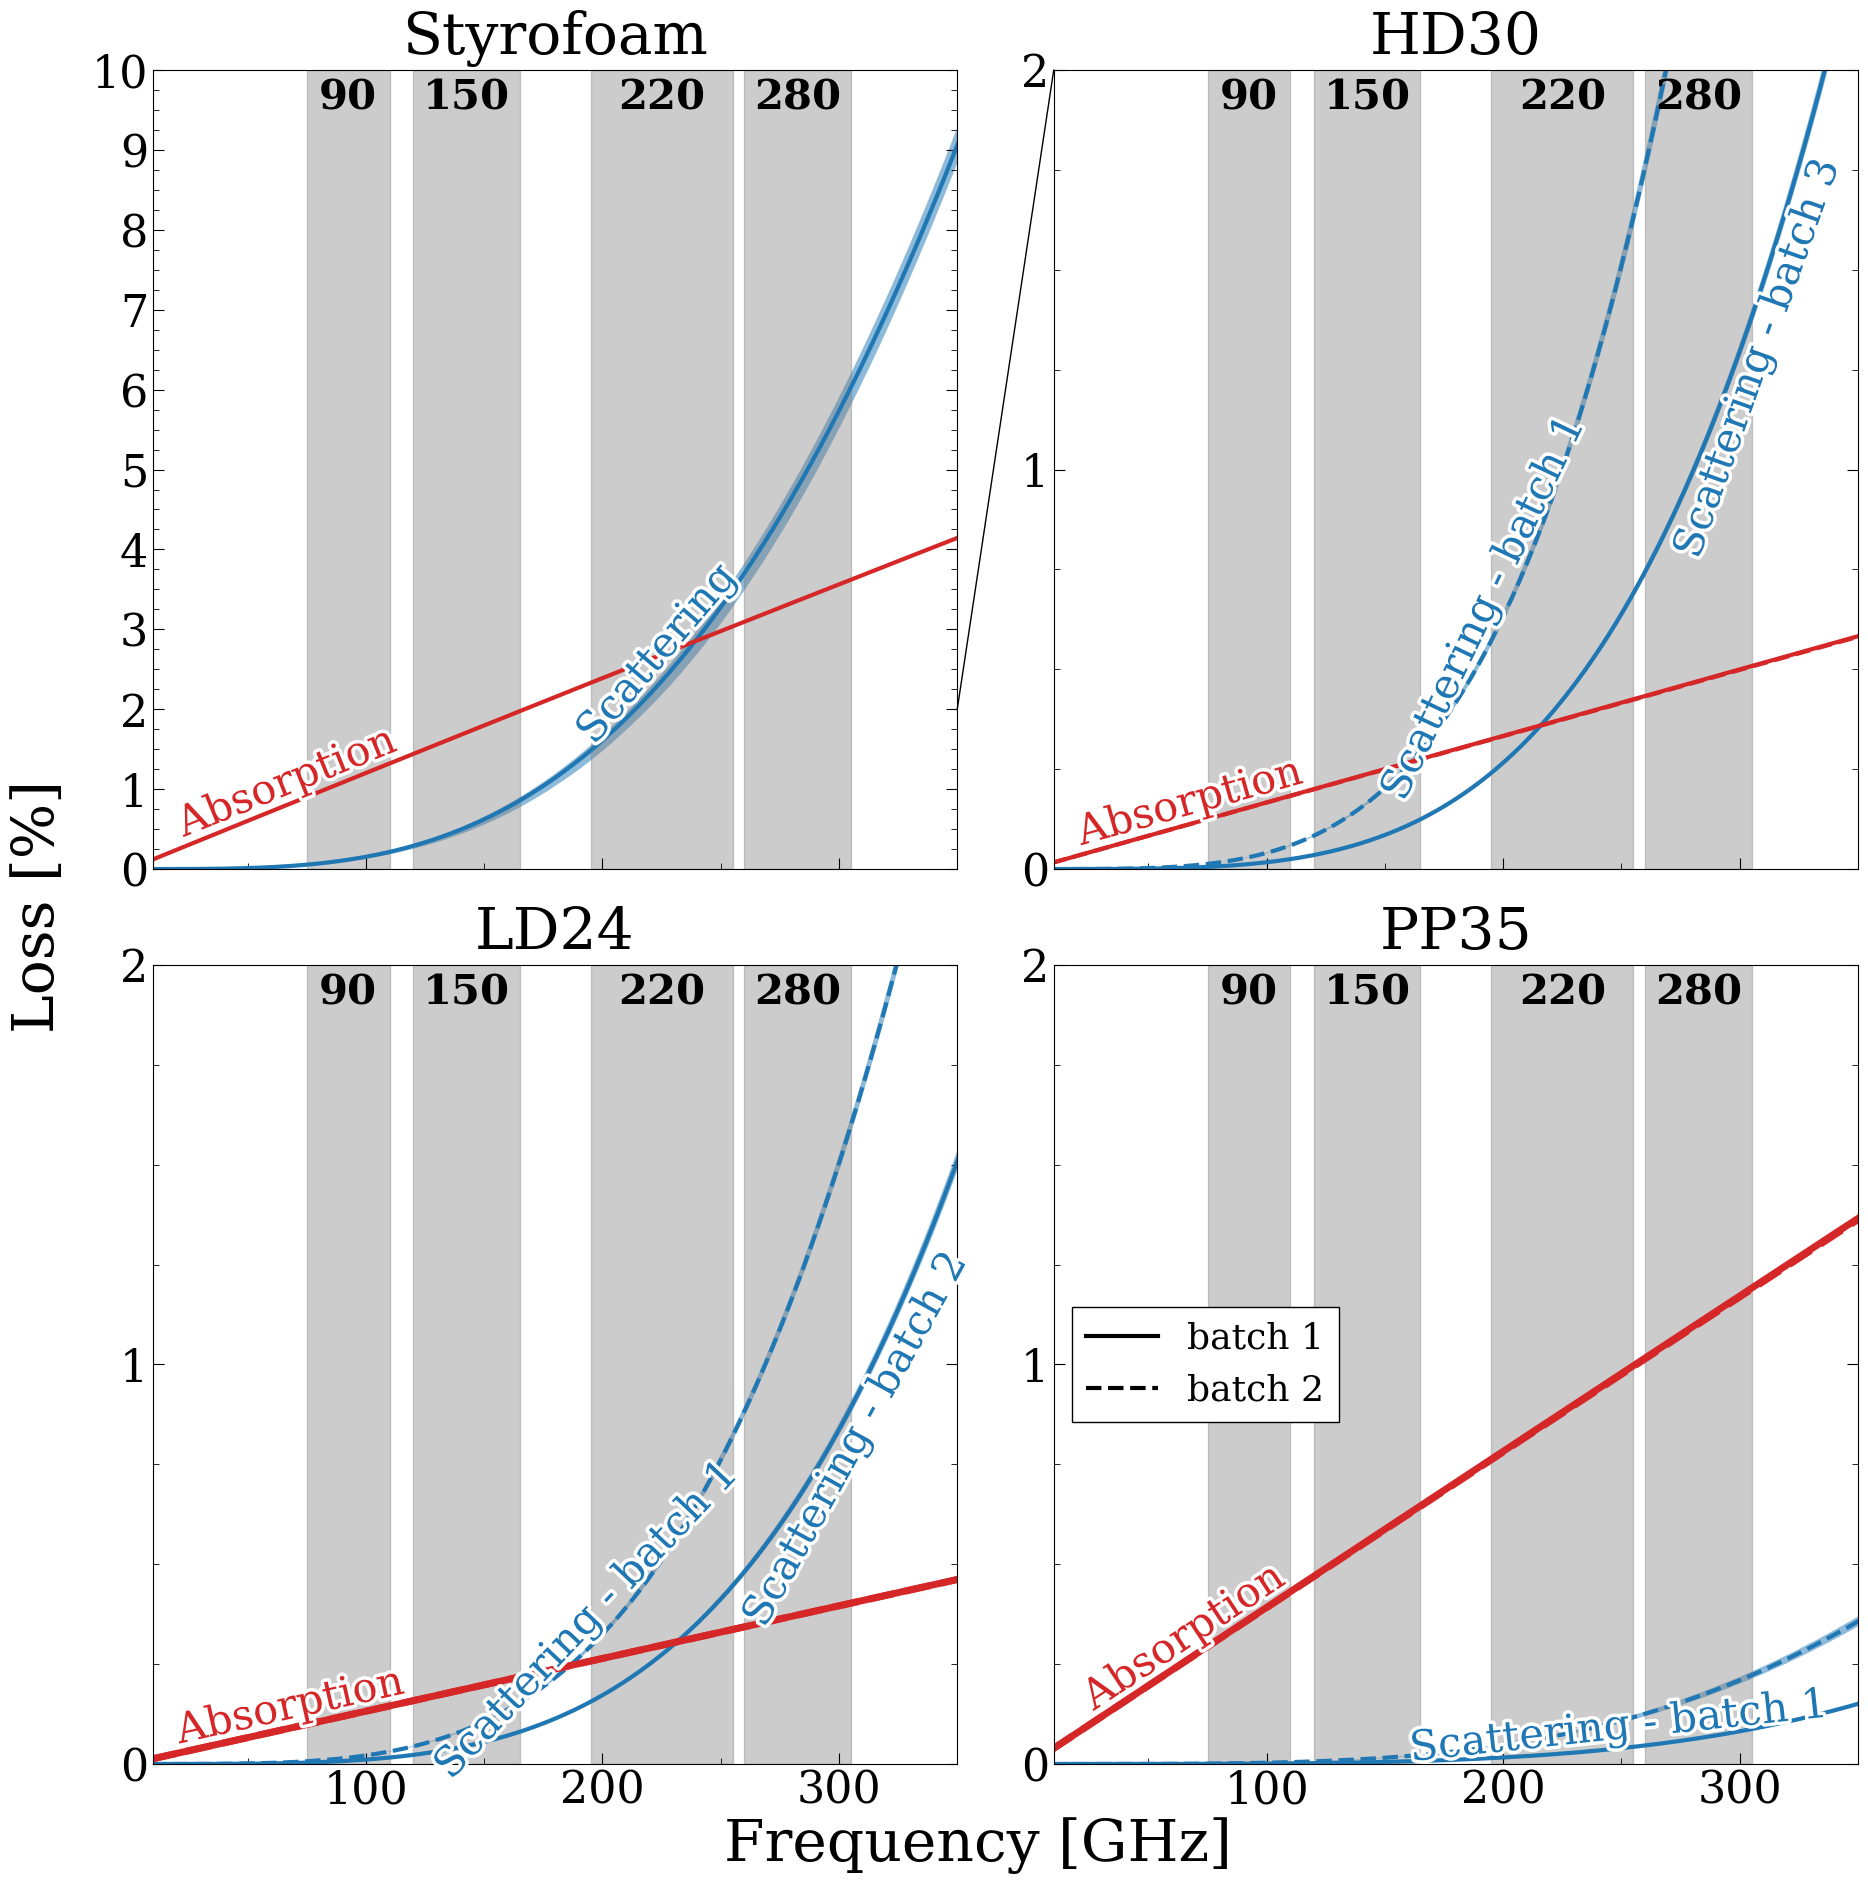

In [44]:
from matplotlib.patches import ConnectionPatch

def label_curve(ax, arr, freq, text, color, va='bottom', fs=30):
    idx = np.argmin(np.abs(f - freq))
    p0 = ax.transData.transform((f[idx-10], arr[idx-10]))
    p1 = ax.transData.transform((f[idx+10], arr[idx+10]))
    angle = np.degrees(np.arctan2(p1[1]-p0[1], p1[0]-p0[0]))
    ax.text(f[idx], arr[idx], text, color=color, fontsize=fs, ha='center', va=va, rotation=angle, rotation_mode='anchor', zorder=10)

def plot_losses(ax, bname, ls='-', abs_lw=3):
    est = comb_batches[bname]["estimates"]
    Abs, Sca = est["Abs"], est["Sca"]
    ax.plot(f, Sca['arr'], color=Sca['color'], lw=3, ls=ls, zorder=2)
    ax.fill_between(f, Sca['upper'], Sca['lower'], color=Sca['color'], edgecolor='none', alpha=0.5, zorder=0)
    ax.plot(f, Abs['arr'], color=Abs['color'], lw=abs_lw, ls=ls, zorder=2)
    return Abs, Sca

def loss_figure(fig, axes):
    ax0, ax1, ax2, ax3 = axes
    for ax in axes:
        ax.set_rasterization_zorder(1)
        ax.set_xlim(10, 350)
        ax.set_ylim(0, 2)
    ax0.set_ylim(0, 10)

    ## Styrofoam
    Abs, Sca = plot_losses(ax0, 'Styrofoam_batch1')
    fig.canvas.draw()
    label_curve(ax0, Sca['arr'], 230, 'Scattering', Sca['color'])
    label_curve(ax0, Abs['arr'], 70, 'Absorption', Abs['color'])
    ax0.set_title('Styrofoam', y=1.01, fontsize=42)

    ## HD30 batches 1 (dashed) and 3 (solid)
    Abs1, Sca1 = plot_losses(ax1, 'HD30_batch1', ls='--')
    Abs3, Sca3 = plot_losses(ax1, 'HD30_batch3', ls='-')
    fig.canvas.draw()
    label_curve(ax1, Sca1['arr'], 200, 'Scattering - batch 1', Sca1['color'])
    label_curve(ax1, Sca3['arr'], 300, 'Scattering - batch 3', Sca3['color'], va='top')
    label_curve(ax1, Abs1['arr'], 70, 'Absorption', Abs1['color'])
    ax1.set_title('HD30', y=1.01, fontsize=42)

    ## LD24 batches 1 (dashed) and 2 (solid)
    Abs1, Sca1 = plot_losses(ax2, 'LD24_batch1', ls='--', abs_lw=5)
    Abs2, Sca2 = plot_losses(ax2, 'LD24_batch2', ls='-', abs_lw=5)
    fig.canvas.draw()
    label_curve(ax2, Sca1['arr'], 200, 'Scattering - batch 1', Sca1['color'])
    label_curve(ax2, Sca2['arr'], 300, 'Scattering - batch 2', Sca2['color'], va='top')
    label_curve(ax2, Abs2['arr'], 70, 'Absorption', Abs2['color'])
    ax2.set_title('LD24', y=1.01, fontsize=42)

    ## PP35 batches 1 (solid) and 2 (dashed)
    plot_losses(ax3, 'PP35_batch2', ls='--', abs_lw=5)
    Abs, Sca = plot_losses(ax3, 'PP35_batch1', abs_lw=5)
    fig.canvas.draw()
    label_curve(ax3, Sca['arr'], 250, 'Scattering - batch 1', Sca['color'])
    label_curve(ax3, Abs['arr'], 70, 'Absorption', Abs['color'])
    ax3.set_title('PP35', y=1.01, fontsize=42)
    ax3.legend(handles=[mpl.lines.Line2D([0], [1], color='k', lw=3, ls='-', label='batch 1'),
                        mpl.lines.Line2D([0], [1], color='k', lw=3, ls='--', label='batch 2')],
               loc='center left', fontsize=26, framealpha=1, edgecolor='black', facecolor='white', fancybox=False)

    ## General
    for ax in axes:
        ax.yaxis.set_major_locator(MultipleLocator(1))
        ax.yaxis.set_minor_locator(MultipleLocator(0.25))
        ax.xaxis.set_major_locator(MultipleLocator(100))
        ax.xaxis.set_minor_locator(MultipleLocator(50))
        ax.tick_params(axis='both', which='major', labelsize=32)
        ax.tick_params(axis='y', which='both', left=True, right=True)
        for band, (lbound, ubound) in band_windows_full.items():
            if band not in ["90", "150", "220", "280"]:
                continue
            band_center = (lbound + ubound) / 2
            ax.text(band_center, 0.99*ax.get_ylim()[1], band, color='k', ha='center', va='top', fontsize=30, fontweight='bold')
            ax.axvspan(lbound, ubound, alpha=0.4, color='gray', zorder=0)

    con = ConnectionPatch(
        xyA=(0, 2), coordsA=ax1.get_yaxis_transform(),
        xyB=(1, 2), coordsB=ax0.get_yaxis_transform(),
        color="k", linewidth=1
    )
    fig.add_artist(con)

    for ax in axes:
        for txt in ax.texts:
            if mcolors.to_rgb(txt.get_color()) == (0.0, 0.0, 0.0):
                continue
            txt.set_path_effects([PathEffects.withStroke(linewidth=5, foreground='w')])

fig, axes = plt.subplots(2, 2, figsize=(22, 22), sharex=True)
loss_figure(fig, axes.flatten())

fig.supxlabel('Frequency [GHz]', fontsize=42, y=0.06)
fig.supylabel('Loss [%]', fontsize=42, x=0.06)
plt.subplots_adjust(hspace=0.12, wspace=0.12)

plt.gcf().set_facecolor('white')
plt.savefig(f'components-d_{TAG}.pdf', bbox_inches='tight', facecolor='white')
plt.show()

Tweaked version with context for SPIE poster

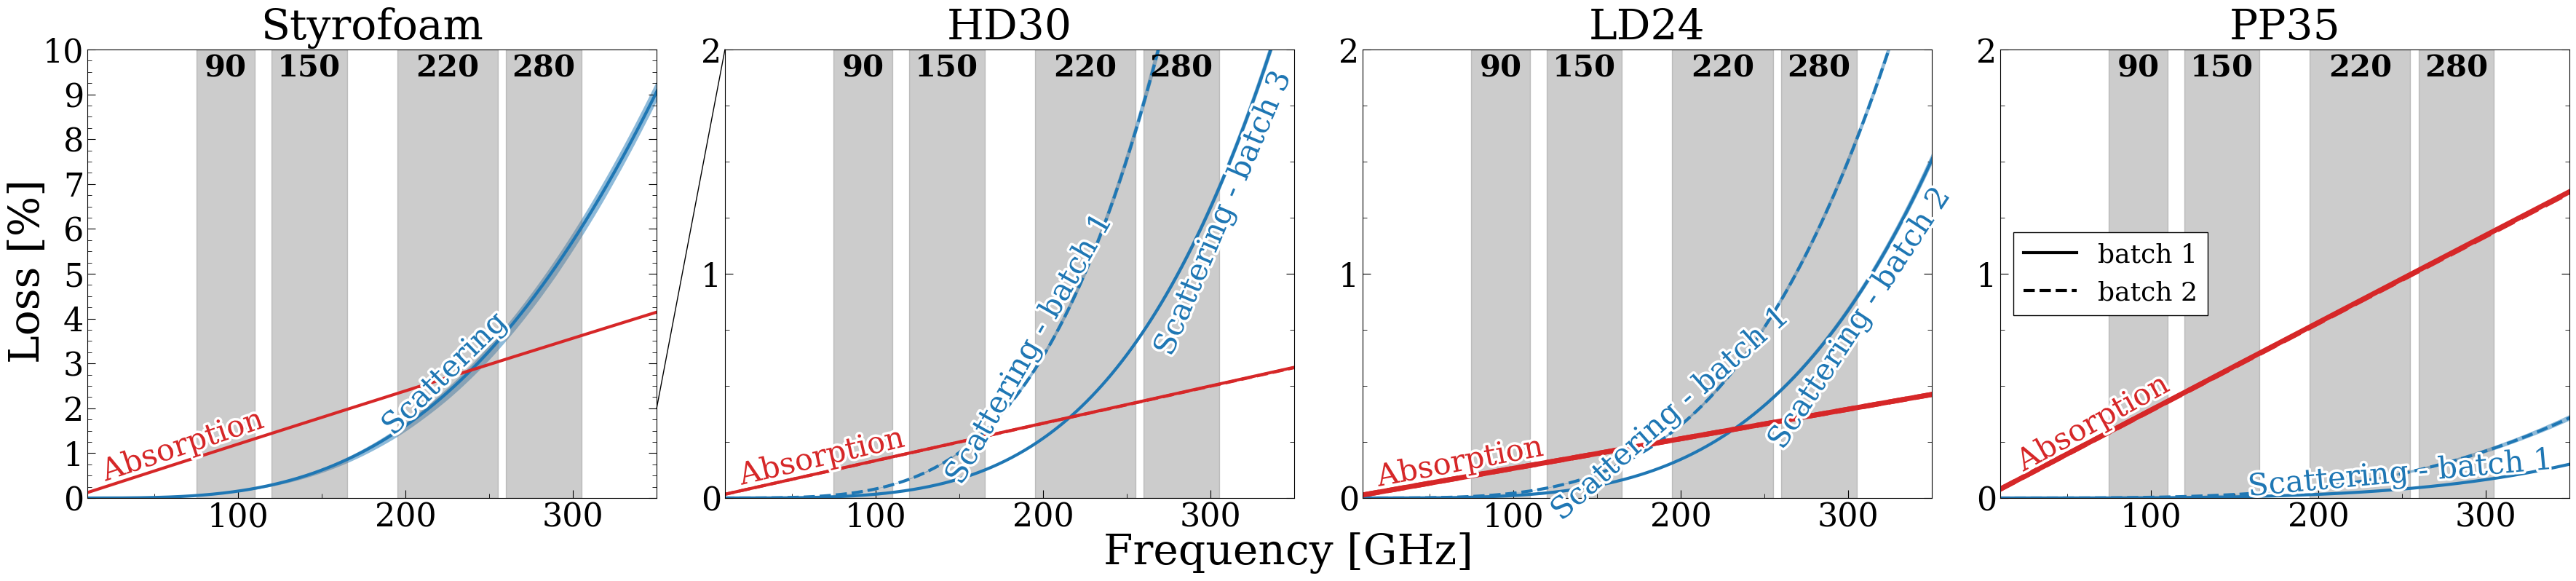

In [45]:
fig, axes = plt.subplots(1, 4, figsize=(44, 8), sharex=True)
loss_figure(fig, axes.flatten())

fig.supxlabel('Frequency [GHz]', fontsize=42, y=-0.02)
fig.supylabel('Loss [%]', fontsize=42, x=0.1)
plt.subplots_adjust(hspace=0.12, wspace=0.12)

plt.gcf().set_facecolor('white')
plt.savefig(f'components-poster_{TAG}.pdf', bbox_inches='tight', facecolor='white')
plt.show()

In [46]:
idx = np.argmin(np.abs(f - 280))

Scas   = np.array([comb_batches[f'HD30_batch{i}']["estimates"]["Sca"]['arr'][idx] for i in (1, 2, 3)])
sigmas = np.array([(comb_batches[f'HD30_batch{i}']["estimates"]["Sca"]['upper'][idx]
                    - comb_batches[f'HD30_batch{i}']["estimates"]["Sca"]['lower'][idx]) / 2 for i in (1, 2, 3)])

min_key, max_key = np.argmin(Scas), np.argmax(Scas)
print(f"At 280 GHz, min scattering is Batch {min_key+1} with value {Scas[min_key]:.4f} ± {sigmas[min_key]:.4f}, "
      f"max scattering is Batch {max_key+1} with value {Scas[max_key]:.4f} ± {sigmas[max_key]:.4f}, "
      f"difference: {(Scas[max_key] - Scas[min_key]):.4f} ± {(sigmas[min_key]**2 + sigmas[max_key]**2)**0.5:.4f}")

At 280 GHz, min scattering is Batch 3 with value 0.9922 ± 0.0151, max scattering is Batch 1 with value 2.3385 ± 0.0390, difference: 1.3464 ± 0.0419


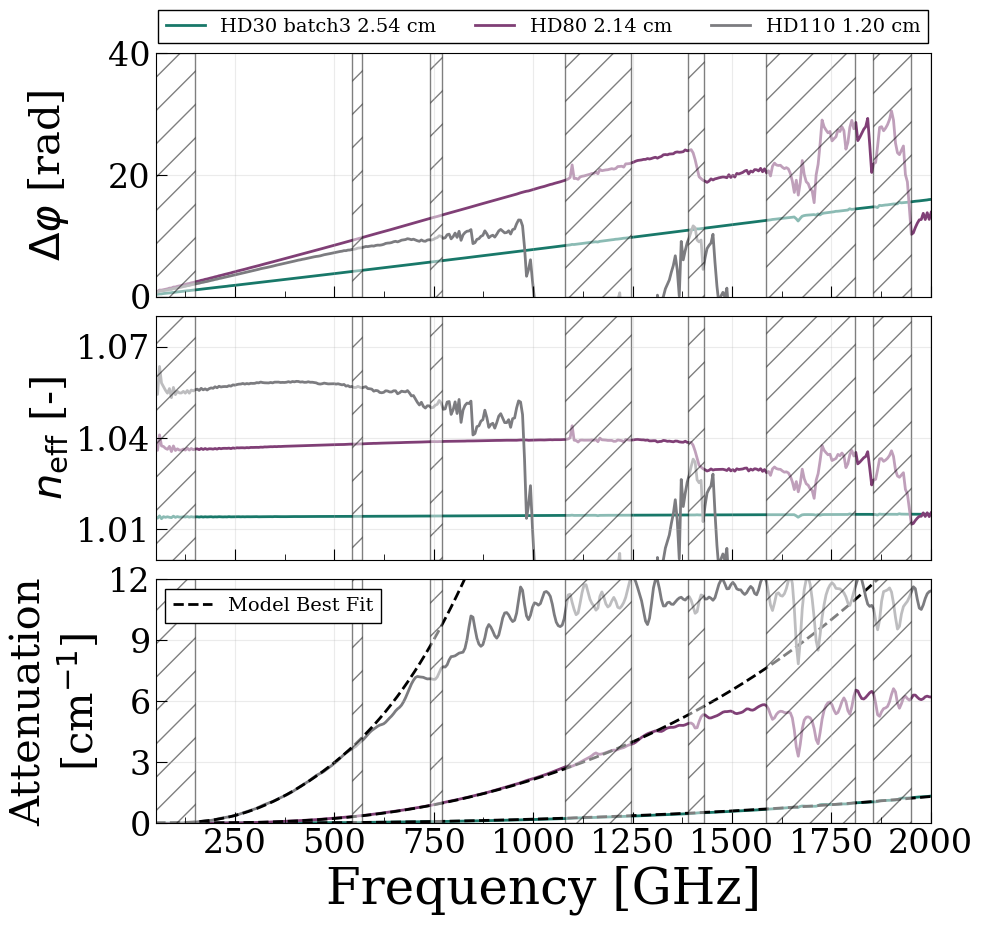

In [47]:
fig, axs = plt.subplots(
    3, 1, sharex=True, figsize=(10, 10),
    gridspec_kw=dict(height_ratios=[1, 1, 1], hspace=0.08)
)

for bname, b in batches.items():
    for sample in b:
        if sample not in ['HD30 batch3 2.54 cm', 'HD80 batch1 2.14 cm', 'HD110 batch1 1.20 cm']:
            continue


        f_    = b[sample]['f']
        color = b[sample]['color']

        label = sample.replace('batch1 ', '')

        axs[0].plot(f_, b[sample]['phase_diff'],  color=color, lw=2, zorder=-10)
        axs[1].plot(f_, b[sample]['n'],           color=color, lw=2, zorder=-10)
        axs[2].plot(f_, b[sample]['alpha'],       color=color, lw=2, label=label, zorder=-10)
        axs[2].plot(f, comb_batches[bname]['ns_alpha'], color='k', linestyle='--', lw=2, zorder=-10)

# Axis labels
axs[0].set_ylabel(r'$\Delta \varphi$ [rad]', fontsize=30)
axs[1].set_ylabel(r'$n_{\rm eff}$ [-]', fontsize=30)
axs[2].set_ylabel(f'Attenuation\n'+r'[cm$^{-1}$]', fontsize=30)
axs[2].set_xlabel('Frequency [GHz]')

# Limits / ticks
for ax in axs:
    for i, j in zip(mask_starts, mask_stops):
        ax.axvspan(i, j, facecolor='white', hatch='/', edgecolor='k', alpha=0.5, zorder=1)
    ax.set_xlim(50, 2000)
    # ax.set_xlim(0, 200)
    ax.grid(True, alpha=0.25)
axs[1].xaxis.set_major_locator(MultipleLocator(250))
axs[1].xaxis.set_minor_locator(MultipleLocator(125))

for i, j in zip(mask_starts, mask_stops):
    if ((i == 0) or (j >= 1500)):
        continue

style_handles = [Line2D([0], [0], color='k', lw=2, linestyle='--', label='Model Best Fit')]

axs[0].set_ylim(0, 40)
axs[0].set_yticks([0, 20, 40])
axs[1].set_ylim(1, 1.08)
axs[1].set_yticks([1.01, 1.04, 1.07])
axs[2].set_ylim(0, 12)
axs[2].set_yticks([0, 3, 6, 9, 12])
# Legend (single, clean)

handles, labels = axs[2].get_legend_handles_labels()

axs[0].legend(handles, labels, fontsize=14, loc='lower center', 
               bbox_to_anchor=(0.5, 1), ncol=3, framealpha=1, edgecolor='black', facecolor='white', fancybox=False)

axs[2].legend(handles=style_handles, fontsize=14, loc='upper left', framealpha=1, edgecolor='black', facecolor='white', fancybox=False)

# Remove x tick labels on upper panels (sharex already, but makes it cleaner)
plt.subplots_adjust(hspace=0.08)
axs[0].label_outer()
axs[1].label_outer()

fig.align_ylabels([axs[0], axs[1]])
plt.savefig(f"phase_plot-e_{TAG}.pdf", bbox_inches='tight', facecolor='white')
plt.show()

In [48]:
from fullmie_funcs import wedge_fraction
from scipy.constants import k as k_B

T_bb   = 273.0    # K  (room-temperature blackbody)
Npol   = 1        # one polarization
th_lo, th_hi = 40, 90   # warm-environment wedge [deg]

# ---- Dipole (Rayleigh) reference fraction in the wedge ------------------------
th = np.linspace(0, np.pi, 2001)
P_ray = (3/(16*np.pi)) * (1 + np.cos(th)**2)
sel_w = (th >= np.deg2rad(th_lo)) & (th <= np.deg2rad(th_hi))
F_Ray = 2*np.pi * np.trapezoid(P_ray[sel_w]*np.sin(th[sel_w]), th[sel_w])
print(f'Dipole (Rayleigh) fraction in {th_lo}-{th_hi} deg: {100*F_Ray:.1f}% of scattered power')

DISPLAY_MAP3 = [
    ('Styrofoam',    comb_batches['Styrofoam_batch1']),
    ('HD30 batch 1', comb_batches['HD30_batch1']),
    ('HD30 batch 2', comb_batches['HD30_batch2']),
    (r'HD30 batch 3$^\dagger$', comb_batches['HD30_batch3']),
    ('LD24 batch 1', comb_batches['LD24_batch1']),
    (r'LD24 batch 2$^\dagger$', comb_batches['LD24_batch2']),
    (r'LD15 batch 1$^\dagger$', comb_batches['LD15_batch1']),
    ('LD15 batch 2', comb_batches['LD15_batch2']),
    ('PP35 batch 1', comb_batches['PP35_batch1']),
    ('PP35 batch 2', comb_batches['PP35_batch2']),
]

# ---- Thin-shell kernel of each batch's fitted size distribution --------------
# Fraction of scattered power in the wedge (median d_med and s; independent of C and the wall thickness)
f_kern = np.arange(20, 341, 10.0)
for disp_name, b in DISPLAY_MAP3:
    _, d_med, s, _ = b['params']
    b['F_sca'] = np.interp(f, f_kern, wedge_fraction(f_kern, d_med, s, b['n_p'], th_lo, th_hi))
    print(f"{disp_name:<24}: wedge fraction {100*b['F_sca'][np.argmin(np.abs(f-90))]:.1f}% at 90 GHz, "
          f"{100*b['F_sca'][np.argmin(np.abs(f-280))]:.1f}% at 280 GHz")

# ---- Loading calculation ---------------------------------------------------
band_list  = ['90', '150', '220', '280']
bandwidths = [35.0, 45.0, 45.0, 65.0]

for disp_name, b in DISPLAY_MAP3:
    row_entries_odd = [f"\\multirow{{2}}{{*}}{{{disp_name}}}"]
    row_entries_even = ['']

    Sca = b['estimates']['Sca']   # percent scattered through w = 5 cm; lower/upper are the 16th/84th percentiles

    for i, (band, dnu) in enumerate(zip(band_list, bandwidths)):
        row_entries = row_entries_odd if i % 2 == 0 else row_entries_even

        lo_f, hi_f = band_windows_full[band]
        sel        = (f > lo_f) & (f < hi_f)

        # Optical loading from the warm baffle scattered onto the focal plane
        P_scatter       = Npol * k_B * T_bb * np.mean((Sca['arr'][sel]/100.0)   * b['F_sca'][sel]) * dnu * 1e21
        P_scatter_lower = P_scatter - Npol * k_B * T_bb * np.mean((Sca['lower'][sel]/100.0) * b['F_sca'][sel]) * dnu * 1e21
        P_scatter_upper = Npol * k_B * T_bb * np.mean((Sca['upper'][sel]/100.0) * b['F_sca'][sel]) * dnu * 1e21 - P_scatter

        row_entries.extend([format_unc(P_scatter, P_scatter_lower, P_scatter_upper)])

        # Optical loading from filter emission
        Abs = float(b['band_avgs'][(band, 'Abs')])
        T_RJ = T_bb * Abs / 100         # Temperature in K; converts from % to fraction
        P_ems = Npol * k_B * T_RJ * dnu * 1e21   # Power in pW
        P_tot = P_scatter + P_ems

        P_tot_lower = np.sqrt(P_scatter_lower**2 + (P_ems)**2) # Assume order unity uncertainty
        P_tot_upper = np.sqrt(P_scatter_upper**2 + (P_ems)**2)
        row_entries.extend([format_val(P_ems), format_unc(P_tot, P_tot_lower, P_tot_upper)])

    print(" & ".join(row_entries_odd) + r" \\")
    print(" & ".join(row_entries_even) + r" \\[6pt]")

Dipole (Rayleigh) fraction in 40-90 deg: 34.3% of scattered power


Styrofoam               : wedge fraction 37.6% at 90 GHz, 38.1% at 280 GHz


HD30 batch 1            : wedge fraction 34.4% at 90 GHz, 35.2% at 280 GHz


HD30 batch 2            : wedge fraction 34.5% at 90 GHz, 36.1% at 280 GHz


HD30 batch 3$^\dagger$  : wedge fraction 34.4% at 90 GHz, 35.2% at 280 GHz


LD24 batch 1            : wedge fraction 34.6% at 90 GHz, 36.4% at 280 GHz


LD24 batch 2$^\dagger$  : wedge fraction 34.4% at 90 GHz, 35.2% at 280 GHz


LD15 batch 1$^\dagger$  : wedge fraction 36.3% at 90 GHz, 38.6% at 280 GHz


LD15 batch 2            : wedge fraction 35.1% at 90 GHz, 37.9% at 280 GHz


PP35 batch 1            : wedge fraction 34.4% at 90 GHz, 34.6% at 280 GHz


PP35 batch 2            : wedge fraction 34.7% at 90 GHz, 37.6% at 280 GHz
\multirow{2}{*}{Styrofoam} & $0.061^{+0.004}_{-0.009}$ & $1.47$ & $2^{+1}_{-1}$ & $1.56^{+0.06}_{-0.11}$ & $4.55$ & $6^{+5}_{-5}$ \\
 & $0.35^{+0.02}_{-0.04}$ & $2.90$ & $3^{+3}_{-3}$ & $4.5^{+0.1}_{-0.2}$ & $8.23$ & $13^{+8}_{-8}$ \\[6pt]
\multirow{2}{*}{HD30 batch 1} & $0.0144^{+0.0003}_{-0.0003}$ & $0.20$ & $0.2^{+0.2}_{-0.2}$ & $0.61^{+0.01}_{-0.01}$ & $0.63$ & $1.2^{+0.6}_{-0.6}$ \\
 & $0.102^{+0.002}_{-0.002}$ & $0.40$ & $0.5^{+0.4}_{-0.4}$ & $2.11^{+0.04}_{-0.03}$ & $1.15$ & $3^{+1}_{-1}$ \\[6pt]
\multirow{2}{*}{HD30 batch 2} & $0.0126^{+0.0011}_{-0.0009}$ & $0.20$ & $0.2^{+0.2}_{-0.2}$ & $0.52^{+0.04}_{-0.03}$ & $0.64$ & $1.2^{+0.6}_{-0.6}$ \\
 & $0.088^{+0.007}_{-0.006}$ & $0.40$ & $0.5^{+0.4}_{-0.4}$ & $1.79^{+0.10}_{-0.09}$ & $1.15$ & $3^{+1}_{-1}$ \\[6pt]
\multirow{2}{*}{HD30 batch 3$^\dagger$} & $0.00604^{+0.00011}_{-0.00010}$ & $0.20$ & $0.2^{+0.2}_{-0.2}$ & $0.258^{+0.004}_{-0.004}$ & $0.64$ & $0.

# Uncertainty analysis

Styrofoam_batch1


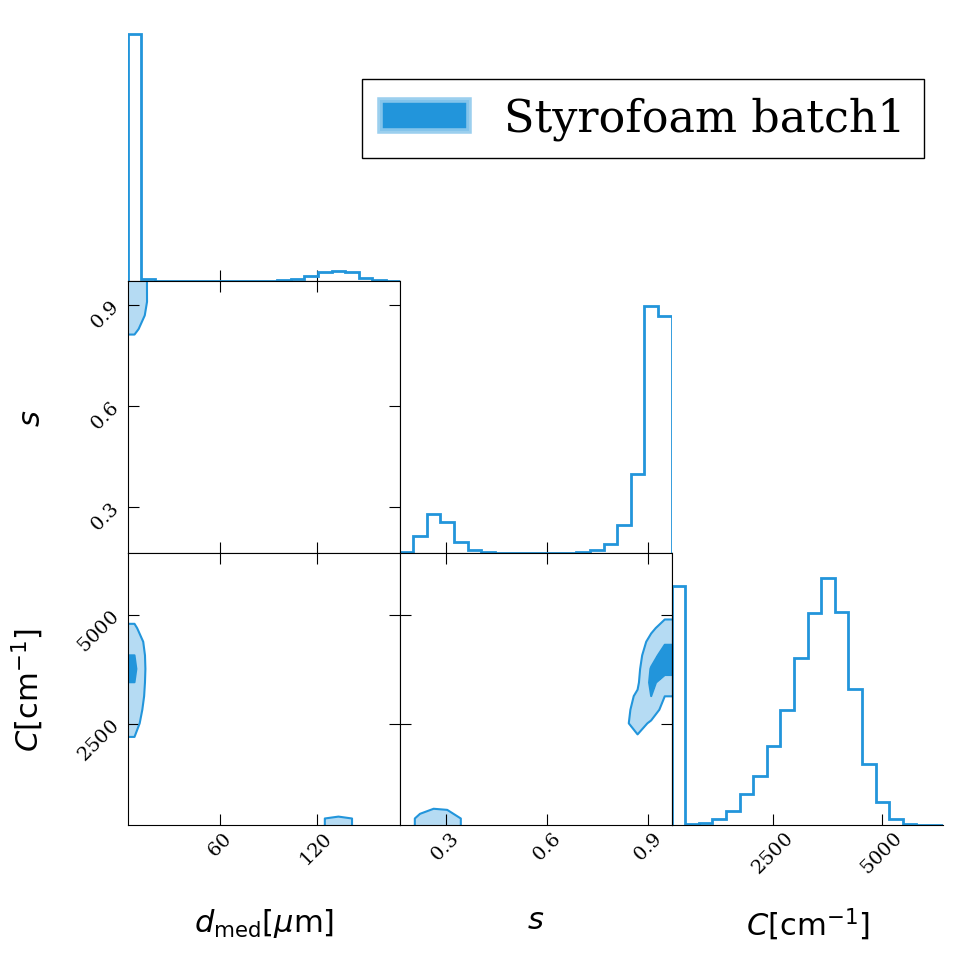

In [49]:
param_names = [r'$d_{\mathrm{med}} [\mu\mathrm{m}]$', r'$s$', r'$C [\mathrm{cm}^{-1}]$']

figure = plt.figure(figsize=(10,10))

for bname, b in comb_batches.items():
    if bname not in styro_batches:
        continue

    print(bname)

    samples      = b['samples'][:, 1:] # tan(delta) is fixed
    color        = b['color']

    fig = corner.corner(samples, 
                    show_titles=False, 
                    labels = param_names,            
                    use_math_text = True,
                    label_kwargs={"fontsize": 22},
                    max_n_ticks=3,
                    plot_datapoints=False,
                    show_median=False,
                    show_mean=False,
                    plot_density=False,
                    levels=[0.393, 0.864],
                    fill_contours=True,
                    color=color,
                    hist_kwargs={"linewidth": 2},
                    fig=figure)

for i, ax in enumerate(fig.axes):
    ax.tick_params(axis='both', labelsize=14)
    if i == 0:
        ax.spines['left'].set_visible(False)
    row, col = divmod(i, len(param_names))
    if col < row:
        ax.xaxis.set_tick_params(which='both', direction='in', top=True)
        ax.yaxis.set_tick_params(which='both', direction='in', right=True)
    if col == row:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.set_facecolor('white')

figure.canvas.draw()

for ax in figure.get_axes():
    if ax.xaxis.get_offset_text().get_text() != '':
        offset = ax.xaxis.get_offset_text().get_text()
        ax.set_xlabel(ax.get_xlabel() + f' {offset}', fontsize=22)
        ax.xaxis.get_offset_text().set_visible(False)
        
    if ax.yaxis.get_offset_text().get_text() != '':
        offset = ax.yaxis.get_offset_text().get_text()
        ax.set_ylabel(ax.get_ylabel() + f' {offset}', fontsize=22)
        ax.yaxis.get_offset_text().set_visible(False)

handles = get_corner_handles(styro_batches)

fig.legend(handles=handles, loc='upper right', bbox_to_anchor=(0.95, 0.90), fontsize=32, edgecolor='black', facecolor='white', framealpha=1, fancybox=False)

fig.subplots_adjust(hspace=0, wspace=0)
plt.gcf().set_facecolor('white')
# plt.savefig('styro_params-b.pdf', bbox_inches='tight', facecolor='white')
plt.show()

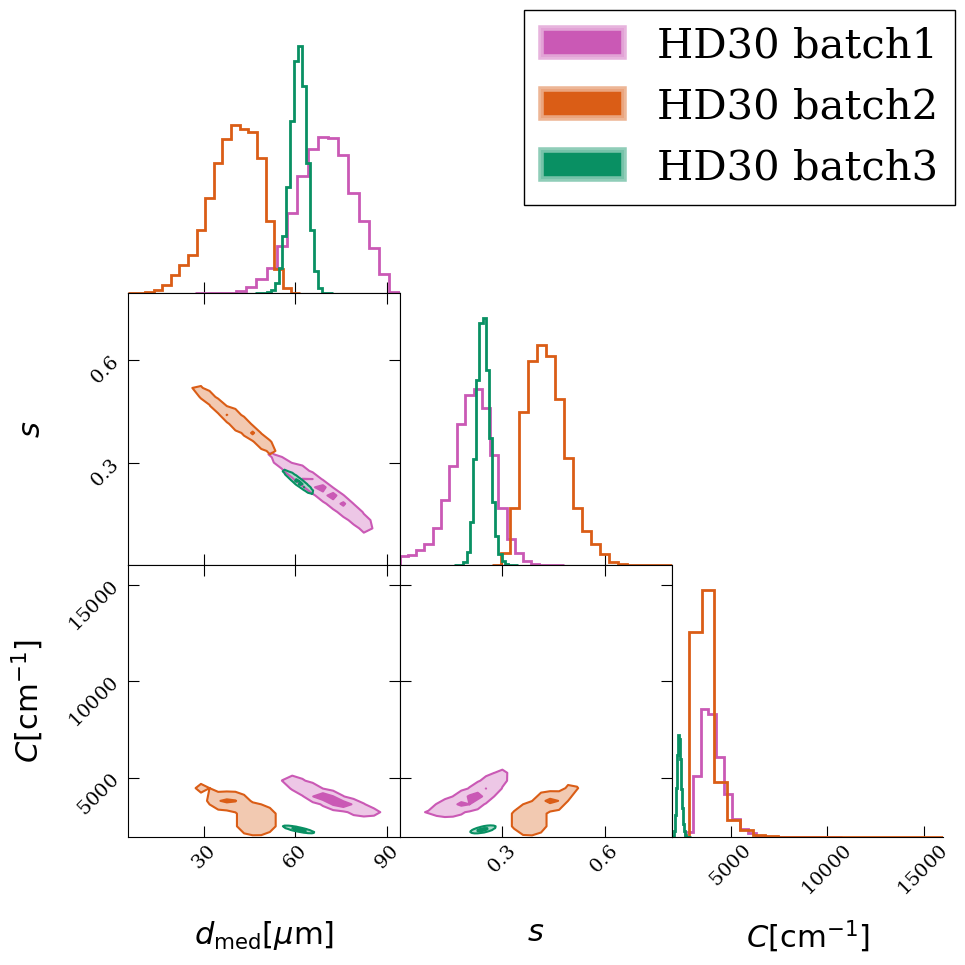

In [50]:
param_names = [r'$d_{\mathrm{med}} [\mu\mathrm{m}]$', r'$s$', r'$C [\mathrm{cm}^{-1}]$']

plot_batches = [*HD30_batches]

figure = plt.figure(figsize=(10,10))

for bname, b in comb_batches.items():
    if bname not in plot_batches:
        continue

    samples      = b['samples'][:, 1:] # tan(delta) is fixed
    color        = b['color']

    fig = corner.corner(samples, 
                    show_titles=False, 
                    labels = param_names,            
                    use_math_text = True,
                    label_kwargs={"fontsize": 22},
                    max_n_ticks=3,
                    plot_datapoints=False,
                    show_median=False,
                    show_mean=False,
                    plot_density=False,
                    levels=[0.393, 0.864],
                    fill_contours=True,
                    color=color,
                    hist_kwargs={"linewidth": 2},
                    fig=figure)

for i, ax in enumerate(fig.axes):
    ax.tick_params(axis='both', labelsize=14)
    if i == 0:
        ax.spines['left'].set_visible(False)
    row, col = divmod(i, len(param_names))
    if col < row:
        ax.xaxis.set_tick_params(which='both', direction='in', top=True)
        ax.yaxis.set_tick_params(which='both', direction='in', right=True)
    if col == row:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.set_facecolor('white')

figure.canvas.draw()

for ax in figure.get_axes():
    if ax.xaxis.get_offset_text().get_text() != '':
        offset = ax.xaxis.get_offset_text().get_text()
        ax.set_xlabel(ax.get_xlabel() + f' {offset}', fontsize=22)
        ax.xaxis.get_offset_text().set_visible(False)
        
    if ax.yaxis.get_offset_text().get_text() != '':
        offset = ax.yaxis.get_offset_text().get_text()
        ax.set_ylabel(ax.get_ylabel() + f' {offset}', fontsize=22)
        ax.yaxis.get_offset_text().set_visible(False)

handles = get_corner_handles(plot_batches)

fig.legend(handles=handles, loc='upper right', bbox_to_anchor=(0.98, 0.98), fontsize=30, edgecolor='black', facecolor='white', framealpha=1, fancybox=False)

fig.subplots_adjust(hspace=0, wspace=0)
plt.gcf().set_facecolor('white')
# plt.savefig('styro_params-b.pdf', bbox_inches='tight', facecolor='white')
plt.show()

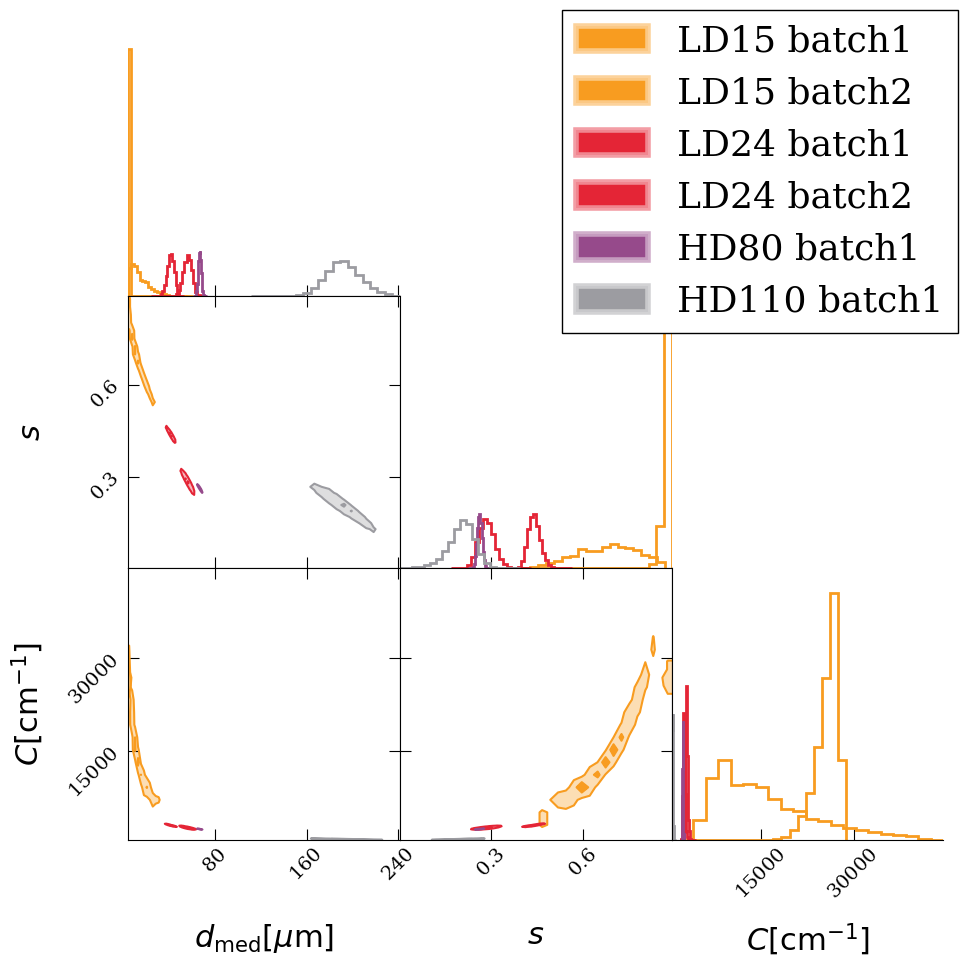

In [51]:
param_names = [r'$d_{\mathrm{med}} [\mu\mathrm{m}]$', r'$s$', r'$C [\mathrm{cm}^{-1}]$']

plot_batches = ['LD15_batch1', 'LD15_batch2', 'LD24_batch1', 'LD24_batch2', 'HD80_batch1', 'HD110_batch1'] 

figure = plt.figure(figsize=(10,10))

for bname, b in comb_batches.items():
    if bname not in plot_batches:
        continue

    samples      = b['samples'][:, 1:] # tan(delta) is fixed
    color        = b['color']

    hatch = '//' if 'batch2' in bname and bname in other_zote_keys else None

    fig = corner.corner(samples, 
                    show_titles=False, 
                    labels = param_names,            
                    use_math_text = True,
                    label_kwargs={"fontsize": 22},
                    max_n_ticks=3,
                    plot_datapoints=False,
                    show_median=False,
                    show_mean=False,
                    plot_density=False,
                    levels=[0.393, 0.864],
                    fill_contours=True,
                    color=color,
                    hist_kwargs={"linewidth": 2},
                    # contourf_kwargs={"hatches": [hatch, hatch, hatch]},
                    fig=figure)

for i, ax in enumerate(fig.axes):
    ax.tick_params(axis='both', labelsize=14)
    if i == 0:
        ax.spines['left'].set_visible(False)
    row, col = divmod(i, len(param_names))
    if col < row:
        ax.xaxis.set_tick_params(which='both', direction='in', top=True)
        ax.yaxis.set_tick_params(which='both', direction='in', right=True)
    if col == row:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.set_facecolor('white')

figure.canvas.draw()

for ax in figure.get_axes():
    if ax.xaxis.get_offset_text().get_text() != '':
        offset = ax.xaxis.get_offset_text().get_text()
        ax.set_xlabel(ax.get_xlabel() + f' {offset}', fontsize=22)
        ax.xaxis.get_offset_text().set_visible(False)
        
    if ax.yaxis.get_offset_text().get_text() != '':
        offset = ax.yaxis.get_offset_text().get_text()
        ax.set_ylabel(ax.get_ylabel() + f' {offset}', fontsize=22)
        ax.yaxis.get_offset_text().set_visible(False)

handles = get_corner_handles(plot_batches)


fig.legend(handles=handles, loc='upper right', bbox_to_anchor=(0.98, 0.98), fontsize=26, edgecolor='black', facecolor='white', framealpha=1, fancybox=False)

fig.subplots_adjust(hspace=0, wspace=0)
plt.gcf().set_facecolor('white')
# plt.savefig('styro_params-b.pdf', bbox_inches='tight', facecolor='white')
plt.show()

PP35_batch1
PP35_batch2


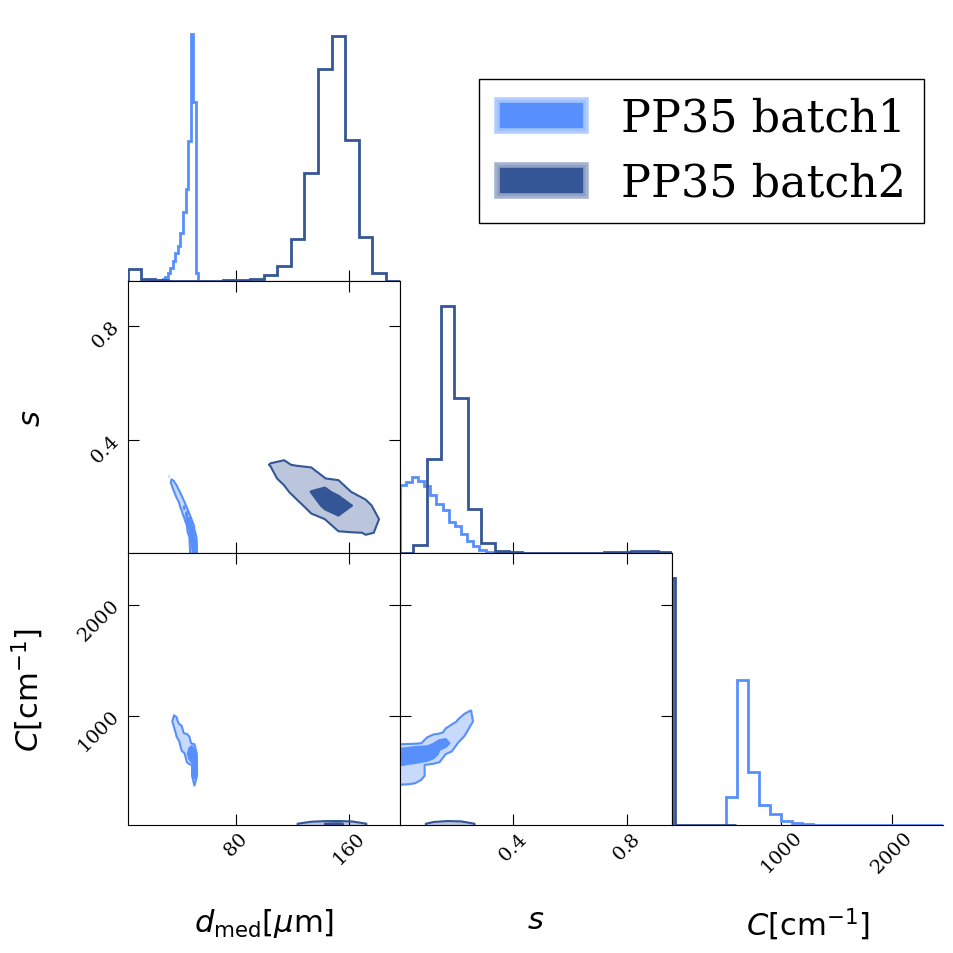

In [52]:
param_names = [r'$d_{\mathrm{med}} [\mu\mathrm{m}]$', r'$s$', r'$C [\mathrm{cm}^{-1}]$']

figure = plt.figure(figsize=(10,10))

for bname, b in comb_batches.items():
    if bname not in ('PP35_batch1', 'PP35_batch2'):
        continue

    print(bname)

    samples      = b['samples'][:, 1:] # tan(delta) is fixed
    color        = b['color']

    fig = corner.corner(samples, 
                    show_titles=False, 
                    labels = param_names,            
                    use_math_text = True,
                    label_kwargs={"fontsize": 22},
                    max_n_ticks=3,
                    plot_datapoints=False,
                    show_median=False,
                    show_mean=False,
                    plot_density=False,
                    levels=[0.68, 0.95],
                    fill_contours=True,
                    color=color,
                    hist_kwargs={"linewidth": 2},
                    fig=figure)

for i, ax in enumerate(fig.axes):
    ax.tick_params(axis='both', labelsize=14)
    if i == 0:
        ax.spines['left'].set_visible(False)
    row, col = divmod(i, len(param_names))
    if col < row:
        ax.xaxis.set_tick_params(which='both', direction='in', top=True)
        ax.yaxis.set_tick_params(which='both', direction='in', right=True)
    if col == row:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.set_facecolor('white')

figure.canvas.draw()

for ax in figure.get_axes():
    if ax.xaxis.get_offset_text().get_text() != '':
        offset = ax.xaxis.get_offset_text().get_text()
        ax.set_xlabel(ax.get_xlabel() + f' {offset}', fontsize=22)
        ax.xaxis.get_offset_text().set_visible(False)
        
    if ax.yaxis.get_offset_text().get_text() != '':
        offset = ax.yaxis.get_offset_text().get_text()
        ax.set_ylabel(ax.get_ylabel() + f' {offset}', fontsize=22)
        ax.yaxis.get_offset_text().set_visible(False)

handles = get_corner_handles(['PP35_batch1', 'PP35_batch2'])

fig.legend(handles=handles, loc='upper right', bbox_to_anchor=(0.95, 0.90), fontsize=32, edgecolor='black', facecolor='white', framealpha=1, fancybox=False)

fig.subplots_adjust(hspace=0, wspace=0)
plt.gcf().set_facecolor('white')
# plt.savefig('styro_params-b.pdf', bbox_inches='tight', facecolor='white')
plt.show()

In [53]:
# for bname, b in batches.items():
#     # if bname != 'HD110_batch1':
#     #     continue
#     n_eff  = comb_batches[bname]['n_eff']
#     params = comb_batches[bname]['params']
#     mie_g, f_m = comb_batches[bname]['mie_g'], comb_batches[bname]['f_m']
#     for j, sample in enumerate(b):
#         fig, axes = plt.subplots(2, 1, figsize=(6, 6), sharex=True, sharey='row')
#         ax0, ax1 = axes

#         plt.xlim(20, 2000)
#         ax0.set_ylim(0, 1.02)
#         ax1.set_ylim(0, 2.5)

#         ax0.set_ylabel('Transmittance [-]', fontsize=18)
#         ax1.set_ylabel('Attenuation [cm$^{-1}$]', fontsize=18)

#         lw = 3

#         ax1.set_xlabel('Frequency [GHz]', fontsize=28)

#         f_          = b[sample]['f_binned']
#         t           = b[sample]['t_binned']
#         alpha       = b[sample]['alpha_binned']
#         err         = b[sample]['err_tot']
#         width       = b[sample]['width']
#         alpha_err   = err/(width * t)
#         color       = b[sample]['color']


#         mask   = b[sample]['mask']
#         boxnum = b[sample]['boxnum']

#         min_len = min(len(b[sample]['alpha']) for sample in b)

#         ns_T = MIE_njit(f_, params, width, n_eff, mie_g, f_m)
#         redchi2 = float(np.sum((ns_T - t) ** 2 / err ** 2)) / (len(f_) - len(params))

#         ax0.errorbar(f_, t, yerr=err, color='k', fmt='s', ms=6, capsize=3, zorder=-10)
#         ax1.errorbar(f_, alpha, yerr=alpha_err, color='k', fmt='s', ms=6, capsize=3, label='Data', zorder=-10)

#         ns_alpha = comb_batches[bname]['ns_alpha']
#         ns_T     = np.exp(-width*ns_alpha)

#         ax0.plot(f, ns_T, color='tab:red', linestyle='--', label='Best fit', lw=2, zorder=10)

#         ax1.plot(f, ns_alpha, color='tab:red', linestyle='--', label='Best fit', lw=2, zorder=10)

#         params     = comb_batches[bname]['params']
#         n_eff      = comb_batches[bname]['n_eff']
#         lt_nominal = comb_batches[bname]['upper_params'][0]
#         lt_est     = comb_batches[bname]['lt']

#         alpha_nominal   = MIE_alpha_njit(f, np.array([lt_nominal, *params[1:]]), n_eff, mie_g, f_m)
#         alpha_est       = MIE_alpha_njit(f, np.array([lt_est, *params[1:]]), n_eff, mie_g, f_m)

#         T_nominal       = np.exp(-width*alpha_nominal)
#         T_est           = np.exp(-width*alpha_est)

#         ax0.plot(f, T_nominal, color='tab:orange', linestyle='--', label=r'$2\sigma$ nominal $\tan\delta$', lw=2, zorder=10)
#         ax0.plot(f, T_est, color='tab:blue', linestyle='--', label=r'theoretical $\tan\delta$', lw=2, zorder=10)

#         ax1.plot(f, alpha_nominal, color='tab:orange', linestyle='--', label=r'$2\sigma$ nominal $\tan\delta$', lw=2, zorder=10)
#         ax1.plot(f, alpha_est, color='tab:blue', linestyle='--', label=r'Theoretical $\tan\delta$', lw=2, zorder=10)

#         for ax in axes:
#             for i, j in zip(mask_starts, mask_stops):
#                 ax.axvspan(i, j, color='lightgray', alpha=0.7)

#         handles = ax1.get_legend_handles_labels()[0]

#         # fig.legend(handles=handles, fontsize=20, frameon=True, bbox_to_anchor=(0.9, 0.5), loc='center left', ncol=1)

#         ax0.set_yticks([0, 1])
#         ax1.set_yticks([0, 1, 2])
        
#         ax0.set_title(rf'{sample}', fontsize=20)
#         ax1.annotate(rf'$\chi^2/{{\rm dof}}={redchi2:.1f}$', xy=(0.02, 0.87), ha='left', xycoords='axes fraction', fontsize=18)
#         ax1.annotate(f'Best-fit = {params[0]:.1e}', xy=(0.02, 0.75), ha='left', color='tab:red', xycoords='axes fraction', fontsize=18)
#         ax1.annotate(rf'95th percentile = {lt_nominal:.1e}', xy=(0.02, 0.63), ha='left', color='tab:orange', xycoords='axes fraction', fontsize=18)
#         ax1.annotate(rf'Theoretical = {lt_est:.1e}', xy=(0.02, 0.51), ha='left', color='tab:blue', xycoords='axes fraction', fontsize=18)

#         plt.gcf().set_facecolor('white')
#         plt.subplots_adjust(wspace=0.07, hspace=0.07)
#         plt.show()

In [54]:
print(comb_batches['LD24_batch2']['params'])

[1.24691898e-05 5.57037927e+01 2.83947320e-01 2.62193733e+03]


In [55]:
print(comb_batches['HD30_batch1']['params'])
print(comb_batches['HD30_batch3']['params'])

[1.56217006e-05 6.99492488e+01 2.15500778e-01 3.95119504e+03]
[1.57058542e-05 6.10381652e+01 2.44678758e-01 2.30471963e+03]


# 2 THz Comparison: LD24 vs Styrofoam vs PP35

In [56]:
## LD24 vs Styrofoam vs PP35 at 2 THz (f = 2000 GHz, the top of the measured band)
idx_2thz = np.argmin(np.abs(f - 2000))
print(f"Nearest sampled frequency to 2 THz: {f[idx_2thz]:.0f} GHz\n")

def alpha_at_2thz(bname):
    """Total attenuation coefficient [1/cm] at 2 THz: median with 1-sigma bounds."""
    b = comb_batches[bname]
    lo, med, up = b['alpha_lower'][idx_2thz], b['ns_alpha'][idx_2thz], b['alpha_upper'][idx_2thz]
    return med, med - lo, up - med

def T5cm_at_2thz(bname):
    """5 cm-assembly transmission at 2 THz: median with 1-sigma bounds."""
    b = comb_batches[bname]
    T_lower, T_med, T_upper = b['T_lower_5cm'][idx_2thz], b['ns_T_5cm'][idx_2thz], b['T_upper_5cm'][idx_2thz]
    return T_med, T_med - T_lower, T_upper - T_med

materials = {
    'Styrofoam': 'Styrofoam_batch1',
    'LD24':      'LD24_batch2',
    'PP35 b1':   'PP35_batch1',
    'PP35 b2':   'PP35_batch2',
}

for name, bname in materials.items():
    a, a_lo, a_up = alpha_at_2thz(bname)
    T, T_lo, T_up = T5cm_at_2thz(bname)
    print(f"{name:<10} @ 2 THz: alpha = {a:.3f} +{a_up:.3f}/-{a_lo:.3f} 1/cm  |  T(5 cm) = {100*T:.2f} +{100*T_up:.2f}/-{100*T_lo:.2f} %")

def compare(name1, name2):
    a1, a1_lo, a1_up = alpha_at_2thz(materials[name1])
    a2, a2_lo, a2_up = alpha_at_2thz(materials[name2])
    T1, T1_lo, T1_up = T5cm_at_2thz(materials[name1])
    T2, T2_lo, T2_up = T5cm_at_2thz(materials[name2])

    a_diff    = a1 - a2
    a_diff_lo = np.sqrt(a1_lo**2 + a2_up**2)
    a_diff_up = np.sqrt(a1_up**2 + a2_lo**2)

    T_diff    = 100 * (T1 - T2)
    T_diff_lo = 100 * np.sqrt(T1_lo**2 + T2_up**2)
    T_diff_up = 100 * np.sqrt(T1_up**2 + T2_lo**2)

    print(f"\n{name1} vs {name2} @ 2 THz:")
    print(f"  Delta alpha  = {a_diff:+.3f} +{a_diff_up:.3f}/-{a_diff_lo:.3f} 1/cm "
          f"({name1} is {'more' if a_diff > 0 else 'less'} lossy per cm than {name2})")
    print(f"  Delta T(5cm) = {T_diff:+.2f} +{T_diff_up:.2f}/-{T_diff_lo:.2f} percentage points "
          f"({name1} transmits {'more' if T_diff > 0 else 'less'} than {name2} through a 5 cm assembly)")

compare('LD24', 'Styrofoam')
compare('PP35 b1', 'Styrofoam')
compare('PP35 b1', 'LD24')
compare('PP35 b2', 'LD24')
compare('PP35 b2', 'PP35 b1')

Nearest sampled frequency to 2 THz: 2000 GHz

Styrofoam  @ 2 THz: alpha = 2.332 +0.019/-0.020 1/cm  |  T(5 cm) = 0.00 +0.00/-0.00 %
LD24       @ 2 THz: alpha = 0.832 +0.005/-0.005 1/cm  |  T(5 cm) = 1.56 +0.04/-0.04 %
PP35 b1    @ 2 THz: alpha = 0.173 +0.002/-0.002 1/cm  |  T(5 cm) = 42.08 +0.36/-0.38 %
PP35 b2    @ 2 THz: alpha = 0.107 +0.002/-0.001 1/cm  |  T(5 cm) = 58.58 +0.40/-0.44 %

LD24 vs Styrofoam @ 2 THz:
  Delta alpha  = -1.500 +0.021/-0.020 1/cm (LD24 is less lossy per cm than Styrofoam)
  Delta T(5cm) = +1.56 +0.04/-0.04 percentage points (LD24 transmits more than Styrofoam through a 5 cm assembly)

PP35 b1 vs Styrofoam @ 2 THz:
  Delta alpha  = -2.159 +0.020/-0.019 1/cm (PP35 b1 is less lossy per cm than Styrofoam)
  Delta T(5cm) = +42.08 +0.36/-0.38 percentage points (PP35 b1 transmits more than Styrofoam through a 5 cm assembly)

PP35 b1 vs LD24 @ 2 THz:
  Delta alpha  = -0.659 +0.005/-0.005 1/cm (PP35 b1 is less lossy per cm than LD24)
  Delta T(5cm) = +40.52 +0.36/-0